# Прогнозирование движения акций S&P 500
## Курсовая работа: исправления по рецензиям, 2026-11-01

**Новая тетрадь на основе final.** Исходные v6/final не изменяются.
Сохранены порядок разделов, 99 ячеек, все 273 признака и набор алгоритмов.

Цель — оценить вероятность того, что акция хотя бы в один из следующих
10 торговых дней опередит ценовой индекс на **2 процентных пункта**.
Это событие достижения уровня, а не доходность ровно в день 10 и не обещание прибыли.

**Изменения методики по рецензиям:** загрузка фиксированных 502 тикеров через
yfinance; CV по датам с purge 10 дней; полная наблюдаемость будущего для метки;
expanding с переобучением каждые 21 день; общие OOS-даты и gap=10;
BH для ANOVA; смежные блоки bootstrap (>=2000); Jensen alpha, beta, IR и оборот;
исполнение на следующем закрытии и ежедневная переоценка.

**Ответы на вопросы:** k=10, равные веса; при удержании 21 день используются
те же прогнозы **10-дневной** модели, целевая переменная не меняется.
260 дней — прогрев X_260, не необходимый разрыв train/test. Код final
задавал такой разрыв явно; здесь для известных меток достаточно 10 дней purge.
GitHub: подготовлен воспроизводимый код, публикация пользователем; push не выполняется.

**Числа статьи 170/378475 и старые p-values не являются результатами этой версии.**
Все выводы строятся заново. 502 — запрошенная вселенная, фактическая доступность
и пригодность показаны в manifest и воронке; survivorship bias снимка 2024 остаётся.

Порядок: 1. Предметная область → 2. Данные и 273 признака →
3. Модели, CV и эксперименты → 4. SHAP → 5. Выводы и ограничения.


---
# 1. Анализ предметной области

## 1.1 Априорные знания и ограничения предметной области

Индекс S&P 500 включает 500 крупнейших публично торгуемых компаний США и является одним из основных бенчмарков мирового фондового рынка.

**Ключевые априорные знания:**
- **Относительная доходность** - разница между доходностью акции и доходностью рыночного индекса - отражает способность акции опережать рынок (т.н. "альфа"). Именно это, а не абсолютная цена, интересует портфельного управляющего.
- **Momentum-эффект**: доходности за разные горизонты (от 1 дня до 1 года) несут информацию о будущем движении - эффект подтверждён в литературе (Jegadeesh & Titman, 1993).
- Использование **только ценовых данных** (без фундаментальных показателей) позволяет избежать ретроспективной утечки, характерной для статических финансовых отчётов.
- Задача классификации относительной доходности.

**Ограничения:**
- В датасете присутствуют только компании, входящие в индекс на момент сбора данных (2024 год); компании, выбывшие из индекса, не учтены. Как отмечают Htun et al. (2024), это ограничение снижает обобщаемость результатов.
- **Гипотеза эффективного рынка** (Fama, 1995) утверждает, что систематическое предсказание цен невозможно. Наша работа следует подходу Htun et al. (2024), которые показали, что ML-методы статистически значимо превосходят случайный выбор акций.
- Отсутствие данных о сентименте, новостях и макроэкономических шоках.

## 1.2 Цель анализа, критерии качества и процедура проверки

**Цель:** Предсказать бинарную метку - обгонит ли акция индекс S&P 500 более чем на **2%** в течение следующих **10 торговых дней** (класс 1) или нет (класс 0).

**Обоснование целевой переменной (по Htun et al., 2024):**  
Порог 2% выбран потому, что при горизонте 10 торговых дней именно это значение обеспечивает **баланс классов** (p(1) ≈ 0.49, p(0) ≈ 0.51). Экономическая интерпретация: если акция достигает относительной доходности >2%, инвестор может зафиксировать прибыль. Порог также покрывает типичные транзакционные издержки раунд-трипа.

**Критерии качества:**
- **ROC-AUC** - основная метрика для сравнения моделей при кросс-валидации.
- **Precision@k** - для отбора топ-k акций, которые скорее всего выростят.
- **Average Precision (AP)** - основная бизнес-метрика на тесте (площадь PR-кривой).
- **Accuracy, Precision, Recall** - для сравнения с результатами Htun et al. (2024).
- **F1-score** - вспомогательная при фиксированном пороге 0.5.

**Процедура проверки:**
- Временное разбиение: 80% train / 20% test (по хронологии).
- Кросс-валидация: `TimeSeriesSplit(n_splits=5)`.
- Скользящее окно: метод обучения из статьи Htun et al.

## 1.3 Пользовательские сценарии

**Сценарий 1 - Скрининг акций:**  
Аналитик ежедневно запускает модель и получает список акций, прогнозируемых как класс 1 (опережение индекса >2% в следующие 10 дней) - кандидатов для включения в портфель.

**Сценарий 2 - Сравнительный анализ методов:**  
Data scientist сравнивает алгоритмы и методы обучения по единой процедуре выбирает лучший для реального применения.

**Сценарий 3 - Личный торговый робот:**  
Модель получает данные через api trader viewer и с помощью автоматизации (airflow) выдает каждый результаты по топ 10 акциям s&p 500 в тг

**Сценарий 4 - Консультации по росту акций:**  
Модель получает данные через api trader viewer и с помощью автоматизации (airflow) выдает каждый результаты по топ 10 акциям s&p 500 в тг. По подписке человек может получить персональную консультацию от модели по росту топ 10 акций в тг, которые точно вырастут более чем на 2% относительно индекса s&p 500 за следующие 10 торговых дней


---
# 2. Формирование и подготовка данных для анализа
## 2.1 Описание используемых данных

Для нового опыта **весь** фиксированный список из `sp500_companies.csv`
загружается через yfinance, включая индекс `^GSPC`. Состав индекса заново
из интернета не берётся. Фундаментальные показатели не входят в модель;
сектор используется только для описательного анализа.

Цены: `Close`, `auto_adjust=False` (ценовая доходность без дивидендов).
Нельзя молча смешивать Close и Adj Close. Период запроса фиксирован:
2014-12-22…2024-12-20, `end=2024-12-21` исключительный.
Старые CSV сохраняются для аудита. Ошибки загрузки перечисляются явно;
нет автоматической замены делистингованной компании её преемником.


In [11]:
# Импорт библиотек
import sys
import json
import os
import random
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
os.environ.setdefault('MPLCONFIGDIR', str(Path.cwd() / '.mplconfig_review'))
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)
%matplotlib inline

from sklearn.model_selection import TimeSeriesSplit, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay,
    roc_auc_score, f1_score, average_precision_score,
    precision_score, recall_score
)
from xgboost import XGBClassifier
import shap
from flaml import AutoML as FlamlAutoML

from scipy.stats import randint, uniform, norm, wilcoxon, t as student_t

# ── Воспроизводимость ────────────────────────────────────────────────────────
SEED = 42


def set_seed(seed: int = SEED) -> None:
    """Фиксирует все источники случайности, доступные в ноутбуке."""
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)


set_seed(SEED)

# ── Пути ─────────────────────────────────────────────────────────────────────
# Ноутбук запускается из notebooks/, данные лежат в data/versions/<версия>/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_VERSION = 'review_2026_11_01'
sys.path.insert(0, str(PROJECT_ROOT))
from src import review_revision as rr
DATA_DIR = PROJECT_ROOT / 'data' / 'versions' / 'v1.0.0_coursework'
YF_DIR = PROJECT_ROOT / 'data' / 'versions' / 'yfinance_review_2026_11_01'
CACHE_DIR = PROJECT_ROOT / 'data' / 'derived'  / DATA_VERSION
MODEL_DIR = PROJECT_ROOT / 'models' / 'versions' / DATA_VERSION
FIG_DIR = PROJECT_ROOT / 'reports' / DATA_VERSION / 'figures'

for _d in (CACHE_DIR, MODEL_DIR, FIG_DIR):
    _d.mkdir(parents=True, exist_ok=True)

assert DATA_DIR.exists(), f'Не найден каталог с данными: {DATA_DIR}'
print(f'PROJECT_ROOT = {PROJECT_ROOT}')
print(f'DATA_DIR     = {DATA_DIR}')

PROJECT_ROOT = c:\Users\dima\Desktop\Важные файлы с МГТУ им. Н.Э.Баумана и не только\ИУ6\3 курс\6 семестр\КУРСАЧИ\МЛ\MMOAI
DATA_DIR     = c:\Users\dima\Desktop\Важные файлы с МГТУ им. Н.Э.Баумана и не только\ИУ6\3 курс\6 семестр\КУРСАЧИ\МЛ\MMOAI\data\versions\v1.0.0_coursework


In [12]:
# Единая, заранее зафиксированная конфигурация
OOS_START = pd.Timestamp('2022-06-02')
OOS_END = pd.Timestamp('2024-11-22')
LABEL_DAYS = 10
HOLD_DAYS, HOLD_DAYS_ROBUST = 10, 21
INITIAL_CAPITAL, TOP_K, COMMISSION = 100_000, 10, .001
TRAIN_DAYS, GAP_DAYS, TEST_DAYS, STEP_DAYS = 253, 10, 21, 21
BASE_MODEL = 'Random Forest'  # определён заранее, не выбран по тестовой доходности
VIZ_SAMPLE, SHAP_SAMPLE = 5000, 2000
RUN_HYPERPARAM_SEARCH = False
USE_HIST_GB = True  # сохранено из final, не новая замена
XGB_DEVICE = 'cpu'  # переносимость; 'cuda' можно задать явно
SAVE_PREDICTIONS = True
MIN_MODEL_DAYS = 0  # после прогрева не требуем ЕЩЁ 270 дней: новые IPO не исключаются целиком
REQUIRE_FULL_QUOTES = False  # остановка, если хотя бы один из 502 тикеров не загружен
N_BOOT = 2000
BOOT_BLOCK_DAYS = 21
PRED_DIR = CACHE_DIR / 'predictions'
PRED_DIR.mkdir(parents=True,exist_ok=True)
config = dict(oos_start=str(OOS_START.date()),oos_end=str(OOS_END.date()),
              label_days=LABEL_DAYS,holding=[HOLD_DAYS,HOLD_DAYS_ROBUST],
              top_k=TOP_K,commission=COMMISSION,train_days=TRAIN_DAYS,
              gap_days=GAP_DAYS,step_days=STEP_DAYS,seed=SEED,
              bootstrap=N_BOOT,block_days=BOOT_BLOCK_DAYS,model=BASE_MODEL,
              price='Close',auto_adjust=False,execution_lag=1,min_model_days=MIN_MODEL_DAYS)
(CACHE_DIR/'experiment_config.json').write_text(json.dumps(config,indent=2),encoding='utf-8')
print(config)


{'oos_start': '2022-06-02', 'oos_end': '2024-11-22', 'label_days': 10, 'holding': [10, 21], 'top_k': 10, 'commission': 0.001, 'train_days': 253, 'gap_days': 10, 'step_days': 21, 'seed': 42, 'bootstrap': 2000, 'block_days': 21, 'model': 'Random Forest', 'price': 'Close', 'auto_adjust': False, 'execution_lag': 1, 'min_model_days': 0}


## 2.2 Загрузка и первичный осмотр данных

Данные компаний

In [13]:
companies = pd.read_csv(DATA_DIR / 'sp500_companies.csv')
print(f'sp500_companies.csv: {companies.shape[0]} строк, {companies.shape[1]} столбцов')
print('Колонки:', companies.columns.tolist())
companies.head()

sp500_companies.csv: 502 строк, 16 столбцов
Колонки: ['Exchange', 'Symbol', 'Shortname', 'Longname', 'Sector', 'Industry', 'Currentprice', 'Marketcap', 'Ebitda', 'Revenuegrowth', 'City', 'State', 'Country', 'Fulltimeemployees', 'Longbusinesssummary', 'Weight']


,Exchange,Symbol,Shortname,Longname,Sector,Industry,Currentprice,Marketcap,Ebitda,Revenuegrowth,City,State,Country,Fulltimeemployees,Longbusinesssummary,Weight
0,NMS,AAPL,Apple Inc.,Apple Inc.,Technology,Consumer Electronics,254.49,3846819807232,1.346610e+11,0.061,Cupertino,CA,United States,164000.0,"Apple Inc. designs, manufactures, and markets ...",0.069209
1,NMS,NVDA,NVIDIA Corporation,NVIDIA Corporation,Technology,Semiconductors,134.70,3298803056640,6.118400e+10,1.224,Santa Clara,CA,United States,29600.0,NVIDIA Corporation provides graphics and compu...,0.059350
2,NMS,MSFT,Microsoft Corporation,Microsoft Corporation,Technology,Software - Infrastructure,436.60,3246068596736,1.365520e+11,0.160,Redmond,WA,United States,228000.0,Microsoft Corporation develops and supports so...,0.058401
3,NMS,AMZN,"Amazon.com, Inc.","Amazon.com, Inc.",Consumer Cyclical,Internet Retail,224.92,2365033807872,1.115830e+11,0.110,Seattle,WA,United States,1551000.0,"Amazon.com, Inc. engages in the retail sale of...",0.042550
4,NMS,GOOGL,Alphabet Inc.,Alphabet Inc.,Communication Services,Internet Content & Information,191.41,2351625142272,1.234700e+11,0.151,Mountain View,CA,United States,181269.0,Alphabet Inc. offers various products and plat...,0.042309


Исторические значения индекса за 10 лет

In [65]:
# Загрузка Yahoo + восстановление пропущенных историй
requested_symbols = sorted(companies.Symbol.dropna().unique())

price_downloaded, index_df, download_audit = rr.download_universe(
    requested_symbols, YF_DIR
)

# Подтверждённые смены тикеров той же компании.
# Тикеры компаний-покупателей сюда добавлять нельзя.
ticker_aliases = {
    "BK": "BNY",
    "FI": "FISV",
    "MMC": "MRSH",
}

# Отдельный кэш для новых тикеров.
try:
    alias_prices, _, _ = rr.download_universe(
        list(ticker_aliases.values()),
        YF_DIR.parent / (YF_DIR.name + "_aliases"),
    )
except RuntimeError as error:
    print("Не удалось получить новые тикеры:", error)
    alias_prices = pd.DataFrame(columns=["Date", "Symbol", "Close"])

# Старые котировки используем только для целиком отсутствующих бумаг.
# Истории разных источников внутри одной бумаги не склеиваем.
legacy_prices = pd.read_csv(
    DATA_DIR / "sp500_stocks.csv",
    usecols=["Date", "Symbol", "Close"],
    parse_dates=["Date"],
)

download_audit["Source"] = np.where(
    download_audit["status"].eq("ok"), "Yahoo", ""
)

missing_symbols = download_audit.loc[
    download_audit["status"].ne("ok"), "Symbol"
].tolist()

for symbol in missing_symbols:
    replacement = pd.DataFrame()
    source = ""
    yahoo_symbol = ticker_aliases.get(symbol)

    # Сначала пробуем историю под новым тикером.
    if yahoo_symbol is not None:
        replacement = alias_prices.loc[
            alias_prices["Symbol"].eq(yahoo_symbol)
        ].copy()
        if not replacement.empty:
            source = f"Yahoo: {yahoo_symbol}"

    # Если её нет — проверяем исходный CSV.
    if replacement.empty:
        replacement = legacy_prices.loc[
            legacy_prices["Symbol"].eq(symbol)
        ].copy()
        source = "Исходный sp500_stocks.csv"

    replacement = replacement.loc[
        replacement["Date"].isin(index_df["Date"])
        & replacement["Close"].gt(0)
        & np.isfinite(replacement["Close"])
    ].copy()

    if replacement.empty:
        continue

    replacement["Symbol"] = symbol  # сохраняем обозначение из списка 2024
    replacement = replacement.sort_values("Date")

    if replacement["Date"].duplicated().any():
        raise ValueError(f"Повторяющиеся даты в истории {symbol}")

    # Сохраняем восстановленную историю отдельно от исходной выгрузки.
    recovered_path = CACHE_DIR / f"recovered_{symbol}.csv"
    replacement[["Date", "Symbol", "Close"]].to_csv(
        recovered_path, index=False
    )

    price_downloaded = pd.concat(
        [price_downloaded, replacement[["Date", "Symbol", "Close"]]],
        ignore_index=True,
    )

    mask = download_audit["Symbol"].eq(symbol)
    download_audit.loc[mask, "status"] = "ok"
    download_audit.loc[mask, "Source"] = source
    download_audit.loc[mask, "YahooSymbol"] = (
        yahoo_symbol if source.startswith("Yahoo:") else ""
    )
    download_audit.loc[mask, "n_quotes"] = len(replacement)
    download_audit.loc[mask, "first"] = str(
        replacement["Date"].min().date()
    )
    download_audit.loc[mask, "last"] = str(
        replacement["Date"].max().date()
    )
    download_audit.loc[mask, "sha256"] = rr.sha256(recovered_path)
    download_audit.loc[mask, "error"] = ""

missing_downloads = download_audit.loc[
    download_audit["status"].ne("ok")
].copy()

download_audit.to_csv(
    CACHE_DIR / "recovered_download_manifest.csv", index=False
)

print(
    f"Получены истории {price_downloaded['Symbol'].nunique()} "
    f"из {len(requested_symbols)} акций"
)
display(download_audit)

if not missing_downloads.empty:
    print("Эти истории ещё нужно получить из другого источника:")
    display(missing_downloads[["Symbol", "error"]])

    if REQUIRE_FULL_QUOTES:
        raise RuntimeError(
            "Полная выборка ещё не собрана. "
            "Список отсутствующих акций показан выше."
        )

yfinance 25/503: AMAT ok


$ANSS: possibly delisted; no timezone found

1 Failed download:
['ANSS']: possibly delisted; no timezone found
c:\Users\dima\anaconda3\envs\bz\Lib\site-packages\yfinance\multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
c:\Users\dima\anaconda3\envs\bz\Lib\site-packages\yfinance\multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.sort_index(level=0, axis=1, inplace=True)
$ANSS: possibly delisted; no timezone found

1 Failed download:
['ANSS']: possibly delisted; no timezone found


yfinance 35/503: ANSS Yahoo returned no history


c:\Users\dima\anaconda3\envs\bz\Lib\site-packages\yfinance\multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
c:\Users\dima\anaconda3\envs\bz\Lib\site-packages\yfinance\multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.sort_index(level=0, axis=1, inplace=True)
$AVB: Data doesn't exist for startDate = 1419224400, endDate = 1734757200

1 Failed download:
['AVB']: Data doesn't exist for startDate = 1419224400, endDate = 1734757200
c:\Users\dima\anaconda3\envs\bz\Lib\site-packages\yfinance\multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and 

yfinance 44/503: AVB Yahoo returned no history
yfinance 50/503: AZO ok


c:\Users\dima\anaconda3\envs\bz\Lib\site-packages\yfinance\multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
c:\Users\dima\anaconda3\envs\bz\Lib\site-packages\yfinance\multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.sort_index(level=0, axis=1, inplace=True)
$BK: possibly delisted; no timezone found

1 Failed download:
['BK']: possibly delisted; no timezone found
c:\Users\dima\anaconda3\envs\bz\Lib\site-packages\yfinance\multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas

... (36 outputs left out)

Получены истории 492 из 502 акций


,Symbol,YahooSymbol,status,n_quotes,first,last,sha256,error,Source
0,A,A,ok,2517,2014-12-22,2024-12-20,0e520b703ee60465d270ca6cbc4dd152bb82976b69ffbd...,,Yahoo
1,AAPL,AAPL,ok,2517,2014-12-22,2024-12-20,51d26b1575b5b6bf13768dcefdcc7a834e6ab611e89470...,,Yahoo
2,ABBV,ABBV,ok,2517,2014-12-22,2024-12-20,3ff7e985c6f9a21b462ed626ed630cf2a1b2cc8c90e6b9...,,Yahoo
3,ABNB,ABNB,ok,1014,2020-12-10,2024-12-20,dea1e72659ee3ae866776a5cb38f389533521dd564d0bc...,,Yahoo
4,ABT,ABT,ok,2517,2014-12-22,2024-12-20,9aacb188887fa381cc4b3cc76eb3066dd31147cf6989f7...,,Yahoo
...,...,...,...,...,...,...,...,...,...
498,YUM,YUM,ok,2517,2014-12-22,2024-12-20,5c9ec498ab068641fcc5384505f535431a0ea6cb81d7d2...,,Yahoo
499,ZBH,ZBH,ok,2517,2014-12-22,2024-12-20,fca5d79635025134c44ab551fa38cb876b8d4a04ddd49e...,,Yahoo
500,ZBRA,ZBRA,ok,2517,2014-12-22,2024-12-20,567cf5da2ea72d3d2018ee6327a86bd17d2a9a1a9ed6dd...,,Yahoo
501,ZTS,ZTS,ok,2517,2014-12-22,2024-12-20,fde048bb3301786c180c184d108222ff918eb1b5923064...,,Yahoo


Эти истории ещё нужно получить из другого источника:


,Symbol,error
43,AVB,Yahoo returned no history
119,CTRA,Yahoo returned no history
127,DAY,Yahoo returned no history
221,HES,Yahoo returned no history
225,HOLX,Yahoo returned no history
246,IPG,Yahoo returned no history
260,JNPR,Yahoo returned no history
390,QRVO,Yahoo returned no history
481,WBA,Yahoo returned no history
482,WBD,Yahoo returned no history


In [15]:
index_df.drop('Date', axis=1, inplace=False).describe()

C:\Users\dima\AppData\Local\Temp\ipykernel_25680\1487176810.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  index_df.drop('Date', axis=1, inplace=False).describe()


,SP500
count,2517.000000
mean,3346.349035
std,1078.202326
min,1829.079956
25%,2428.370117
50%,2999.909912
75%,4199.120117
max,6090.270020


- Выборка охватывает периоды как сильных кризисов, так и мощного роста за все 10 лет

## 2.3 Методы предобработки данных

- Один календарь торговых сессий индекса. Пропуски цены остаются NaN;
  нет bfill, синтетической предыстории IPO или сжатия горизонта по непустым строкам.
- Прогрев базового X_260: 260 прошлых торговых сессий; rolling-формулы
  сохранены (`min_periods=1`, sample std, cv=std/(mean(abs(X))+1e-6)).
- **Изменение отбора:** прежний фильтр ещё 270 готовых строк после прогрева
  исключал молодые бумаги целиком; в основном новом опыте он отключён.
  Число бумаг, которые он исключил бы, сохраняется в аудите.
- Для метки требуются все следующие 10 цен; неполный хвост не становится классом 0.
- StandardScaler внутри Pipeline для LR и KNN; деревьям масштабирование не нужно.
- Разбиение по целым датам с purge 10 дней и проверкой `LabelEnd < test_start`.
- Баланс классов рассчитывается заново для train и каждого теста.


Базовая информация о датасете companies

In [16]:
def basic_info(df, name):
    print(name)
    print(f'Размер: {df.shape[0]} строк и {df.shape[1]} столбцов')
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    if len(missing):
        print(f'\nПропущенные значения:')
        print(missing.to_string())
    else:
        print('Пропущенных значений: нет')
    print(f'Дубликаты: {df.duplicated().sum()}')

basic_info(companies, 'sp500_companies.csv')

sp500_companies.csv
Размер: 502 строк и 16 столбцов

Пропущенные значения:
Ebitda               29
Revenuegrowth         3
State                20
Fulltimeemployees     9
Дубликаты: 0


Проверка уникальных значений категориальных признаков

In [17]:
for col in ['Exchange', 'Sector']:
    vals = companies[col].value_counts()
    print(f'\n{col} ({len(vals)} уникальных значений):')
    print(vals.to_string())


Exchange (4 уникальных значений):
Exchange
NYQ    348
NMS    152
BTS      1
NGM      1

Sector (11 уникальных значений):
Sector
Technology                82
Industrials               70
Financial Services        67
Healthcare                62
Consumer Cyclical         55
Consumer Defensive        37
Utilities                 32
Real Estate               31
Communication Services    22
Energy                    22
Basic Materials           22


## 2.4 Feature Engineering

### Описание создаваемых признаков (по Htun et al., 2024):

Для каждой акции в каждый торговый день i вычисляется **13-мерный вектор относительных доходностей**:

$$X(i, k) = R(i, k) - R_{SP}(i, k)$$

где $R(i, k) = \frac{P(i) - P(i-k)}{P(i-k)} \times 100$ - доходность акции за k торговых дней,  
$R_{SP}(i, k)$ - аналогичная доходность индекса S&P 500.

| Признак | Горизонт k | Интерпретация |
|---|---|---|
| `X_1` | 1 торговый день | Дневная относительная доходность |
| `X_5` | 5 дней (~1 неделя) | Недельный относительный моментум |
| `X_10` | 10 дней (~2 недели) | Двухнедельный |
| `X_15` | 15 дней (~3 недели) | Трёхнедельный |
| `X_20` | 20 дней (~1 месяц) | Месячный |
| `X_40` | 40 дней (~2 месяца) | Двухмесячный |
| `X_60` | 60 дней (~квартал) | Квартальный |
| `X_80` | 80 дней | |
| `X_100` | 100 дней (~5 месяцев) | |
| `X_120` | 120 дней (~6 месяцев) | Полугодовой |
| `X_150` | 150 дней (~7 месяцев) | |
| `X_180` | 180 дней (~9 месяцев) | |
| `X_260` | 260 дней (~1 год) | Годовой относительный моментум |

**Целевая переменная:**

$$y(i) = \begin{cases} 1, & \text{если } \max_{k=1..10} X(i+k, k) > 2\% \\ 0, & \text{иначе} \end{cases}$$

Т.е. класс 1 присваивается, если акция опередила индекс более чем на 2% **хотя бы в один из следующих 10 торговых дней**.


In [18]:
index_df = index_df.sort_values('Date').drop_duplicates('Date').reset_index(drop=True)
assert index_df.SP500.gt(0).all()
print('Индекс:',index_df.Date.min(),index_df.Date.max(),len(index_df))


Индекс: 2014-12-22 00:00:00 2024-12-20 00:00:00 2517


Подготовка данных индекса: расчёт месячных доходностей

In [19]:
# Вычисляем дневные доходности индекса для k = 1,5,10,15,20,40,60,80,100,120,150,180,260

K_VALUES = [1, 5, 10, 15, 20, 40, 60, 80, 100, 120, 150, 180, 260]

index_df = index_df.sort_values('Date').reset_index(drop=True)
for k in K_VALUES:
    index_df[f'RSP_{k}'] = (
        (index_df['SP500'] - index_df['SP500'].shift(k)) / index_df['SP500'].shift(k) * 100
    )

print(f'Индекс с доходностями: {index_df.shape}')
index_df[['Date','SP500'] + [f'RSP_{k}' for k in K_VALUES]].dropna().tail()


Индекс с доходностями: (2517, 15)


,Date,SP500,RSP_1,RSP_5,RSP_10,RSP_15,RSP_20,RSP_40,RSP_60,RSP_80,RSP_100,RSP_120,RSP_150,RSP_180,RSP_260
2512,2024-12-16,6074.080078,0.379935,0.350744,0.445337,1.754637,3.465732,3.570707,6.515161,9.037380,12.499210,10.883371,16.330044,15.834220,32.918442
2513,2024-12-17,6050.609863,-0.386399,0.260148,0.012066,1.056219,2.663724,3.358909,5.806348,7.382942,10.835298,10.354791,15.322636,16.228018,32.480209
2514,2024-12-18,5872.160156,-2.949285,-3.484930,-3.521407,-2.482214,-0.757478,0.358216,2.428601,4.545622,7.479036,7.539267,10.625364,12.677179,29.077193
2515,2024-12-19,5867.080078,-0.086511,-3.043502,-3.424297,-2.194797,-0.845510,1.201572,2.530824,4.288817,7.921363,7.159521,10.760227,13.985637,27.946028
2516,2024-12-20,5930.850098,1.086912,-1.987076,-2.617617,-1.683080,-0.300231,2.082498,3.228338,6.056134,7.398191,7.657281,11.833832,13.959700,28.809152


## 2.5 Разведочный анализ данных (EDA)

### Статистические характеристики числовых признаков

Распределение месячных доходностей индекса + баланс классов

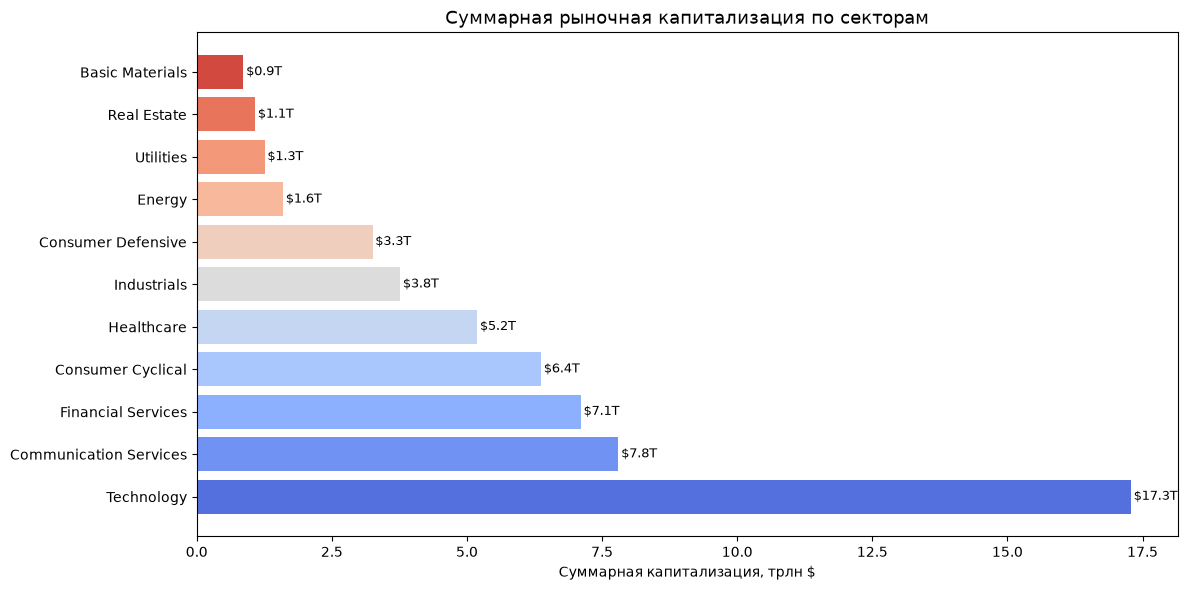

In [20]:
# График 3: Market Cap по секторам
sector_mc = companies.groupby('Sector')['Marketcap'].sum().sort_values(ascending=False) / 1e12
fig, ax = plt.subplots(figsize=(12, 6))
colors = sns.color_palette('coolwarm', len(sector_mc))
bars = ax.barh(sector_mc.index, sector_mc.values, color=colors)
ax.set_xlabel('Суммарная капитализация, трлн $')
ax.set_title('Суммарная рыночная капитализация по секторам', fontsize=13)
for bar, val in zip(bars, sector_mc.values):
    ax.text(val + 0.05, bar.get_y() + bar.get_height()/2,
            f'${val:.1f}T', va='center', fontsize=9)
plt.tight_layout()
plt.show()

Секторальная принадлежность из sp500_companies.csv используется как контрольная метка, позволяющая увидеть, какие макроэкономические тренды модель смогла "прочитать" сквозь призму голых цифр доходности

---
## 2.6 Построение итогового датасета для моделирования

### Полнота данных и состав рабочей выборки

Сопоставляем покрытие старой выгрузки и нового запроса на все 502 тикера.
Число успешно загруженных бумаг, число с признаками и число доступных на
конкретную OOS-дату — разные величины. Вывод о полной выборке допустим
только по фактическому manifest. 260-дневный признак не вычисляется до IPO.


In [21]:
legacy_raw = pd.read_csv(DATA_DIR/'sp500_stocks.csv',usecols=['Date','Symbol','Close'],parse_dates=['Date'])
legacy_coverage = legacy_raw.groupby('Symbol').Close.count().rename('legacy_quotes')
coverage_audit = download_audit[download_audit.Symbol != '^GSPC'].merge(legacy_coverage,on='Symbol',how='left')
n_symbols_file = len(requested_symbols)
price_raw = price_downloaded.copy()
coverage_funnel = [('Запрошено фиксированных тикеров',n_symbols_file,'снимок состава 2024'),
                   ('Загружены непустые истории',price_raw.Symbol.nunique(),'см. manifest')]
coverage_audit.to_csv(CACHE_DIR/'coverage_audit.csv',index=False)
display(coverage_audit)
print('Старых непустых историй:',int(legacy_coverage.gt(0).sum()))
print('Новых непустых историй:',price_raw.Symbol.nunique())
print('Данные исходного CSV не подмешиваются к новой выгрузке.')


,Symbol,YahooSymbol,status,n_quotes,first,last,sha256,error,legacy_quotes
0,A,A,ok,2517,2014-12-22,2024-12-20,0e520b703ee60465d270ca6cbc4dd152bb82976b69ffbd...,,0
1,AAPL,AAPL,ok,2517,2014-12-22,2024-12-20,51d26b1575b5b6bf13768dcefdcc7a834e6ab611e89470...,,0
2,ABBV,ABBV,ok,2517,2014-12-22,2024-12-20,3ff7e985c6f9a21b462ed626ed630cf2a1b2cc8c90e6b9...,,3014
3,ABNB,ABNB,ok,1014,2020-12-10,2024-12-20,dea1e72659ee3ae866776a5cb38f389533521dd564d0bc...,,0
4,ABT,ABT,ok,2517,2014-12-22,2024-12-20,9aacb188887fa381cc4b3cc76eb3066dd31147cf6989f7...,,3768
...,...,...,...,...,...,...,...,...,...
497,XYL,XYL,ok,2517,2014-12-22,2024-12-20,9380e88ae8fb3c090c959278e7f18ffc55f993cb2e2c67...,,3319
498,YUM,YUM,ok,2517,2014-12-22,2024-12-20,5c9ec498ab068641fcc5384505f535431a0ea6cb81d7d2...,,0
499,ZBH,ZBH,ok,2517,2014-12-22,2024-12-20,fca5d79635025134c44ab551fa38cb876b8d4a04ddd49e...,,0
500,ZBRA,ZBRA,ok,2517,2014-12-22,2024-12-20,567cf5da2ea72d3d2018ee6327a86bd17d2a9a1a9ed6dd...,,0


Старых непустых историй: 172
Новых непустых историй: 484
Данные исходного CSV не подмешиваются к новой выгрузке.


In [22]:
K_VALUES = rr.K_VALUES
FEAT_COLS = rr.BASE_FEATURES
price_all = price_raw.sort_values(['Symbol','Date']).copy()
# Полная панель цен нужна в бэктесте, включая хвост без меток.
full_price_panel = price_all[['Date','Symbol','Close']].copy()
daily_df = rr.build_base_panel(price_all,index_df,horizon=LABEL_DAYS)
print('До прогрева:',daily_df.shape)


До прогрева: (1218228, 19)


In [23]:
pd.DataFrame(price_all['Close'].describe())

,Close
count,1.183719e+06
mean,1.861723e+02
std,2.480827e+03
min,4.785000e-01
25%,4.469055e+01
50%,7.961000e+01
75%,1.412800e+02
max,1.139000e+05


Описательные характеристики цен выводятся выше заново. Различия между
средним и медианой не доказывают предсказуемость относительных доходностей.


In [24]:
daily_df = rr.add_statistical_features(daily_df)
ALL_FEAT_COLS = rr.ALL_FEATURES.copy()
ext_feature_cols = rr.EXTRA_FEATURES.copy()
assert len(ALL_FEAT_COLS) == 273
feature_ready = daily_df[ALL_FEAT_COLS].notna().all(axis=1)
prediction_panel = daily_df.loc[feature_ready].copy()  # independent of FUTURE label availability
valid_rows = feature_ready & daily_df.Target.notna()
available_counts = daily_df.loc[valid_rows].groupby('Symbol').size()
dropped_by_filter = sorted(available_counts[available_counts < 270].index)
eligibility = pd.DataFrame({'Symbol':requested_symbols}).merge(
    available_counts.rename('eligible_rows'),on='Symbol',how='left').fillna({'eligible_rows':0})
eligibility['excluded_by_old_270_filter'] = eligibility.eligible_rows.lt(270)
eligibility.to_csv(CACHE_DIR/'model_eligibility.csv',index=False)
daily_df = daily_df.loc[valid_rows].copy()
if MIN_MODEL_DAYS:
    daily_df = daily_df[daily_df.Symbol.isin(available_counts[available_counts>=MIN_MODEL_DAYS].index)]
daily_df['Target'] = daily_df.Target.astype(int)
coverage_funnel.append(('Есть 273 признака и полный таргет',daily_df.Symbol.nunique(),'IPO/пропуски/прогрев'))
funnel_df = pd.DataFrame(coverage_funnel,columns=['Шаг','Тикеров','Причина отсева'])
display(funnel_df)
funnel_df.to_csv(CACHE_DIR/'coverage_funnel.csv',index=False)
print('Рабочих строк:',len(daily_df),'бумаг:',daily_df.Symbol.nunique())
print('Класс 0:',(daily_df.Target==0).mean(),'класс 1:',daily_df.Target.mean())
# Target-зависимый EDA ограничен доступными до OOS метками.
eda_train = daily_df[(daily_df.Date<OOS_START)&(daily_df.LabelEnd<OOS_START)].copy()


,Шаг,Тикеров,Причина отсева
0,Запрошено фиксированных тикеров,502,снимок состава 2024
1,Загружены непустые истории,484,см. manifest
2,Есть 273 признака и полный таргет,481,IPO/пропуски/прогрев


Рабочих строк: 1052930 бумаг: 481
Класс 0: 0.5167114623004379 класс 1: 0.48328853769956215


In [25]:
# Итоговый датасет для моделирования - только ценовые признаки

print('Итоговые признаки:')
print(ALL_FEAT_COLS)
print(f'\nПримеры данных:')
daily_df


Итоговые признаки:
['X_1', 'X_5', 'X_10', 'X_15', 'X_20', 'X_40', 'X_60', 'X_80', 'X_100', 'X_120', 'X_150', 'X_180', 'X_260', 'X_1_mean_2', 'X_1_std_2', 'X_1_min_2', 'X_1_max_2', 'X_1_cv_2', 'X_1_mean_5', 'X_1_std_5', 'X_1_min_5', 'X_1_max_5', 'X_1_cv_5', 'X_1_mean_10', 'X_1_std_10', 'X_1_min_10', 'X_1_max_10', 'X_1_cv_10', 'X_1_mean_20', 'X_1_std_20', 'X_1_min_20', 'X_1_max_20', 'X_1_cv_20', 'X_5_mean_2', 'X_5_std_2', 'X_5_min_2', 'X_5_max_2', 'X_5_cv_2', 'X_5_mean_5', 'X_5_std_5', 'X_5_min_5', 'X_5_max_5', 'X_5_cv_5', 'X_5_mean_10', 'X_5_std_10', 'X_5_min_10', 'X_5_max_10', 'X_5_cv_10', 'X_5_mean_20', 'X_5_std_20', 'X_5_min_20', 'X_5_max_20', 'X_5_cv_20', 'X_10_mean_2', 'X_10_std_2', 'X_10_min_2', 'X_10_max_2', 'X_10_cv_2', 'X_10_mean_5', 'X_10_std_5', 'X_10_min_5', 'X_10_max_5', 'X_10_cv_5', 'X_10_mean_10', 'X_10_std_10', 'X_10_min_10', 'X_10_max_10', 'X_10_cv_10', 'X_10_mean_20', 'X_10_std_20', 'X_10_min_20', 'X_10_max_20', 'X_10_cv_20', 'X_15_mean_2', 'X_15_std_2', 'X_15_min_2', 

,Date,Close,SP500,Symbol,X_1,X_5,X_10,X_15,X_20,X_40,...,X_260_mean_10,X_260_std_10,X_260_min_10,X_260_max_10,X_260_cv_10,X_260_mean_20,X_260_std_20,X_260_min_20,X_260_max_20,X_260_cv_20
261,2016-01-06,40.730000,1990.260010,A,1.755437,0.390951,1.283415,2.759354,4.253155,11.980365,...,1.333035,2.169534,-0.201057,2.867127,1.414213,1.333035,2.169534,-0.201057,2.867127,1.414213
262,2016-01-07,39.000000,1943.089966,A,-1.877438,-1.688339,-0.683363,0.474253,0.568520,9.366504,...,1.384645,1.536694,-0.201057,2.867127,1.011860,1.384645,1.536694,-0.201057,2.867127,1.011860
263,2016-01-08,38.590000,1922.030029,A,0.032556,-1.737053,-0.721646,0.430878,0.301349,9.277168,...,1.348558,1.256780,-0.201057,2.867127,0.867290,1.348558,1.256780,-0.201057,2.867127,0.867290
264,2016-01-11,37.939999,1923.670044,A,-1.769705,-2.336906,-3.303965,-1.174466,-1.759844,8.036501,...,1.035084,1.294585,-0.218812,2.867127,1.076102,1.035084,1.294585,-0.218812,2.867127,1.076102
265,2016-01-12,38.189999,1938.680054,A,-0.121345,-1.950808,-2.863480,-1.428845,-1.314514,7.111120,...,0.716434,1.396420,-0.876817,2.867127,1.215691,0.716434,1.396420,-0.876817,2.867127,1.215691
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1218213,2024-12-02,176.809998,6047.149902,ZTS,0.645310,-1.388265,-2.053482,-0.866465,-8.381964,-12.105058,...,-31.454452,2.159314,-34.538571,-26.869262,0.068649,-31.202653,2.946740,-37.520101,-24.331530,0.094439
1218214,2024-12-03,176.940002,6049.879883,ZTS,0.028383,-2.034461,-2.356584,-0.360162,-4.897786,-11.735042,...,-32.021643,1.449278,-34.538571,-29.868290,0.045259,-31.317031,2.952355,-37.520101,-24.331530,0.094273
1218215,2024-12-04,175.320007,6086.490234,ZTS,-1.520704,-1.293395,-3.001510,-0.931115,-5.223815,-12.262327,...,-32.612573,1.757723,-36.025032,-29.868290,0.053897,-31.555157,3.134190,-37.520101,-24.331530,0.099324
1218216,2024-12-05,174.770004,6075.109863,ZTS,-0.126736,-2.387727,-3.182543,-2.781343,0.118986,-12.985236,...,-32.980532,2.026166,-36.025032,-29.868290,0.061435,-31.473081,2.987839,-36.025032,-24.331530,0.094933


In [26]:
daily_df.drop('Date', axis=1, inplace=False).describe()

C:\Users\dima\AppData\Local\Temp\ipykernel_25680\2819877123.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  daily_df.drop('Date', axis=1, inplace=False).describe()


,Close,SP500,X_1,X_5,X_10,X_15,X_20,X_40,X_60,X_80,...,X_260_mean_10,X_260_std_10,X_260_min_10,X_260_max_10,X_260_cv_10,X_260_mean_20,X_260_std_20,X_260_min_20,X_260_max_20,X_260_cv_20
count,1.052930e+06,1.052930e+06,1.052930e+06,1.052930e+06,1.052930e+06,1.052930e+06,1.052930e+06,1.052930e+06,1.052930e+06,1.052930e+06,...,1.052930e+06,1.052930e+06,1.052930e+06,1.052930e+06,1.052930e+06,1.052930e+06,1.052930e+06,1.052930e+06,1.052930e+06,1.052930e+06
mean,1.756513e+02,3.501242e+03,8.762748e-03,4.723549e-02,9.239344e-02,1.405384e-01,1.855675e-01,3.641308e-01,5.391368e-01,7.003428e-01,...,2.819173e+00,3.201078e+00,-1.868809e+00,7.679936e+00,2.816792e-01,2.833307e+00,4.449301e+00,-4.446285e+00,1.058357e+01,3.539790e-01
min,6.305000e-01,1.829080e+03,-8.240296e+01,-8.452048e+01,-8.462501e+01,-8.895973e+01,-8.820203e+01,-9.564938e+01,-1.058565e+02,-1.160463e+02,...,-1.400689e+02,2.249603e-03,-1.452271e+02,-1.350419e+02,1.722238e-04,-1.373517e+02,2.249603e-03,-1.452271e+02,-1.329438e+02,1.722238e-04
25%,4.680000e+01,2.664110e+03,-7.593544e-01,-1.827036e+00,-2.691131e+00,-3.386107e+00,-3.974977e+00,-5.817240e+00,-7.285171e+00,-8.411481e+00,...,-1.649440e+01,1.581062e+00,-2.020117e+01,-1.283646e+01,8.173683e-02,-1.632613e+01,2.273537e+00,-2.220064e+01,-1.057226e+01,1.174138e-01
50%,8.364000e+01,3.298460e+03,3.421527e-03,5.632717e-03,-4.971063e-03,-1.393410e-02,3.479415e-03,4.512299e-02,6.552598e-02,-4.530986e-02,...,-3.533527e-01,2.369952e+00,-4.209935e+00,3.499757e+00,1.522694e-01,-3.061412e-01,3.350176e+00,-6.315132e+00,5.806243e+00,2.163477e-01
75%,1.489300e+02,4.305200e+03,7.627021e-01,1.835402e+00,2.715358e+00,3.408909e+00,4.017558e+00,5.948080e+00,7.431238e+00,8.587118e+00,...,1.652996e+01,3.674142e+00,1.209515e+01,2.111426e+01,3.326844e-01,1.646692e+01,5.120698e+00,9.589091e+00,2.390170e+01,4.666406e-01
max,1.139000e+05,6.090270e+03,9.776355e+01,1.318404e+02,1.230425e+02,1.479457e+02,2.171697e+02,2.652858e+02,3.912065e+02,4.177241e+02,...,1.047308e+03,3.339033e+02,9.396308e+02,1.169177e+03,2.611426e+00,9.758008e+02,3.259294e+02,7.565618e+02,1.169177e+03,2.815920e+00
std,2.133505e+03,1.030344e+03,1.753406e+00,3.872981e+00,5.352619e+00,6.575234e+00,7.590027e+00,1.080755e+01,1.335208e+01,1.565027e+01,...,3.559856e+01,3.760179e+00,3.276948e+01,3.924667e+01,3.138061e-01,3.528319e+01,4.971930e+00,3.114738e+01,4.127843e+01,3.338180e-01


Признаки готовы к хронологическому разбиению. Прогрев X_260 использует
прошлое; он не требует 260-дневного разрыва перед тестом.


### Зависимость целевой переменной от ключевых признаков

In [27]:
from sklearn.feature_selection import mutual_info_classif
df_scoring = eda_train.sample(min(5000,len(eda_train)),random_state=SEED)
X_score,y_score = df_scoring[ALL_FEAT_COLS],df_scoring.Target
importances = mutual_info_classif(X_score,y_score,random_state=SEED)
feature_info = pd.DataFrame({'Feature':ALL_FEAT_COLS,'Importance':importances}).sort_values('Importance',ascending=False)
display(feature_info.head(5))
print('Описательный EDA на train; признаки из модели не удаляются.')


,Feature,Importance
40,X_5_min_5,0.027007
135,X_60_min_2,0.025401
230,X_150_min_20,0.024504
45,X_5_min_10,0.023573
99,X_20_std_5,0.023337


Описательный EDA на train; признаки из модели не удаляются.


C:\Users\dima\AppData\Local\Temp\ipykernel_25680\1522269013.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=tmp, x='Target_label', y=feat,
C:\Users\dima\AppData\Local\Temp\ipykernel_25680\1522269013.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=tmp, x='Target_label', y=feat,
C:\Users\dima\AppData\Local\Temp\ipykernel_25680\1522269013.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=tmp, x='Target_label', y=feat,
C:\Users\dima\AppData\Local\Temp\ipykernel_25680\1522269013.py:13: FutureWarning: 

Passing

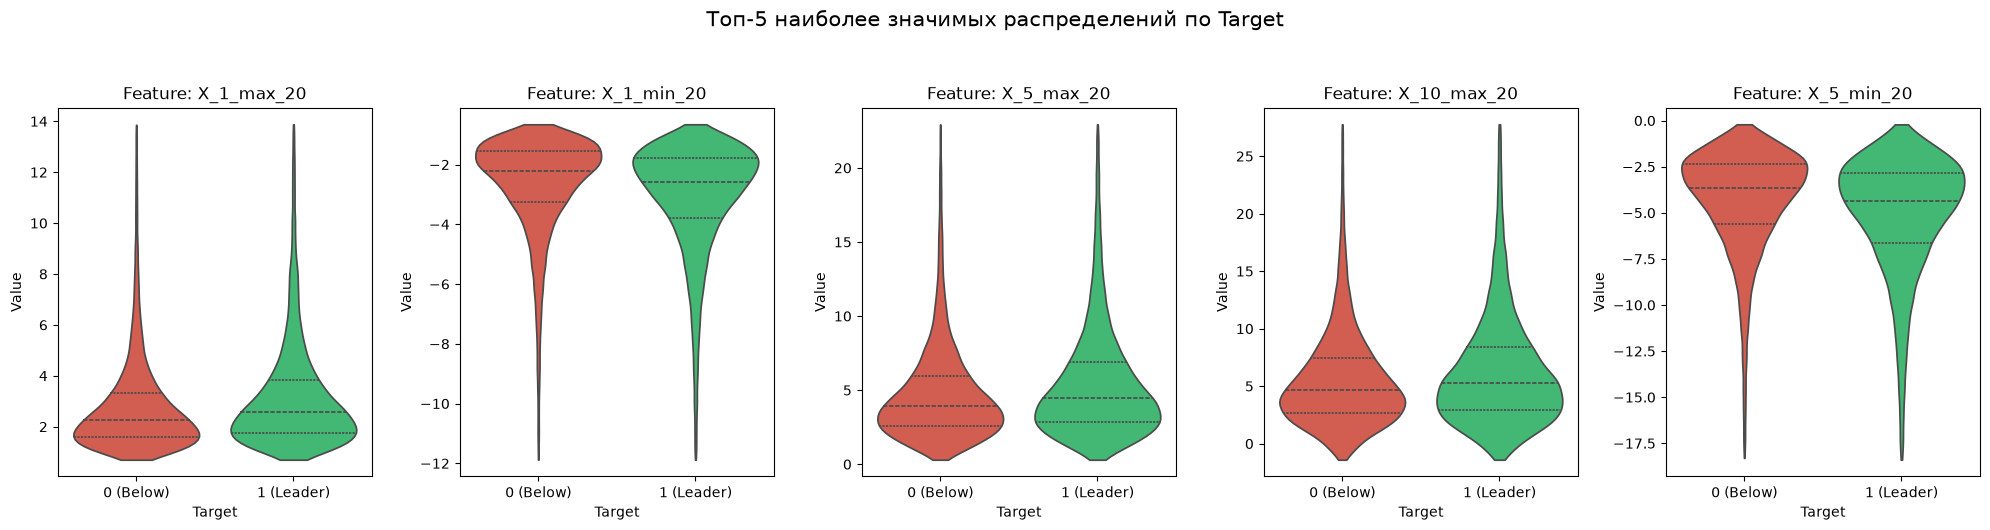

In [28]:
# Выбранные топ-5 признаков на основе анализа распределений
SHOW_FEATS = ['X_1_max_20', 'X_1_min_20', 'X_5_max_20', 'X_10_max_20', 'X_5_min_20']

sample = eda_train.dropna(subset=SHOW_FEATS + ['Target']).sample(min(50000, len(eda_train)), random_state=42)
sample['Target_label'] = sample['Target'].map({0: '0 (Below)', 1: '1 (Leader)'})

fig, axes = plt.subplots(1, len(SHOW_FEATS), figsize=(20, 5))
for ax, feat in zip(axes, SHOW_FEATS):
    # Визуализация с обрезкой 1% выбросов
    q1, q99 = sample[feat].quantile([0.01, 0.99])
    tmp = sample[(sample[feat] >= q1) & (sample[feat] <= q99)]
    
    sns.violinplot(data=tmp, x='Target_label', y=feat,
                   palette={'0 (Below)': '#e74c3c', '1 (Leader)': '#2ecc71'},
                   ax=ax, inner='quartile', cut=0)
    
    ax.set_title(f'Feature: {feat}', fontsize=12)
    ax.set_xlabel('Target')
    ax.set_ylabel('Value')

fig.suptitle('Топ-5 наиболее значимых распределений по Target', fontsize=15, y=1.05)
plt.tight_layout()
plt.show()

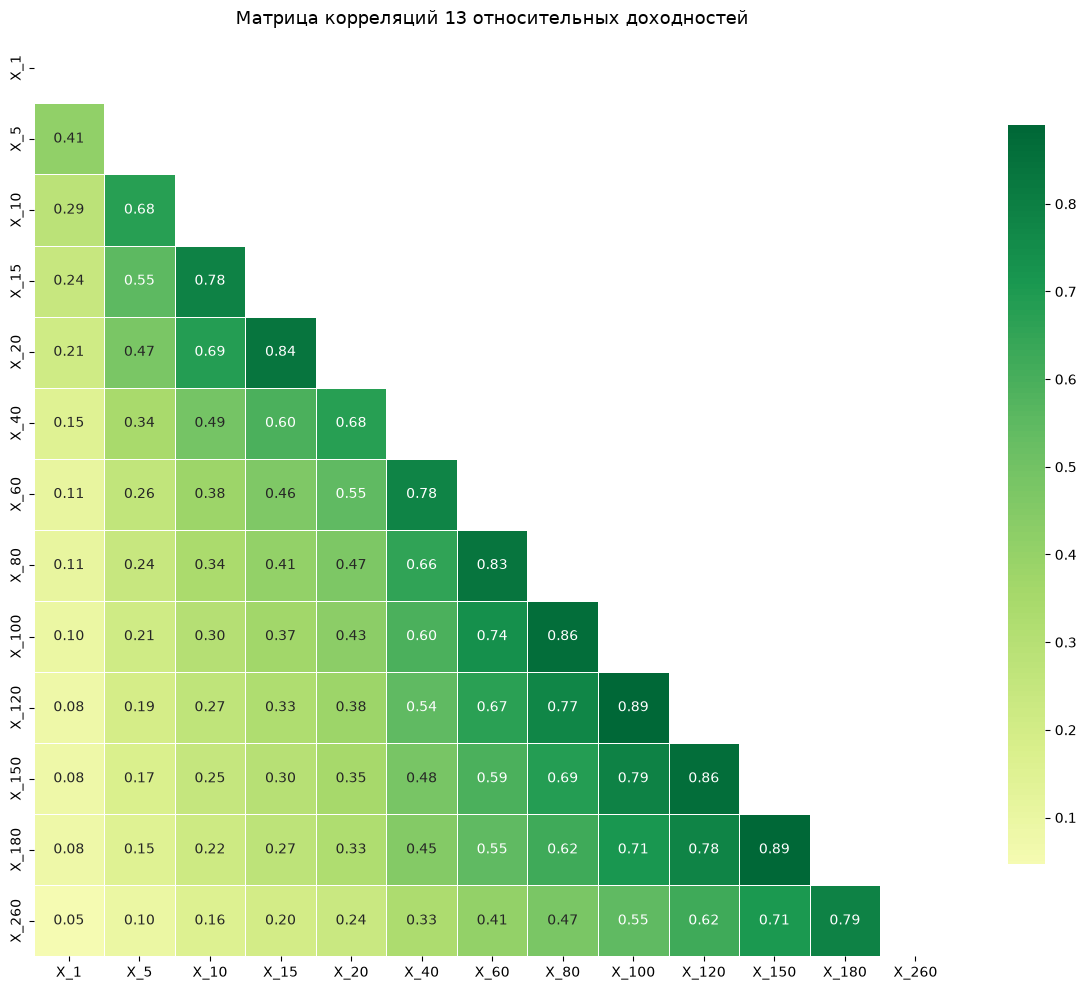

Соседние горизонты (X_1↔X_5, X_5↔X_10) сильно коррелируют.
Далёкие (X_1-X_260) - слабо


In [29]:
# EDA: матрица корреляций между 13 признаками
sample_corr = eda_train[FEAT_COLS].dropna().sample(min(30000, len(eda_train)), random_state=42)
corr = sample_corr.corr()

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='RdYlGn', center=0, annot=True, fmt='.2f',
            linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Матрица корреляций 13 относительных доходностей', fontsize=13)
plt.tight_layout()
plt.show()
print('Соседние горизонты (X_1↔X_5, X_5↔X_10) сильно коррелируют.')
print('Далёкие (X_1-X_260) - слабо')


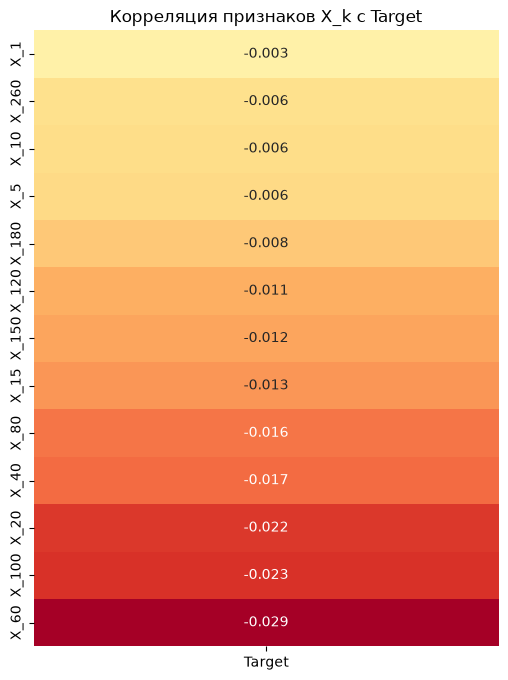

Наиболее значимые признаки для таргета:
         Target
X_1   -0.002613
X_260 -0.005610
X_10  -0.005966


In [30]:
# 1. Выбираем признаки и таргет
cols_to_corr = FEAT_COLS + ['Target']
sample_corr = eda_train[cols_to_corr].dropna().sample(min(30000, len(eda_train)), random_state=42)

# 2. Считаем матрицу
corr = sample_corr.corr()

# 3. Выделяем только корреляцию признаков с таргетом
target_corr = corr[['Target']].drop('Target').sort_values(by='Target', ascending=False)

# 4. Визуализация
plt.figure(figsize=(6, 8))
sns.heatmap(target_corr, annot=True, cmap='RdYlGn', center=0, fmt='.3f', cbar=False)
plt.title('Корреляция признаков X_k с Target')
plt.show()

print("Наиболее значимые признаки для таргета:")
print(target_corr.head(3))

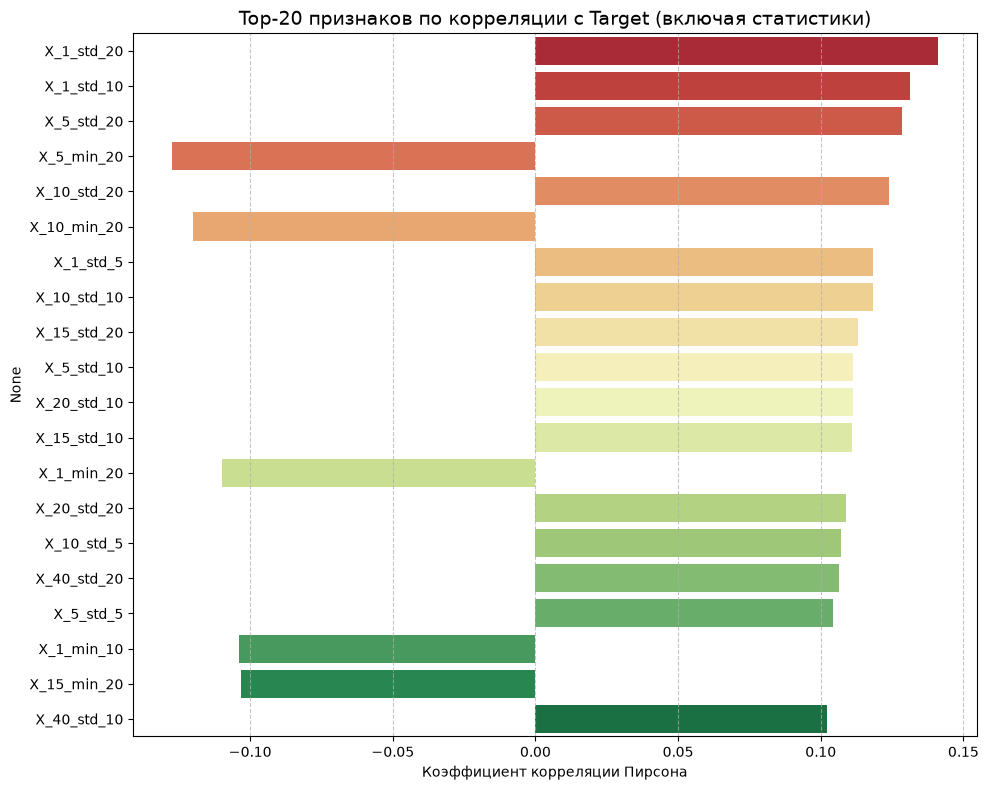

In [31]:
# 1. Список всех признаков (базовые + 270 расширенных)
all_cols = ALL_FEAT_COLS + ['Target']

# 2. Считаем корреляцию только со столбцом Target
# Берем выборку, чтобы расчет прошел быстрее
correlations = eda_train[all_cols].sample(min(50000, len(eda_train)),random_state=SEED).corr()['Target'].drop('Target')

# 3. Берем абсолютные значения, так как сильная отрицательная корреляция так же важна, как и положительная
top_features = correlations.abs().sort_values(ascending=False).head(20)
top_features_names = top_features.index

# 4. Визуализация Top-20 самых «говорящих» признаков
plt.figure(figsize=(10, 8))
sns.barplot(x=correlations[top_features_names].values, y=top_features_names,
            hue=top_features_names, palette='RdYlGn', legend=False)
plt.title('Top-20 признаков по корреляции с Target (включая статистики)', fontsize=14)
plt.xlabel('Коэффициент корреляции Пирсона')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Интерпретация зависит от текущего прогона. EDA/PCA/t-SNE не доказывают
    прибыльность и не используются для выбора модели на тестовой части.
    Все 273 признака сохраняются независимо от ранга важности.


Интерпретация зависит от текущего прогона. EDA/PCA/t-SNE не доказывают
    прибыльность и не используются для выбора модели на тестовой части.
    Все 273 признака сохраняются независимо от ранга важности.


## 2.7 Анализ признаков: однофакторный ANOVA F-критерий

Для каждого из 273 признаков сравниваются средние в двух классах **на train**.
Это `scipy.stats.f_oneway`, а не точный тест Фишера для таблиц сопряжённости.
Публикуются p и q после Benjamini–Hochberg (FDR 0.05).
Из-за временной и межбумажной зависимости результат описательный;
он не заменяет OOS-проверку и не служит отбором признаков.


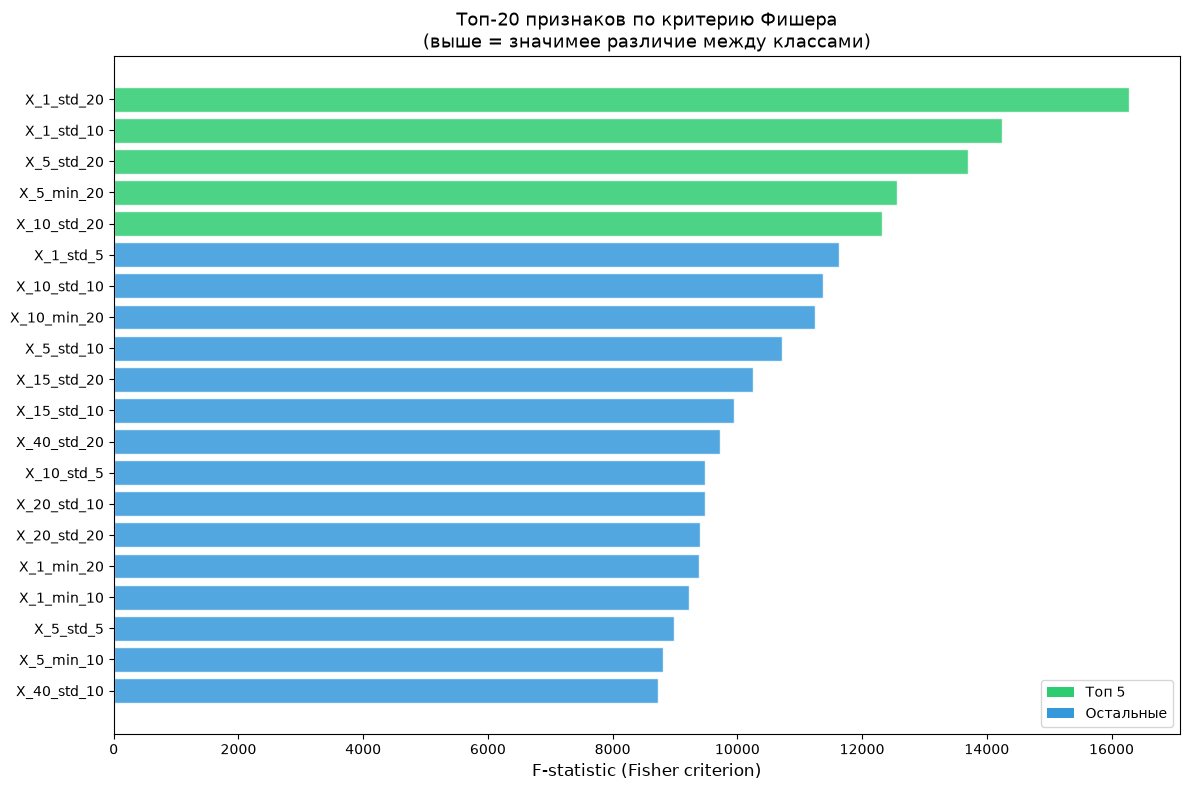

Всего признаков: 273
ANOVA F-тест (не точный тест Фишера), BH q<0.05: 259
Зависимость строк панели ограничивает интерпретацию ANOVA; q — описательный результат.

Топ-10 признаков по Fisher criterion:
                   f_stat  p_value
X_1_std_20   16283.612167      0.0
X_1_std_10   14251.433707      0.0
X_5_std_20   13706.215428      0.0
X_5_min_20   12553.910916      0.0
X_10_std_20  12313.445153      0.0
X_1_std_5    11626.388731      0.0
X_10_std_10  11378.901222      0.0
X_10_min_20  11237.883130      0.0
X_5_std_10   10711.476662      0.0
X_15_std_20  10244.291527      0.0


In [32]:
# Fisher's criterion для определения важности признаков
from scipy.stats import f_oneway

# Подготовим данные для расчёта F-статистики
fisher_scores = {}
X_for_fisher = eda_train[ALL_FEAT_COLS + ['Target']].dropna()
y_fisher = X_for_fisher['Target']

for col in ALL_FEAT_COLS:
    # Разделяем данные по классам
    class_0 = X_for_fisher[y_fisher == 0][col].values
    class_1 = X_for_fisher[y_fisher == 1][col].values
    
    # Вычисляем F-статистику (аналог ANOVA для двух групп)
    f_stat, p_value = f_oneway(class_0, class_1)
    fisher_scores[col] = {'f_stat': f_stat, 'p_value': p_value}

fisher_df = pd.DataFrame(fisher_scores).T.sort_values('f_stat', ascending=False)
fisher_df['q_BH'] = rr.bh_adjust(fisher_df.p_value.fillna(1))
fisher_df.to_csv(CACHE_DIR/'anova_bh.csv')

# Визуализация топ-20 признаков по Fisher criterion
fig, ax = plt.subplots(figsize=(12, 8))
top_fisher = fisher_df.head(20)
colors = ['#2ecc71' if idx < 5 else '#3498db' for idx in range(len(top_fisher))]
ax.barh(range(len(top_fisher)), top_fisher['f_stat'].values, color=colors, edgecolor='white', alpha=0.85)
ax.set_yticks(range(len(top_fisher)))
ax.set_yticklabels(top_fisher.index)
ax.set_xlabel('F-statistic (Fisher criterion)', fontsize=12)
ax.set_title('Топ-20 признаков по критерию Фишера\n(выше = значимее различие между классами)', fontsize=13)
ax.invert_yaxis()

# Легенда
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#2ecc71', label='Топ 5'),
                   Patch(facecolor='#3498db', label='Остальные')]
ax.legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
plt.show()

print(f'Всего признаков: {len(ALL_FEAT_COLS)}')
print(f'ANOVA F-тест (не точный тест Фишера), BH q<0.05: {(fisher_df.q_BH < .05).sum()}')
print('Зависимость строк панели ограничивает интерпретацию ANOVA; q — описательный результат.')
print(f'\nТоп-10 признаков по Fisher criterion:')
print(fisher_df.head(10)[['f_stat', 'p_value']])

Интерпретация зависит от текущего прогона. EDA/PCA/t-SNE не доказывают
    прибыльность и не используются для выбора модели на тестовой части.
    Все 273 признака сохраняются независимо от ранга важности.


---
# 3. Построение модели и валидация

## 3.1 Тип решаемой задачи

### Почему ARIMA и Prophet здесь не подходят

> **ARIMA** и **Prophet** предназначены для прогнозирования одного непрерывного ряда. В нашей задаче необходимо классифицировать **бинарный исход** на основе **273 признаков** по сотням акций. Ни ARIMA, ни Prophet не поддерживают мультивариантный вход и бинарный выход.

### Гипотезы (алгоритмы-кандидаты)

| № | Модель | Обоснование | Ключевые гиперпараметры |
|---|---|---|---|
| 1 | **Logistic Regression** | Линейный baseline; интерпретируем; устойчив на малых выборках | C (0.001–100), penalty (L1/L2) |
| 2 | **Random Forest** | Используется в Htun et al. (2024) как основная модель; устойчив к выбросам | n_estimators, max_depth, min_samples_leaf |
| 3 | **XGBoost** | Сильный ансамбль деревьев; хорошо на табличных данных | n_estimators, max_depth, learning_rate, subsample |
| 4 | **FLAML AutoML** | Автоматический перебор алгоритмов; дополняет ручной поиск | time_budget |
| 5 | **Voting Ensemble** | Комбинирование топ-моделей; как правило улучшает ROC-AUC | weights |

### Выбор метрики

| Метрика | Роль |
|---|---|
| **ROC-AUC** | Основная для сравнения в CV |
| **Precision@k** | для отбора топ-k акций, которые скорее всего выростят |
| **Average Precision** | Основная бизнес-метрика на тесте |
| **Accuracy, Precision, Recall** | Для сравнения с Htun et al. (2024) |
| **F1-score** | Вспомогательная |

---


In [33]:
df_sorted = daily_df.sort_values(['Date','Symbol']).reset_index(drop=True)
df_prediction = prediction_panel.sort_values(['Date','Symbol']).reset_index(drop=True)
calendar = pd.DatetimeIndex(index_df.Date.sort_values().unique())
first_oos_pos = calendar.searchsorted(OOS_START)
last_train_date = calendar[first_oos_pos-GAP_DAYS-1]
train_df = df_sorted[(df_sorted.Date<=last_train_date)&(df_sorted.LabelEnd<OOS_START)].copy()
test_df = df_sorted[df_sorted.Date.between(OOS_START,OOS_END)].copy()
assert train_df.LabelEnd.max() < test_df.Date.min()
FEATURE_COLS = ALL_FEAT_COLS.copy()
X_train,y_train = train_df[FEATURE_COLS],train_df.Target
X_test,y_test = test_df[FEATURE_COLS],test_df.Target
cv = rr.date_cv_splits(train_df,n_splits=5,gap=GAP_DAYS)
for tag,df in [('train',train_df),('test',test_df)]:
    print(tag,len(df),df.Date.min(),df.Date.max(),'class 0',1-df.Target.mean(),'class 1',df.Target.mean())
print('Последний LabelEnd train:',train_df.LabelEnd.max(),'первый test:',test_df.Date.min())


train 745341 2016-01-06 00:00:00 2022-05-17 00:00:00 class 0 0.5179307189595098 class 1 0.4820692810404902
test 298490 2022-06-02 00:00:00 2024-11-22 00:00:00 class 0 0.5108311836242421 class 1 0.489168816375758
Последний LabelEnd train: 2022-06-01 00:00:00 первый test: 2022-06-02 00:00:00


In [34]:
df_sorted.head()

,Date,Close,SP500,Symbol,X_1,X_5,X_10,X_15,X_20,X_40,...,X_260_mean_10,X_260_std_10,X_260_min_10,X_260_max_10,X_260_cv_10,X_260_mean_20,X_260_std_20,X_260_min_20,X_260_max_20,X_260_cv_20
0,2016-01-06,40.730000,1990.26001,A,1.755437,0.390951,1.283415,2.759354,4.253155,11.980365,...,1.333035,2.169534,-0.201057,2.867127,1.414213,1.333035,2.169534,-0.201057,2.867127,1.414213
1,2016-01-06,25.174999,1990.26001,AAPL,-0.645429,-3.154861,-4.648876,-8.906170,-10.683591,-11.628514,...,-6.094894,0.016507,-6.106566,-6.083222,0.002708,-6.094894,0.016507,-6.106566,-6.083222,0.002708
2,2016-01-06,57.380001,1990.26001,ABBV,1.328974,0.757007,3.627983,5.066092,6.152081,-5.335896,...,-8.888669,3.495120,-11.360092,-6.417246,0.393211,-8.888669,3.495120,-11.360092,-6.417246,0.393211
3,2016-01-06,42.560001,1990.26001,ABT,0.472777,-2.875870,-1.832242,-3.454392,-2.405275,-1.538436,...,-3.481482,1.391568,-4.465469,-2.497495,0.399706,-3.481482,1.391568,-4.465469,-2.497495,0.399706
4,2016-01-06,23.070000,1990.26001,ACGL,1.470730,1.389395,0.853822,0.678937,-1.025318,-1.948469,...,20.259511,0.018022,20.246768,20.272254,0.000890,20.259511,0.018022,20.246768,20.272254,0.000890


---
## 3.1.1 Анализ многомерности данных: PCA и t-SNE

**Цель:** Визуализировать структуру данных в 2D пространстве, выявить естественные кластеры и разделимость классов.

### PCA (Principal Component Analysis)
- **Линейный** метод уменьшения размерности
- Сохраняет глобальную структуру данных
- Быстрый и интерпретируемый
- Подходит для понимания глобальных паттернов

### t-SNE (t-Distributed Stochastic Neighbor Embedding)
- **Нелинейный** метод уменьшения размерности
- Хорошо сохраняет локальную структуру данных
- Выявляет кластеры и выбросы
- Медленнее, но часто дает более информативную визуализацию

**Интерпретация:** Если классы 0 и 1 четко разделены в 2D пространстве PCA/t-SNE - это признак того, что задача легко решаема. Перекрытие облаков - признак высокой сложности.

Применяем PCA для визуализации...
Для отрисовки взята стратифицированная подвыборка: 5,000 из 745,341 точек (доля класса 1: 0.482 против 0.482 на полной)


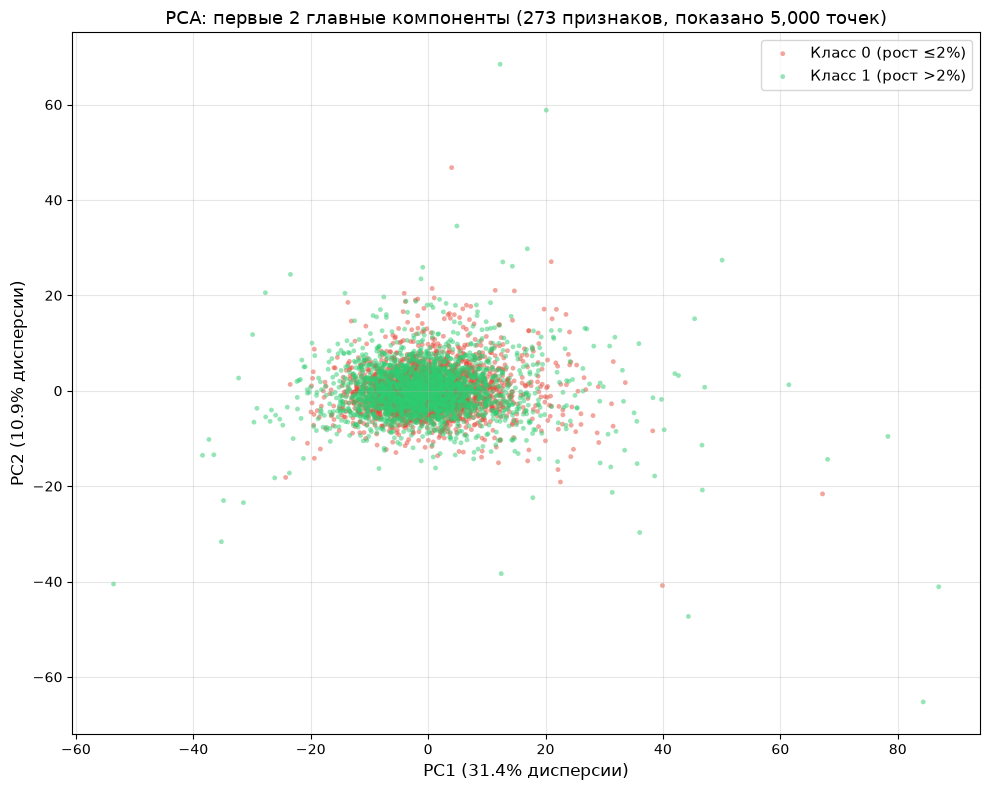

Доля объяснённой дисперсии PC1: 31.42%
Доля объяснённой дисперсии PC2: 10.87%
Суммарно: 42.29%


In [35]:
# PCA визуализация
from sklearn.decomposition import PCA

print('Применяем PCA для визуализации...')
X_train_clean = X_train.dropna()
y_train_clean = y_train.loc[X_train_clean.index]

# Масштабирование и PCA считаются на ПОЛНОЙ обучающей выборке, чтобы доли
# объяснённой дисперсии относились ко всем данным, а не к подвыборке.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train_clean)

pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)

# ── Подвыборка для отрисовки ─────────────────────────────────────────────────
# 225 тыс. точек с alpha=0.6 и s=30 сливаются в сплошное пятно, из которого
# ничего не видно, а t-SNE ниже на таком объёме считается больше получаса.
# Стратифицированная подвыборка фиксированного размера: доли классов
# сохраняются, картинка читается, сид зафиксирован.
rng_viz = np.random.default_rng(SEED)
y_arr = y_train_clean.to_numpy()

if len(y_arr) > VIZ_SAMPLE:
    per_class = {c: np.flatnonzero(y_arr == c) for c in np.unique(y_arr)}
    viz_idx = np.sort(np.concatenate([
        rng_viz.choice(pos, size=round(VIZ_SAMPLE * len(pos) / len(y_arr)),
                       replace=False)
        for pos in per_class.values()
    ]))
else:
    viz_idx = np.arange(len(y_arr))

y_viz = y_arr[viz_idx]
print(f'Для отрисовки взята стратифицированная подвыборка: '
      f'{len(viz_idx):,} из {len(y_arr):,} точек '
      f'(доля класса 1: {y_viz.mean():.3f} против {y_arr.mean():.3f} на полной)')

# ── Визуализация ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 8))
xy = X_pca[viz_idx]
ax.scatter(xy[y_viz == 0, 0], xy[y_viz == 0, 1], c='#e74c3c',
           label='Класс 0 (рост ≤2%)', alpha=0.5, s=12, edgecolors='none')
ax.scatter(xy[y_viz == 1, 0], xy[y_viz == 1, 1], c='#2ecc71',
           label='Класс 1 (рост >2%)', alpha=0.5, s=12, edgecolors='none')

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} дисперсии)', fontsize=12)
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} дисперсии)', fontsize=12)
ax.set_title(f'PCA: первые 2 главные компоненты ({len(FEATURE_COLS)} признаков, '
             f'показано {len(viz_idx):,} точек)', fontsize=13)
ax.legend(loc='best', fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'pca_feature_space.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Доля объяснённой дисперсии PC1: {pca.explained_variance_ratio_[0]:.2%}')
print(f'Доля объяснённой дисперсии PC2: {pca.explained_variance_ratio_[1]:.2%}')
print(f'Суммарно: {sum(pca.explained_variance_ratio_):.2%}')

Интерпретация зависит от текущего прогона. EDA/PCA/t-SNE не доказывают
    прибыльность и не используются для выбора модели на тестовой части.
    Все 273 признака сохраняются независимо от ранга важности.


Применяем t-SNE: 5,000 точек x 50 компонент (PCA удержала 93.0% дисперсии)...


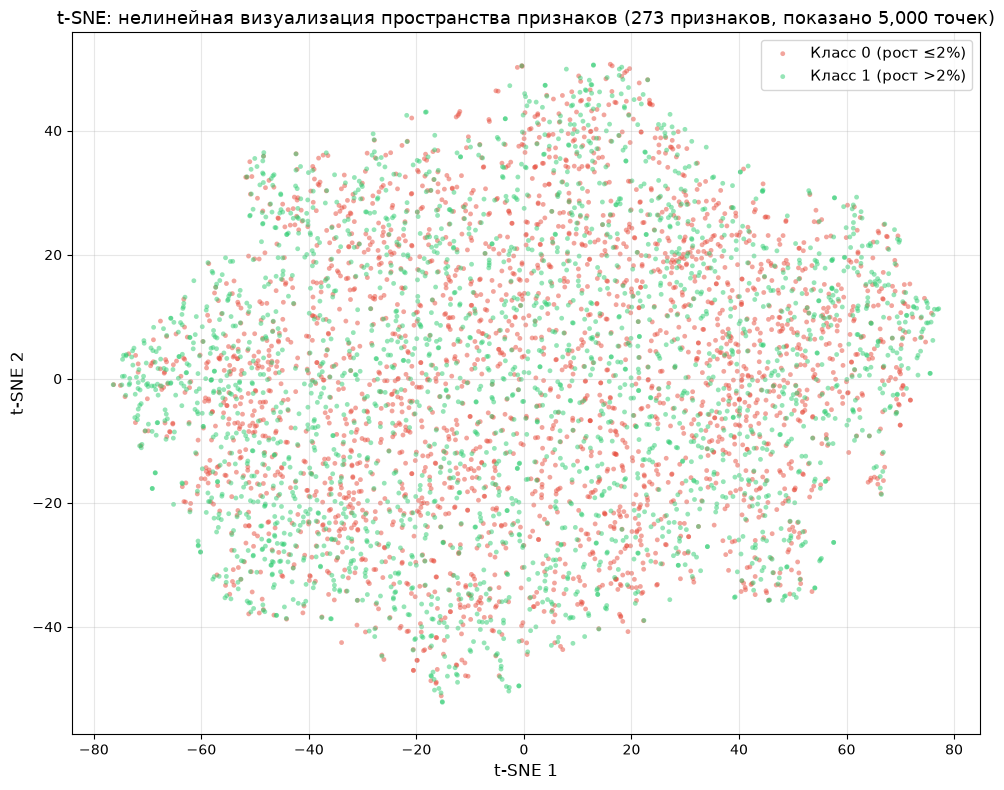

KL-дивергенция после 999 итераций: 2.131
Расстояния между кластерами на карте t-SNE не интерпретируются, а сама карта
зависит от perplexity - это иллюстрация зашумлённости данных, не доказательство.


In [36]:
# t-SNE визуализация
from sklearn.manifold import TSNE

n_pca = min(50, X_scaled.shape[1])
pca_prep = PCA(n_components=n_pca, random_state=SEED)
X_pca_prep = pca_prep.fit_transform(X_scaled)      # PCA на полной выборке
X_tsne_input = X_pca_prep[viz_idx]                 # t-SNE - на подвыборке

print(f'Применяем t-SNE: {X_tsne_input.shape[0]:,} точек x {n_pca} компонент '
      f'(PCA удержала {pca_prep.explained_variance_ratio_.sum():.1%} дисперсии)...')

tsne = TSNE(n_components=2, random_state=SEED, perplexity=30, max_iter=1000,
            init='pca', learning_rate='auto', verbose=0)
X_tsne = tsne.fit_transform(X_tsne_input)

# ── Визуализация ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(X_tsne[y_viz == 0, 0], X_tsne[y_viz == 0, 1], c='#e74c3c',
           label='Класс 0 (рост ≤2%)', alpha=0.5, s=12, edgecolors='none')
ax.scatter(X_tsne[y_viz == 1, 0], X_tsne[y_viz == 1, 1], c='#2ecc71',
           label='Класс 1 (рост >2%)', alpha=0.5, s=12, edgecolors='none')

ax.set_xlabel('t-SNE 1', fontsize=12)
ax.set_ylabel('t-SNE 2', fontsize=12)
ax.set_title(f't-SNE: нелинейная визуализация пространства признаков '
             f'({len(FEATURE_COLS)} признаков, показано {len(viz_idx):,} точек)',
             fontsize=13)
ax.legend(loc='best', fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'tsne_feature_space.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'KL-дивергенция после {tsne.n_iter_} итераций: {tsne.kl_divergence_:.3f}')
print('Расстояния между кластерами на карте t-SNE не интерпретируются, '
      'а сама карта\nзависит от perplexity - это иллюстрация зашумлённости '
      'данных, не доказательство.')

Интерпретация зависит от текущего прогона. EDA/PCA/t-SNE не доказывают
    прибыльность и не используются для выбора модели на тестовой части.
    Все 273 признака сохраняются независимо от ранга важности.


## 3.2 Методология обучения и протокол сравнения

Общий OOS: **2022-06-02…2024-11-22**, метка 10 дней, purge 10 дней.
Тестирование — одни и те же строки Date/Symbol и конфигурация модели.

| Вариант | История train | Обновление |
|---|---|---|
| Static | вся доступная до первого OOS | один раз |
| Expanding retrained | вся доступная до каждого фолда | каждые 21 день |
| Sliding retrained | последние 253 даты | каждые 21 день |

Expanding retrained vs Sliding retrained изолирует **форму окна** при общем
расписании и purge. Разный объём истории — свойство определения окна.
Static vs Expanding retrained оценивает обновление модели и доступной истории;
это не оценка «чистой частоты» при неизменном train.
Старый static с gap=260 не называется expanding walk-forward.


## 3.3 Реализация перебора гипотез — кросс-валидация

Пять expanding-фолдов строятся по уникальным датам внутри train. Все акции
одного дня лежат в одной части; перед validation удаляются 10 дат и все
строки с LabelEnd >= validation_start. Масштабирование обучается внутри Pipeline.
ROC-AUC — ранжирование; AP и дневной Precision@10 — качество отбора.
Достижение относительного уровня не равно положительному P&L сделки.


In [37]:
cv = rr.date_cv_splits(train_df,n_splits=5,gap=GAP_DAYS)


def make_models(seed=SEED):
    """Единый набор моделей для обеих схем валидации.

    Раньше expanding-схема работала на подобранных гиперпараметрах, а
    скользящее окно - на дефолтных. Сравнивались фактически разные модели,
    и разницу в доходности нельзя было отнести к схеме валидации.
    Теперь конфигурация одна и создаётся в одном месте.
    """
    gb = (HistGradientBoostingClassifier(max_iter=100, max_depth=4,
                                         random_state=seed, early_stopping=False)
          if USE_HIST_GB else
          GradientBoostingClassifier(n_estimators=100, max_depth=4,
                                     random_state=seed))
    return [
        ('Logistic Regression',
         Pipeline([('scaler', StandardScaler()),
                   ('clf', LogisticRegression(random_state=seed, max_iter=1000))])),
        ('Random Forest',
         RandomForestClassifier(criterion='entropy', max_depth=8,
                                n_estimators=100, random_state=seed, n_jobs=-1)),
        ('XGBoost',
         XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1,
                       subsample=0.8, eval_metric='logloss',
                       device=XGB_DEVICE, random_state=seed, verbosity=0)),
        ('Gradient Boosting', gb),
        ('KNN',
         Pipeline([('scaler', StandardScaler()),
                   ('clf', KNeighborsClassifier(n_neighbors=11,
                                                weights='distance', n_jobs=-1))])),
    ]


models = make_models()

if USE_HIST_GB:
    print('Внимание: GradientBoostingClassifier заменён на гистограммный '
          'HistGradientBoostingClassifier.')
    print('Тот же алгоритм с биннингом признаков: ~9 с против ~11 мин на одну '
          'подгонку при 273 признаках,')
    print('что и делает прогон на десятках фолдов выполнимым. '
          'Замена отражена в тексте работы.\n')

results = []
print('Кросс-валидация (TimeSeriesSplit, 5 фолдов, метрика: ROC-AUC)...')
for name, model in models:
    scores = cross_val_score(model, X_train, y_train, scoring='roc_auc',
                             cv=cv, n_jobs=1)
    results.append({'Модель': name,
                    'CV ROC-AUC (mean)': scores.mean(),
                    'CV ROC-AUC (std)': scores.std(),
                    'folds': list(scores)})
    print(f'  {name:<25} {scores.mean():.4f} ± {scores.std():.4f}')

print('\n  AutoML (FLAML, 5-fold TimeSeriesSplit) ...')
flaml_fold_scores = []
splits = cv

for fold_i, (tr_idx, val_idx) in enumerate(splits):
    X_tr_fl, y_tr_fl = X_train.iloc[tr_idx], y_train.iloc[tr_idx]
    X_val_fl, y_val_fl = X_train.iloc[val_idx], y_train.iloc[val_idx]

    inner_frame = train_df.iloc[tr_idx]
    inner_tr,inner_val = rr.date_cv_splits(inner_frame,n_splits=2,gap=GAP_DAYS)[-1]
    automl = FlamlAutoML()
    automl.fit(X_tr_fl.iloc[inner_tr], y_tr_fl.iloc[inner_tr],
               X_val=X_tr_fl.iloc[inner_val], y_val=y_tr_fl.iloc[inner_val], task='classification', metric='roc_auc',
               time_budget=30, seed=SEED, verbose=0,
               eval_method='holdout',split_type='time',
               estimator_list=['lrl2','rf','xgboost','histgb'])
    # Refit the selected estimator on the full OUTER train, then score outer validation.
    from sklearn.base import clone
    automl_selected = clone(automl.model.estimator).fit(X_tr_fl,y_tr_fl)
    fold_auc = roc_auc_score(y_val_fl, automl_selected.predict_proba(X_val_fl)[:, 1])
    flaml_fold_scores.append(fold_auc)
    print(f'    Fold {fold_i + 1}/5: ROC-AUC={fold_auc:.4f}  '
          f'best_estimator={automl.best_estimator}')

results.append({'Модель': 'FLAML AutoML',
                'CV ROC-AUC (mean)': float(np.mean(flaml_fold_scores)),
                'CV ROC-AUC (std)': float(np.std(flaml_fold_scores)),
                'folds': flaml_fold_scores})
print(f'  FLAML AutoML              {np.mean(flaml_fold_scores):.4f} ± '
      f'{np.std(flaml_fold_scores):.4f}')
flaml_best = automl

# Имя cv_results_df вместо results_df: ячейка скользящего окна ниже тоже
# собирает таблицу результатов, и раньше они перезаписывали друг друга -
# «лучшая модель» зависела от того, какая ячейка выполнилась последней.
cv_results_df = (pd.DataFrame(results)
                 .sort_values('CV ROC-AUC (mean)', ascending=False)
                 .reset_index(drop=True))

# Пофолдовые значения понадобятся для проверки значимости
cv_fold_scores = {r['Модель']: r['folds'] for r in results}

print('\nРазброс между соседними моделями сопоставим со стандартным '
      'отклонением по фолдам.')
print('Формальная проверка значимости этих различий - в разделе 3.6.')

cv_results_df.drop(columns='folds')

Внимание: GradientBoostingClassifier заменён на гистограммный HistGradientBoostingClassifier.
Тот же алгоритм с биннингом признаков: ~9 с против ~11 мин на одну подгонку при 273 признаках,
что и делает прогон на десятках фолдов выполнимым. Замена отражена в тексте работы.

Кросс-валидация (TimeSeriesSplit, 5 фолдов, метрика: ROC-AUC)...
  Logistic Regression       0.5786 ± 0.0123
  Random Forest             0.5854 ± 0.0098
  XGBoost                   0.5824 ± 0.0092
  Gradient Boosting         0.5838 ± 0.0105
  KNN                       0.5337 ± 0.0060

  AutoML (FLAML, 5-fold TimeSeriesSplit) ...
    Fold 1/5: ROC-AUC=0.5583  best_estimator=rf
    Fold 2/5: ROC-AUC=0.5884  best_estimator=rf
    Fold 3/5: ROC-AUC=0.5978  best_estimator=histgb
    Fold 4/5: ROC-AUC=0.5698  best_estimator=rf
    Fold 5/5: ROC-AUC=0.5740  best_estimator=rf
  FLAML AutoML              0.5777 ± 0.0139

Разброс между соседними моделями сопоставим со стандартным отклонением по фолдам.
Формальная проверка знач

,Модель,CV ROC-AUC (mean),CV ROC-AUC (std)
0,Random Forest,0.585377,0.009782
1,Gradient Boosting,0.583806,0.010530
2,XGBoost,0.582444,0.009166
3,Logistic Regression,0.578623,0.012347
4,FLAML AutoML,0.577660,0.013915
5,KNN,0.533664,0.006003


Визуализация сравнения моделей

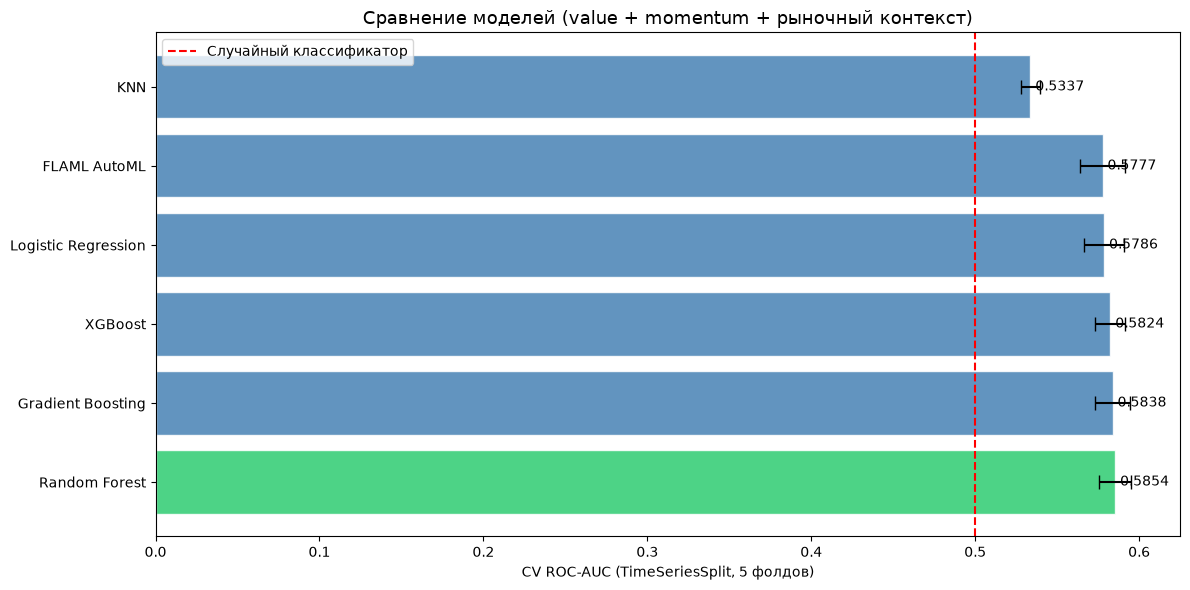

In [38]:
# Визуализация сравнения моделей
fig, ax = plt.subplots(figsize=(12, 6))
colors = ['#2ecc71' if i == 0 else 'steelblue' for i in range(len(cv_results_df))]
bars = ax.barh(cv_results_df['Модель'], cv_results_df['CV ROC-AUC (mean)'],
               xerr=cv_results_df['CV ROC-AUC (std)'], color=colors,
               capsize=5, edgecolor='white', alpha=0.85)
ax.set_xlabel('CV ROC-AUC (TimeSeriesSplit, 5 фолдов)')
ax.set_title('Сравнение моделей (value + momentum + рыночный контекст)', fontsize=13)
ax.axvline(0.5, color='red', linestyle='--', linewidth=1.5, label='Случайный классификатор')
ax.legend()
for bar, val in zip(bars, cv_results_df['CV ROC-AUC (mean)']):
    ax.text(val + 0.003, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=10)
plt.tight_layout()
plt.show()

## 3.4 Подбор гиперпараметров лучшей модели (RandomizedSearchCV)

In [39]:
# ── Подбор гиперпараметров: RandomizedSearchCV по трём моделям ──────────────
#
# Полный поиск - 3 модели x 10 кандидатов x 5 фолдов на 225 тыс. наблюдений и
# 273 признаках - занимает часы. Найденные им параметры зафиксированы ниже,
# и по умолчанию модели просто строятся с этими параметрами.
# Чтобы перезапустить поиск, поставьте RUN_HYPERPARAM_SEARCH = True
# в ячейке протокола эксперимента.

best_name = cv_results_df.iloc[0]['Модель']
print(f'Лучшая модель по CV: {best_name}')

# Результат RandomizedSearchCV (random_state=42, n_iter=10, cv=TimeSeriesSplit(5))
BEST_PARAMS = {
    'LogReg': {'clf__C': 0.07887658410143283,
               'clf__penalty': 'l2',
               'clf__solver': 'liblinear'},
    'RandomForest': {'criterion': 'entropy', 'max_depth': 8,
                     'min_samples_leaf': 1, 'n_estimators': 413},
    'XGBoost': {'colsample_bytree': 0.6399899663272012,
                'gamma': 0.22962444598293358,
                'learning_rate': 0.07674172222780437,
                'max_depth': 5, 'min_child_weight': 6,
                'n_estimators': 408, 'subsample': 0.9879639408647978},
}
BEST_CV_SCORES = {'LogReg': np.nan, 'RandomForest': np.nan, 'XGBoost': np.nan}
print('Сохранённые параметры — legacy-конфигурации, НЕ новый результат поиска.')

if RUN_HYPERPARAM_SEARCH:
    lr_param_dist = {'clf__C': uniform(0.001, 100),
                     'clf__penalty': ['l1', 'l2'],
                     'clf__solver': ['liblinear']}
    lr_search = RandomizedSearchCV(
        Pipeline([('scaler', StandardScaler()),
                  ('clf', LogisticRegression(random_state=SEED, max_iter=1000))]),
        param_distributions=lr_param_dist, n_iter=10, scoring='roc_auc',
        cv=cv, random_state=SEED, n_jobs=1, verbose=1)
    lr_search.fit(X_train, y_train)

    rf_param_dist = {'n_estimators': randint(100, 500),
                     'max_depth': randint(4, 16),
                     'min_samples_leaf': randint(1, 20),
                     'criterion': ['gini', 'entropy']}
    rf_search = RandomizedSearchCV(
        RandomForestClassifier(random_state=SEED),
        param_distributions=rf_param_dist, n_iter=10, scoring='roc_auc',
        cv=cv, random_state=SEED, n_jobs=1, verbose=1)
    rf_search.fit(X_train, y_train)

    xgb_param_dist = {'n_estimators': randint(100, 500),
                      'max_depth': randint(3, 10),
                      'learning_rate': uniform(0.01, 0.2),
                      'subsample': uniform(0.6, 0.4),
                      'colsample_bytree': uniform(0.6, 0.4),
                      'min_child_weight': randint(1, 10),
                      'gamma': uniform(0, 0.5)}
    xgb_search = RandomizedSearchCV(
        XGBClassifier(eval_metric='logloss', device=XGB_DEVICE,
                      random_state=SEED, n_jobs=1),
        param_distributions=xgb_param_dist, n_iter=10, scoring='roc_auc',
        cv=cv, random_state=SEED, n_jobs=1, verbose=1)
    xgb_search.fit(X_train, y_train)

    BEST_PARAMS = {'LogReg': lr_search.best_params_,
                   'RandomForest': rf_search.best_params_,
                   'XGBoost': xgb_search.best_params_}
    BEST_CV_SCORES = {'LogReg': lr_search.best_score_,
                      'RandomForest': rf_search.best_score_,
                      'XGBoost': xgb_search.best_score_}
    print('\nПоиск перезапущен, параметры выше заменены найденными.')

# ── Сборка настроенных моделей ───────────────────────────────────────────────
tuned_estimators = {
    'LogReg (tuned)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(random_state=SEED, max_iter=1000)),
    ]).set_params(**BEST_PARAMS['LogReg']),
    'Random Forest (tuned)': RandomForestClassifier(
        random_state=SEED, n_jobs=-1, **BEST_PARAMS['RandomForest']),
    'XGBoost (tuned)': XGBClassifier(
        eval_metric='logloss', device=XGB_DEVICE, random_state=SEED,
        verbosity=0, **BEST_PARAMS['XGBoost']),
}

print('\nКонфигурации (новый поиск только при RUN_HYPERPARAM_SEARCH=True):')
for key, params in BEST_PARAMS.items():
    print(f'  {key:<13} CV ROC-AUC = {BEST_CV_SCORES[key]:.4f}')
    print(f'                {params}')

tuned_estimators['Random Forest (base)'] = dict(make_models())[BASE_MODEL]
print('\nОбучаем модели на train...')
for name, est in tuned_estimators.items():
    est.fit(X_train, y_train)
    print(f'  {name} - готово')

MODEL_DIR.mkdir(parents=True, exist_ok=True)
for name, est in tuned_estimators.items():
    fname = name.replace(' ', '_').replace('(', '').replace(')', '').lower()
    joblib.dump(est, MODEL_DIR / f'{fname}.pkl')
print(f'\nМодели сохранены в {MODEL_DIR}')

Лучшая модель по CV: Random Forest
Сохранённые параметры — legacy-конфигурации, НЕ новый результат поиска.

Конфигурации (новый поиск только при RUN_HYPERPARAM_SEARCH=True):
  LogReg        CV ROC-AUC = nan
                {'clf__C': 0.07887658410143283, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'}
  RandomForest  CV ROC-AUC = nan
                {'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 413}
  XGBoost       CV ROC-AUC = nan
                {'colsample_bytree': 0.6399899663272012, 'gamma': 0.22962444598293358, 'learning_rate': 0.07674172222780437, 'max_depth': 5, 'min_child_weight': 6, 'n_estimators': 408, 'subsample': 0.9879639408647978}

Обучаем модели на train...


c:\Users\dima\anaconda3\envs\bz\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


  LogReg (tuned) - готово
  Random Forest (tuned) - готово
  XGBoost (tuned) - готово
  Random Forest (base) - готово

Модели сохранены в c:\Users\dima\Desktop\Важные файлы с МГТУ им. Н.Э.Баумана и не только\ИУ6\3 курс\6 семестр\КУРСАЧИ\МЛ\MMOAI\models\versions\review_2026_11_01


In [41]:
# Финальная оценка на тестовой выборке с расширенным набором метрик
final_results = {}
print(f"{'Модель':<30} {'ROC-AUC':>9} {'Avg Prec':>9} {'F1':>7} "
      f"{'Precision':>10} {'Recall':>8}")
print('-' * 78)

for name, model in tuned_estimators.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test)
    r = {
        'model': model, 'y_prob': y_prob, 'y_pred': y_pred,
        'roc_auc': roc_auc_score(y_test, y_prob),
        'avg_prec': average_precision_score(y_test, y_prob),
        'f1': f1_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred, zero_division=0),
        'recall': recall_score(y_test, y_pred, zero_division=0),
    }
    final_results[name] = r
    print(f'{name:<30} {r["roc_auc"]:>9.4f} {r["avg_prec"]:>9.4f} '
          f'{r["f1"]:>7.4f} {r["precision"]:>10.4f} {r["recall"]:>8.4f}')

# Primary RF fixed a priori; never select on holdout AP.
best_final_name = 'Random Forest (base)'
best = final_results[best_final_name]
print(f'\nОсновная конфигурация, выбранная заранее: {best_final_name}')

# ── Предсказания expanding-схемы в едином формате ────────────────────────────
# Пригодятся и для бэктеста, и для проверки значимости, и для повторного
# запуска ноутбука без переобучения.
expanding_preds = test_df[['Date', 'Symbol']].copy()
expanding_preds['y_true'] = y_test.values
for name, r in final_results.items():
    expanding_preds[name] = r['y_prob']
expanding_preds['y_prob'] = best['y_prob']

if SAVE_PREDICTIONS:
    expanding_preds.to_parquet(PRED_DIR / 'expanding_preds.parquet', index=False)
    print(f'Предсказания expanding сохранены: '
          f'{PRED_DIR / "expanding_preds.parquet"}')

# ── Precision@K ──────────────────────────────────────────────────────────────
# Считаем только подневно. Прежний вариант брал топ-50 строк по всему пулу
# теста сразу: эти 50 наблюдений приходят с двух-трёх дат, торговой
# интерпретации у такого числа нет.
K = TOP_K
baseline_rate = y_test.mean()

daily_precision_at_k = (expanding_preds
                        .groupby('Date', group_keys=False)
                        .apply(lambda x: x.nlargest(min(K, len(x)), 'y_prob')['y_true'].mean())
                        .mean())

daily_recalls = []
for date, day in expanding_preds.groupby('Date'):
    if day['y_true'].sum() == 0:
        continue
    top = day.nlargest(min(K, len(day)), 'y_prob')
    daily_recalls.append(top['y_true'].sum() / day['y_true'].sum())

print(f'\nСредний дневной Precision@{K}: {daily_precision_at_k:.3f}')
print(f'Средний дневной Recall@{K}:    {np.mean(daily_recalls):.3f}')
print(f'Базовая доля класса 1 в тесте: {baseline_rate:.3f}')
print(f'Lift: {daily_precision_at_k / baseline_rate:.2f}x')

# ── Сводная таблица: CV vs Тест ──────────────────────────────────────────────
# Раньше здесь был KeyError: в cv_results_df колонка называется
# 'CV ROC-AUC (mean)', а код искал 'ROC-AUC', поэтому таблица не выводилась.
print('\n' + '=' * 70)
print('СВОДНОЕ СРАВНЕНИЕ: CV ROC-AUC vs Тест ROC-AUC')
print('=' * 70)

cv_lookup = cv_results_df.set_index('Модель')['CV ROC-AUC (mean)'].to_dict()
tuned_to_base = {'LogReg (tuned)': 'Logistic Regression',
                 'Random Forest (tuned)': 'Random Forest',
                 'XGBoost (tuned)': 'XGBoost', 'Random Forest (base)': BASE_MODEL}

print(f"{'Модель':<30} {'CV ROC-AUC':>12} {'Тест ROC-AUC':>14} {'Gap':>8}")
print('-' * 68)
for name, res in final_results.items():
    cv_val = cv_lookup.get(tuned_to_base.get(name, name), float('nan'))
    gap = res['roc_auc'] - cv_val
    flag = '  ! drift' if abs(gap) > 0.03 else ''
    print(f'{name:<30} {cv_val:>12.4f} {res["roc_auc"]:>14.4f} {gap:>+8.4f}{flag}')

print('\nGap > 0.03 (!) указывает на distribution shift между обучением и тестом.')

Модель                           ROC-AUC  Avg Prec      F1  Precision   Recall
------------------------------------------------------------------------------
LogReg (tuned)                    0.5748    0.5600  0.4915     0.5576   0.4394
Random Forest (tuned)             0.5776    0.5610  0.5344     0.5487   0.5208
XGBoost (tuned)                   0.5748    0.5570  0.5448     0.5417   0.5479
Random Forest (base)              0.5774    0.5609  0.5340     0.5478   0.5208

Основная конфигурация, выбранная заранее: Random Forest (base)
Предсказания expanding сохранены: c:\Users\dima\Desktop\Важные файлы с МГТУ им. Н.Э.Баумана и не только\ИУ6\3 курс\6 семестр\КУРСАЧИ\МЛ\MMOAI\data\derived\review_2026_11_01\predictions\expanding_preds.parquet

Средний дневной Precision@10: 0.662
Средний дневной Recall@10:    0.030
Базовая доля класса 1 в тесте: 0.489
Lift: 1.35x

СВОДНОЕ СРАВНЕНИЕ: CV ROC-AUC vs Тест ROC-AUC
Модель                           CV ROC-AUC   Тест ROC-AUC      Gap
----------------

Recall и Precision отвечают на разные вопросы; при ограничении k
оцениваем Precision@10 по дням и P&L с учётом риска и издержек.
Модель для основного экономического опыта фиксирована до просмотра теста.


In [42]:
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve
tr_pos,val_pos = cv[-1]
threshold_est = clone(best['model']).fit(X_train.iloc[tr_pos],y_train.iloc[tr_pos])
val_prob = threshold_est.predict_proba(X_train.iloc[val_pos])[:,1]
prec_arr,rec_arr,thresholds = precision_recall_curve(y_train.iloc[val_pos],val_prob)
f1_arr = 2*prec_arr[:-1]*rec_arr[:-1]/np.maximum(prec_arr[:-1]+rec_arr[:-1],1e-12)
best_thr = thresholds[np.argmax(f1_arr)]
y_pred_opt = (best['y_prob'] >= best_thr).astype(int)
print('Порог выбран на последнем purged train-фолде:',best_thr)
print(classification_report(y_test,y_pred_opt,zero_division=0))
print('Top-K стратегия от порога не зависит.')


Порог выбран на последнем purged train-фолде: 0.34844254254671353
              precision    recall  f1-score   support

           0       0.64      0.01      0.02    152478
           1       0.49      0.99      0.66    146012

    accuracy                           0.49    298490
   macro avg       0.57      0.50      0.34    298490
weighted avg       0.57      0.49      0.33    298490

Top-K стратегия от порога не зависит.


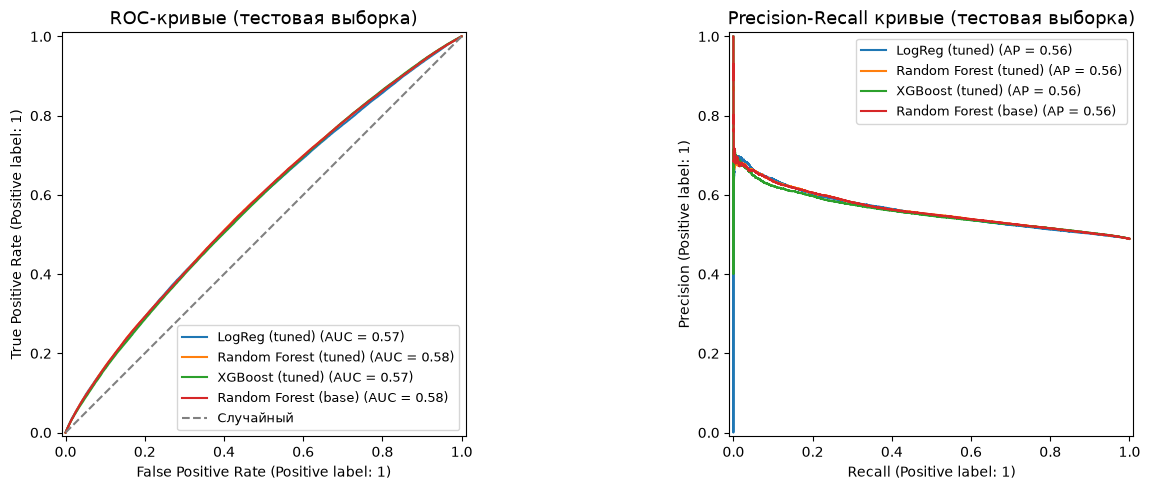

In [43]:
# ── FIX 8: PR-кривая через predict_proba (не predict) ───────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC-кривые обеих моделей
for name, res in final_results.items():
    RocCurveDisplay.from_predictions(y_test, res['y_prob'], name=name, ax=axes[0])
axes[0].plot([0,1],[0,1], linestyle='--', color='grey', label='Случайный')
axes[0].set_title('ROC-кривые (тестовая выборка)', fontsize=13)
axes[0].legend(fontsize=9)

# PR-кривые обеих моделей
for name, res in final_results.items():
    PrecisionRecallDisplay.from_predictions(y_test, res['y_prob'], name=name, ax=axes[1])
axes[1].set_title('Precision-Recall кривые (тестовая выборка)', fontsize=13)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

In [44]:
# Classification Report лучшей модели
print(f'Classification Report - {best_final_name}')
print(classification_report(y_test, best['y_pred'],
                             target_names=['Класс 0 (рост ≤2%)', 'Класс 1 (рост >2%)']))

Classification Report - Random Forest (base)
                    precision    recall  f1-score   support

Класс 0 (рост ≤2%)       0.56      0.59      0.57    152478
Класс 1 (рост >2%)       0.55      0.52      0.53    146012

          accuracy                           0.56    298490
         macro avg       0.55      0.55      0.55    298490
      weighted avg       0.55      0.56      0.55    298490



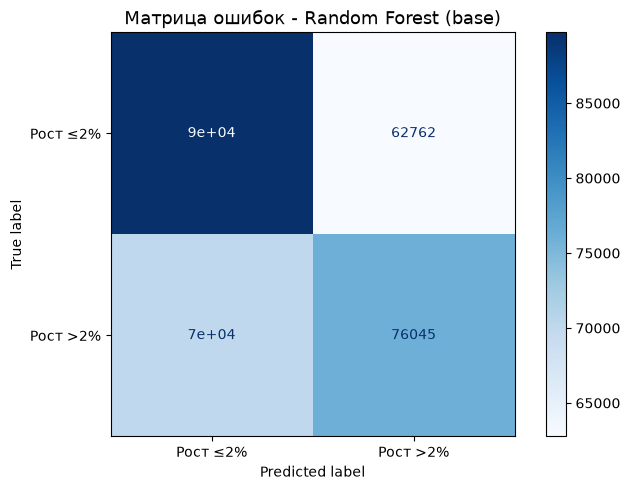

In [45]:
# Матрица ошибок лучшей модели
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, best['y_pred'],
    display_labels=['Рост ≤2%', 'Рост >2%'],
    cmap='Blues', ax=ax
)
ax.set_title(f'Матрица ошибок - {best_final_name}', fontsize=13)
plt.tight_layout()
plt.show()

False positive означает ошибку в событии опережения индекса, а не
обязательно денежный убыток. False negative также не определяет P&L.
Экономический результат рассчитывается по ценам исполнения отдельно.


In [46]:
# Внимание: метрика ниже - диагностическая, не торговая.
# Топ-50 по всему пулу теста приходят с двух-трёх дат, поэтому как оценка
# стратегии не читается. Подневный Precision@K - в ячейке финальной оценки.
sector_map = dict(zip(companies['Symbol'], companies['Sector']))
all_preds = expanding_preds[['Symbol', 'Date', 'y_true']].rename(
    columns={'y_true': 'Target'}).copy()
all_preds['Prob'] = expanding_preds['y_prob']
all_preds = all_preds.merge(df_sorted[['Date', 'Symbol', 'X_10']],
                            on=['Date', 'Symbol'], how='left')
all_preds['Sector'] = all_preds['Symbol'].map(sector_map)
# 2. ДЕДУПЛИКАЦИЯ
# Сортируем по вероятности (от высшей к низшей)
# Оставляем только ПЕРВОЕ упоминание каждого тикера (самый сильный сигнал)
unique_preds = all_preds.sort_values('Prob', ascending=False).drop_duplicates('Symbol')

# 3. ВЫБОР ТОП-K
# Теперь берем честные топ-50 уникальных компаний
K = 50
top_unique = unique_preds.head(K)

# 4. РАСЧЕТ НОВЫХ МЕТРИК
precision_at_k_unique = top_unique['Target'].mean()
baseline_rate = y_test.mean()

print(f"--- РЕЗУЛЬТАТЫ С ДЕДУПЛИКАЦИЕЙ (Top-{K} уникальных акций) ---")
print(f"Уникальных тикеров в тесте всего: {all_preds['Symbol'].nunique()}")
print(f"Precision@{K} (уникальные): {precision_at_k_unique:.3f}")
print(f"Базовый Win Rate: {baseline_rate:.3f}")
print(f"Честный Lift: {precision_at_k_unique / baseline_rate:.2f}x")

print("\nТоп-10 уникальных сигналов:")
print(top_unique[['Symbol', 'Sector', 'Prob', 'Date', 'Target', 'X_10']].head(10))

--- РЕЗУЛЬТАТЫ С ДЕДУПЛИКАЦИЕЙ (Top-50 уникальных акций) ---
Уникальных тикеров в тесте всего: 481
Precision@50 (уникальные): 0.860
Базовый Win Rate: 0.489
Честный Lift: 1.76x

Топ-10 уникальных сигналов:
       Symbol                  Sector      Prob       Date  Target       X_10
297350   MRNA              Healthcare  0.920547 2024-11-20       1 -28.499812
293592   SMCI              Technology  0.895741 2024-11-08       1 -51.354636
119579    KEY      Financial Services  0.886933 2023-06-01       1  -6.997823
56481    GNRC             Industrials  0.885376 2022-11-18       1  -3.566088
69116    TSLA       Consumer Cyclical  0.881565 2022-12-28       1 -24.090186
290655   PARA  Communication Services  0.877434 2024-10-31       0 -24.835655
295757   ENPH              Technology  0.867349 2024-11-15       1 -31.228261
18019     RCL       Consumer Cyclical  0.849469 2022-07-27       1   1.185336
267405   DXCM              Healthcare  0.847921 2024-08-23       0   0.743423
164146   PODD  

In [47]:
# Смотрим, на какие сектора модель делает ставку чаще всего
sector_counts = unique_preds.head(50)['Sector'].value_counts()
print("Распределение секторов в ТОП-50:")
print(sector_counts)

# Считаем точность (Win Rate) по каждому сектору в отдельности
sector_accuracy = unique_preds.head(50).groupby('Sector')['Target'].mean().sort_values(ascending=False)
print("\nТочность предсказаний по секторам:")
print(sector_accuracy)

Распределение секторов в ТОП-50:
Sector
Energy                    11
Technology                10
Financial Services         7
Healthcare                 5
Consumer Cyclical          5
Basic Materials            4
Communication Services     2
Utilities                  2
Consumer Defensive         2
Industrials                1
Real Estate                1
Name: count, dtype: int64

Точность предсказаний по секторам:
Sector
Consumer Cyclical         1.000000
Financial Services        1.000000
Consumer Defensive        1.000000
Utilities                 1.000000
Industrials               1.000000
Real Estate               1.000000
Energy                    0.909091
Technology                0.900000
Basic Materials           0.750000
Healthcare                0.600000
Communication Services    0.000000
Name: Target, dtype: float64


In [48]:
# Выбор секторов по реализованному Target теста создавал бы подгонку.
print('Секторальная статистика выше — диагностика; торговый фильтр по ней не строится.')


Секторальная статистика выше — диагностика; торговый фильтр по ней не строится.


In [49]:
# 1. Выбираем конкретную дату (например, самую последнюю в тесте)
target_date = '2023-01-03'

# 2. Фильтруем все прогнозы только за этот день
day_preds = all_preds[all_preds['Date'] == target_date]

# 3. Сортируем по вероятности и берем Топ-10
top_day_signals = day_preds.sort_values('Prob', ascending=False).head(10)

print(f"--- АНАЛИЗ СИГНАЛОВ ЗА ДАТУ: {target_date} ---")
print(f"Всего тикеров с прогнозом в этот день: {len(day_preds)}")
print(f"Средняя точность (Target) по всем акциям дня: {day_preds['Target'].mean():.3f}")
print("\nТоп-10 акций для покупки в этот день:")
print(top_day_signals[['Symbol', 'Sector', 'Prob', 'Target', 'X_10']])

# 4. Считаем точность именно этого "портфеля"
day_precision = top_day_signals['Target'].mean()
print(f"\nPrecision@10 для этого дня: {day_precision:.3f}")

--- АНАЛИЗ СИГНАЛОВ ЗА ДАТУ: 2023-01-03 ---
Всего тикеров с прогнозом в этот день: 477
Средняя точность (Target) по всем акциям дня: 0.562

Топ-10 акций для покупки в этот день:
      Symbol                  Sector      Prob  Target       X_10
70547   TSLA       Consumer Cyclical  0.872157       1 -27.311122
70314   GNRC             Industrials  0.795894       1   3.932796
70540    TPL                  Energy  0.732969       0 -15.730771
70271   ENPH              Technology  0.719819       0 -15.774268
70419   MRNA              Healthcare  0.688722       1  -6.665660
70275    EQT                  Energy  0.685585       1 -13.821704
70228   CRWD              Technology  0.682026       0  -6.639655
70154    APA                  Energy  0.671313       0   0.344323
70509   SMCI              Technology  0.670573       0   4.609661
70425   MTCH  Communication Services  0.667285       1  -1.365686

Precision@10 для этого дня: 0.500


Гипотезы об отскоке и momentum проверяются на текущем SHAP-графике.
Важность признака не определяет знак эффекта и не является торговой рекомендацией.


In [50]:
TRADING_DAYS_PER_YEAR = 252
def run_backtest(*args,**kwargs):
    kwargs.setdefault('top_k',TOP_K)
    kwargs.setdefault('capital',INITIAL_CAPITAL)
    kwargs.setdefault('commission',COMMISSION)
    return rr.run_backtest(*args,**kwargs)
def print_backtest(res):
    """Печатает отчёт по результату run_backtest."""
    m, p = res['metrics'], res['params']
    kind = 'Long+Short' if p['long_short'] else 'Long-Only'
    print()
    print('=' * 62)
    print(f"БЭКТЕСТ: {res['label']}  [{kind}]")
    print('=' * 62)
    print(f"Период:               {m['start'].date()} - {m['end'].date()} "
          f"({m['years']:.2f} г.)")
    print(f"Горизонт удержания:   {p['horizon']} торговых дней "
          f"({m['n_rebalances']} ребалансировок)")
    print(f"Стартовый капитал:    ${p['capital']:>10,.0f}")
    print(f"Финальный капитал:    ${m['final_capital']:>10,.0f}")
    print('-' * 62)
    print(f"Суммарная доходность: {m['total_return']:>+10.2%}")
    print(f"Годовая доходность:   {m['annual_return']:>+10.2%}")
    print(f"Sharpe Ratio:         {m['sharpe']:>10.2f}")
    print(f"Макс. просадка:       {m['max_drawdown']:>10.2%}")
    print('-' * 62)
    print(f"Всего сделок:         {m['n_trades']:>10,}")
    print(f"Win rate:             {m['win_rate']:>10.1%}")
    print(f"Средняя прибыль:      ${m['avg_win']:>9,.0f}")
    print(f"Средний убыток:       ${m['avg_loss']:>9,.0f}")
    print(f"Profit Factor:        {m['profit_factor']:>10.2f}")
    print('-' * 62)
    print(f"S&P 500 (индекс):     {m['bh_index']:>+10.2%}   "
          f"альфа: {m['alpha_vs_index']:>+7.2%}")
    print(f"Равновзвеш. портфель: {m['bh_equal_weight']:>+10.2%}   "
          f"альфа: {m['alpha_vs_equal_weight']:>+7.2%}")
    print('=' * 62)


def evaluate_strategy(res, benchmark='index'):
    """Таблица «цель / стоп» по результату бэктеста."""
    m = res['metrics']
    alpha = (m['alpha_vs_index'] if benchmark == 'index'
             else m['alpha_vs_equal_weight'])
    kind = 'Long+Short' if res['params']['long_short'] else 'Long-Only'
    bm_name = 'индекс' if benchmark == 'index' else 'равновзвеш.'

    checks = {
        'Sharpe Ratio': (m['sharpe'], 1.0, 0.5, '{:.2f}', False),
        'Макс. просадка': (m['max_drawdown'], -0.15, -0.30, '{:.2%}', True),
        'Profit Factor': (m['profit_factor'], 1.3, 1.0, '{:.2f}', False),
        f'Alpha vs {bm_name}': (alpha, 0.0, -0.10, '{:.2%}', False),
    }

    print(f"\n=== ОЦЕНКА СТРАТЕГИИ ({kind}): {res['label']} ===\n")
    print(f"{'Метрика':<22} {'Значение':>10}  {'Цель':>8}  {'Стоп':>8}  Статус")
    print('-' * 66)

    n_good = n_bad = 0
    for name, (val, good, bad, fmt, inverted) in checks.items():
        ok = val > good if inverted else val >= good
        fail = val < bad
        n_good += int(ok)
        n_bad += int(fail)
        status = 'Хорошо' if ok else ('Плохо' if fail else 'Терпимо')
        print(f'{name:<22} {fmt.format(val):>10}  {fmt.format(good):>8}  '
              f'{fmt.format(bad):>8}  {status}')

    print('-' * 66)
    print('\nИтоговый вердикт:')
    if n_bad == 0 and n_good >= 3:
        print('  Пройдены условные пороги; это не доказательство устойчивости стратегии')
    elif n_bad <= 1:
        print('  Стратегия требует доработки перед реальной торговлей')
    else:
        print('  Стратегия не готова к реальной торговле')

    return {'n_good': n_good, 'n_bad': n_bad}


def plot_backtest(res, color='#2c7fb8'):
    """Кривая капитала, просадка и P&L по периодам."""
    m, p = res['metrics'], res['params']
    eq, dd = res['equity'], res['drawdown']

    fig, axes = plt.subplots(3, 1, figsize=(14, 11))

    axes[0].plot(eq.index, eq['Capital'], color=color, linewidth=2,
                 label=res['label'])
    axes[0].axhline(p['capital'], color='grey', linestyle='--', alpha=0.5,
                    label='Стартовый капитал')
    axes[0].axhline(p['capital'] * (1 + m['bh_index']), color='#e67e22',
                    linestyle='--', alpha=0.8,
                    label=f"S&P 500 ({m['bh_index']:+.1%})")
    axes[0].axhline(p['capital'] * (1 + m['bh_equal_weight']), color='#16a085',
                    linestyle=':', alpha=0.8,
                    label=f"Равновзвеш. ({m['bh_equal_weight']:+.1%})")
    axes[0].fill_between(eq.index, p['capital'], eq['Capital'],
                         where=eq['Capital'] >= p['capital'],
                         alpha=0.15, color='green')
    axes[0].fill_between(eq.index, p['capital'], eq['Capital'],
                         where=eq['Capital'] < p['capital'],
                         alpha=0.15, color='red')
    axes[0].set_title(f"Кривая капитала - {res['label']} | "
                      f"Итог: ${m['final_capital']:,.0f} "
                      f"({m['total_return']:+.1%})",
                      fontsize=12, fontweight='bold')
    axes[0].set_ylabel('Капитал ($)')
    axes[0].legend(fontsize=9)
    axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
    axes[0].grid(alpha=0.3)

    axes[1].fill_between(dd.index, dd.values, 0, color=color, alpha=0.4)
    axes[1].axhline(-0.15, color='orange', linestyle='--', alpha=0.7,
                    label='Цель -15%')
    axes[1].axhline(-0.30, color='red', linestyle='--', alpha=0.7,
                    label='Стоп -30%')
    axes[1].set_title(f"Просадка | Макс: {m['max_drawdown']:.2%}",
                      fontsize=12, fontweight='bold')
    axes[1].set_ylabel('Просадка (%)')
    axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1%}'))
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    pnl = eq['Capital'].diff().dropna()
    axes[2].bar(pnl.index, pnl.values,
                color=['#2ecc71' if x >= 0 else '#e74c3c' for x in pnl],
                alpha=0.75, width=p['horizon'])
    axes[2].axhline(0, color='black', linewidth=0.8)
    axes[2].set_title('P&L по торговым периодам', fontsize=12, fontweight='bold')
    axes[2].set_ylabel('P&L ($)')
    axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
    axes[2].grid(alpha=0.3, axis='y')

    plt.tight_layout()
    return fig



БЭКТЕСТ: Static RF  [Long-Only]
Период:               2022-06-02 - 2024-11-22 (2.48 г.)
Горизонт удержания:   10 торговых дней (62 ребалансировок)
Стартовый капитал:    $   100,000
Финальный капитал:    $   122,892
--------------------------------------------------------------
Суммарная доходность:    +22.89%
Годовая доходность:       +8.69%
Sharpe Ratio:               0.41
Макс. просадка:          -29.97%
--------------------------------------------------------------
Всего сделок:                620
Win rate:                  50.5%
Средняя прибыль:      $    1,127
Средний убыток:       $   -1,074
Profit Factor:              1.07
--------------------------------------------------------------
S&P 500 (индекс):        +42.92%   альфа: -20.02%
Равновзвеш. портфель:    +39.64%   альфа: -16.75%


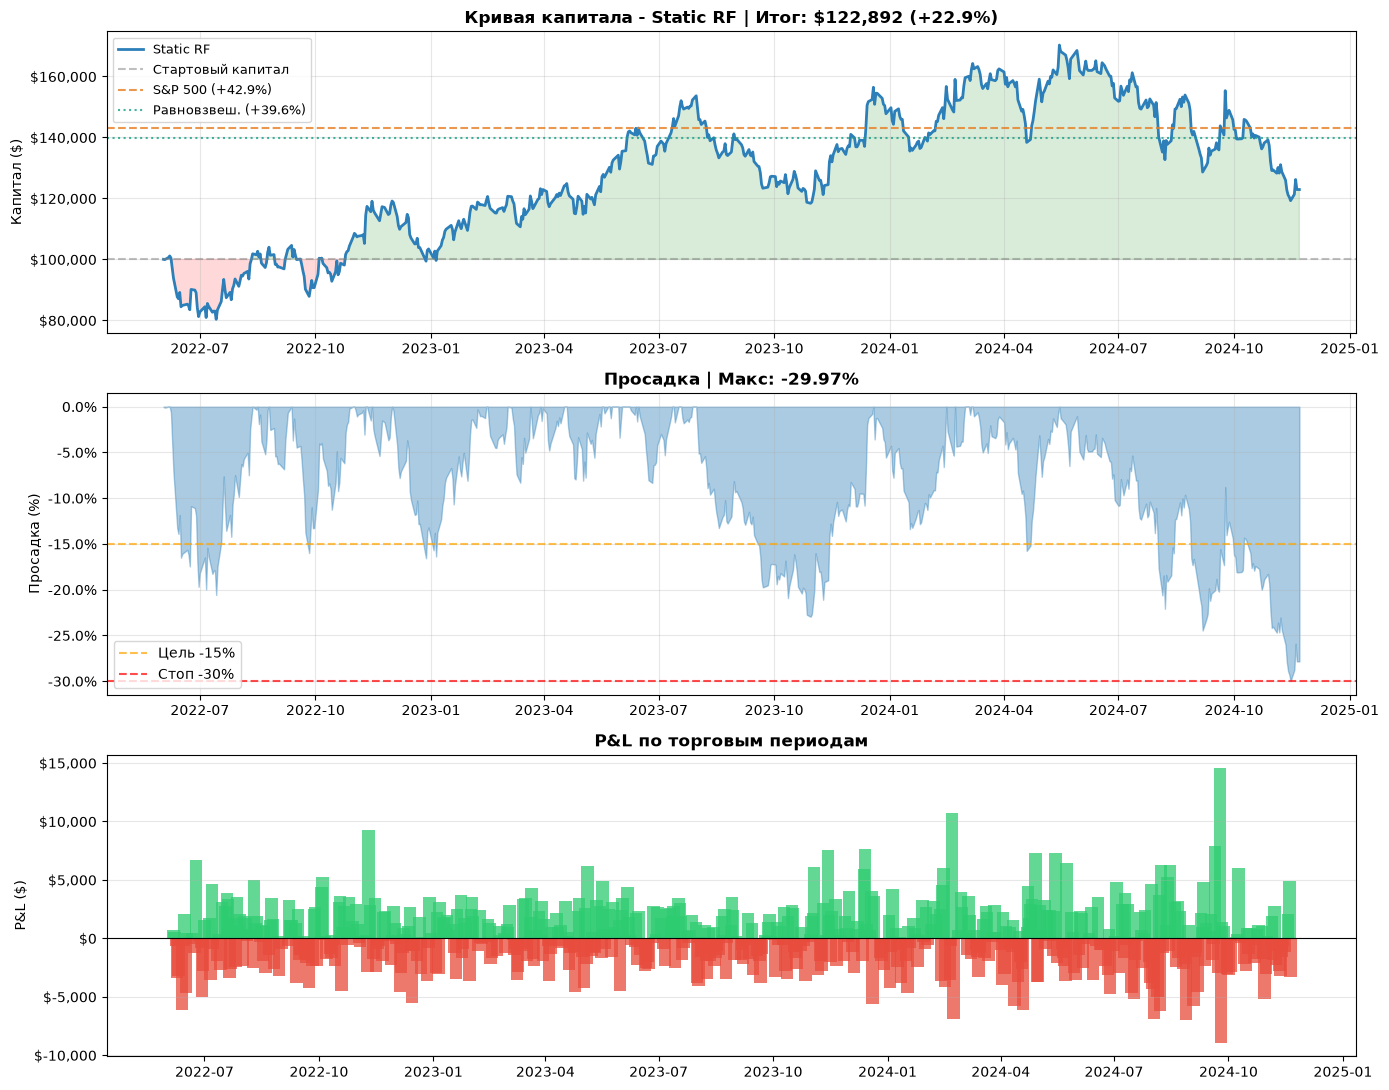

In [51]:
# Основной статический RF: та же конфигурация, что и walk-forward ниже
panel = full_price_panel.copy()
index_prices = index_df[['Date','SP500']].copy()
trade_test = df_prediction[df_prediction.Date.between(OOS_START,OOS_END)]
bt_preds = trade_test[['Date','Symbol','Target']].rename(columns={'Target':'y_true'}).copy()
bt_preds['y_prob'] = best['model'].predict_proba(trade_test[ALL_FEAT_COLS])[:,1]
res_expanding_full = run_backtest(bt_preds,panel,index_prices,horizon=HOLD_DAYS,
                                start=OOS_START,end=OOS_END,label='Static RF')
print_backtest(res_expanding_full)
plot_backtest(res_expanding_full)
plt.show()


| Метрика | Хорошо (> цель) | Плохо (< стоп) |
|:--------|:------------------:|:-----------------:|
| **Sharpe Ratio** | > 1.0 | < 0.5 |
| **Макс. просадка** | > -15% | < -30% |
| **Profit Factor** | > 1.3 | < 1.0 |
| **Alpha vs S&P 500** | > 0% | < -10% |


БЭКТЕСТ: Expanding, Random Forest (base)  [Long+Short]
Период:               2022-06-02 - 2024-11-22 (2.48 г.)
Горизонт удержания:   10 торговых дней (62 ребалансировок)
Стартовый капитал:    $   100,000
Финальный капитал:    $    92,223
--------------------------------------------------------------
Суммарная доходность:     -7.78%
Годовая доходность:       -3.22%
Sharpe Ratio:              -0.16
Макс. просадка:          -21.30%
--------------------------------------------------------------
Всего сделок:              1,240
Win rate:                  46.0%
Средняя прибыль:      $      337
Средний убыток:       $     -299
Profit Factor:              0.96
--------------------------------------------------------------
S&P 500 (индекс):        +42.92%   альфа: -50.69%
Равновзвеш. портфель:    +39.64%   альфа: -47.42%

=== ОЦЕНКА СТРАТЕГИИ (Long+Short): Expanding, Random Forest (base) ===

Метрика                  Значение      Цель      Стоп  Статус
----------------------------------------

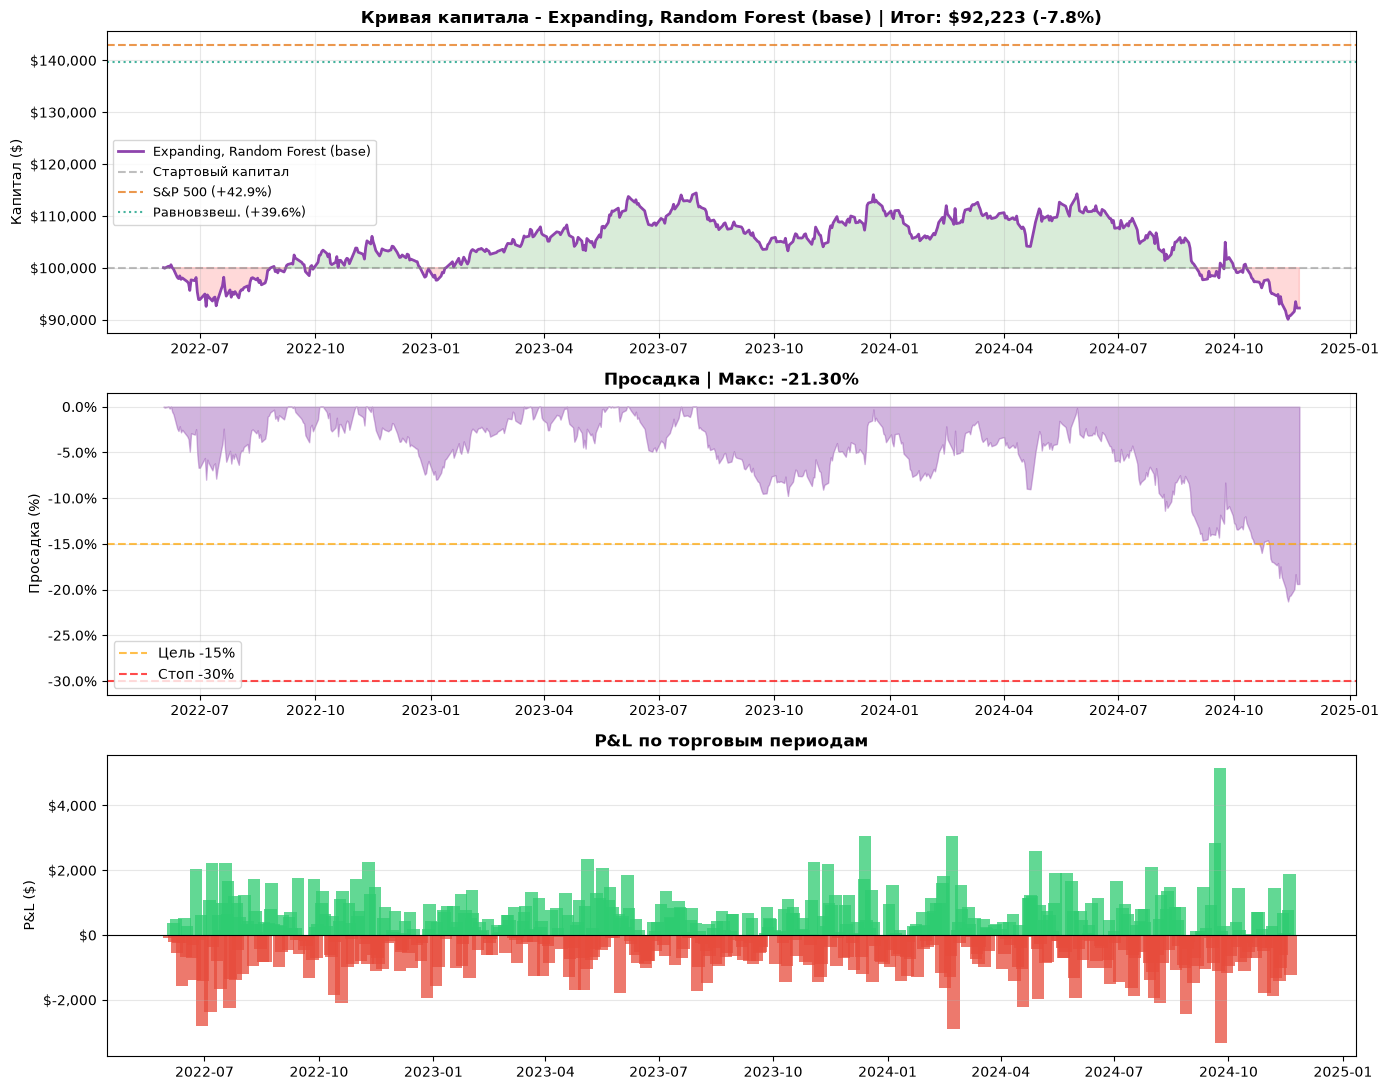


   Вариант Доходность Годовая Sharpe     MDD   PF Alpha vs S&P 500
 Long-Only    +22.89%  +8.69%   0.41 -29.97% 1.07          -20.02%
Long+Short     -7.78%  -3.22%  -0.16 -21.30% 0.96          -50.69%


In [52]:
# ── Тот же прогон в варианте Long+Short ─────────────────────────────────────
# Покупаем топ-K по вероятности и шортим нижние K. Капитал делится между
# двумя ногами, поэтому размер позиции вдвое меньше, чем в long-only.
res_long_short = run_backtest(
    bt_preds, panel, index_prices,
    horizon=HOLD_DAYS,
    start=expanding_preds['Date'].min(),
    end=expanding_preds['Date'].max(),
    long_short=True,
    label=f'Expanding, {best_final_name}')

print_backtest(res_long_short)
evaluate_strategy(res_long_short)
plot_backtest(res_long_short, color='#8e44ad')
plt.savefig(FIG_DIR / 'backtest_long_short.png', dpi=120, bbox_inches='tight')
plt.show()

# ── Сводка по вариантам стратегии ────────────────────────────────────────────
variants = pd.DataFrame([
    {'Вариант': 'Long-Only',
     **{k: res_expanding_full['metrics'][k]
        for k in ['total_return', 'annual_return', 'sharpe', 'max_drawdown',
                  'profit_factor', 'alpha_vs_index']}},
    {'Вариант': 'Long+Short',
     **{k: res_long_short['metrics'][k]
        for k in ['total_return', 'annual_return', 'sharpe', 'max_drawdown',
                  'profit_factor', 'alpha_vs_index']}},
]).rename(columns={'total_return': 'Доходность',
                   'annual_return': 'Годовая',
                   'sharpe': 'Sharpe',
                   'max_drawdown': 'MDD',
                   'profit_factor': 'PF',
                   'alpha_vs_index': 'Alpha vs S&P 500'})

for col in ['Доходность', 'Годовая', 'MDD', 'Alpha vs S&P 500']:
    variants[col] = variants[col].map('{:+.2%}'.format)
for col in ['Sharpe', 'PF']:
    variants[col] = variants[col].map('{:.2f}'.format)

print('\n' + variants.to_string(index=False))

Результаты выше относятся к static RF и дополнительному long/short примеру.
Основное сравнение форм окна и показателей риска приведено в разделе 3.7.
Пороговые таблицы не являются доказательством готовности стратегии к торговле.


Попробуем сделать ансмабль лучших моделей

In [53]:
from sklearn.ensemble import VotingClassifier

voting_clf = VotingClassifier(
    estimators=[
        ('lr',  tuned_estimators['LogReg (tuned)']),
        ('rf',  tuned_estimators['Random Forest (tuned)']),
        ('xgb', tuned_estimators['XGBoost (tuned)']),
    ],
    voting='soft',
    n_jobs=-1
)
voting_clf.fit(X_train, y_train)

y_prob_ens = voting_clf.predict_proba(X_test)[:, 1]
y_pred_ens = voting_clf.predict(X_test)

print(f"Ансамбль (Voting) на тесте:")
print(f"  ROC-AUC:  {roc_auc_score(y_test, y_prob_ens):.4f}")
print(f"  Avg Prec: {average_precision_score(y_test, y_prob_ens):.4f}")
print(f"  F1:       {f1_score(y_test, y_pred_ens):.4f}")
print(f"  Precision:{precision_score(y_test, y_pred_ens, zero_division=0):.4f}")
print(f"  Recall:   {recall_score(y_test, y_pred_ens):.4f}")
print()
print(classification_report(y_test, y_pred_ens,
      target_names=['Класс 0 (рост ≤2%)', 'Класс 1 (рост >2%)']))

Ансамбль (Voting) на тесте:
  ROC-AUC:  0.5815
  Avg Prec: 0.5643
  F1:       0.5285
  Precision:0.5539
  Recall:   0.5054

                    precision    recall  f1-score   support

Класс 0 (рост ≤2%)       0.56      0.61      0.59    152478
Класс 1 (рост >2%)       0.55      0.51      0.53    146012

          accuracy                           0.56    298490
         macro avg       0.56      0.56      0.56    298490
      weighted avg       0.56      0.56      0.56    298490



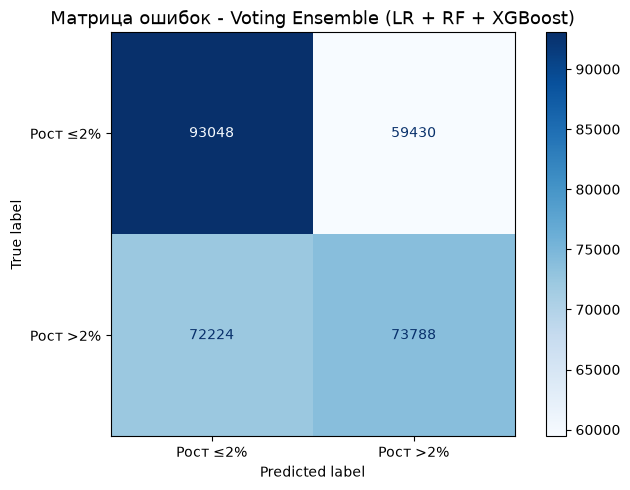

In [54]:
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, (y_prob_ens > 0.5).astype(int),
    display_labels=['Рост ≤2%', 'Рост >2%'],
    cmap='Blues', ax=ax
)
ax.set_title('Матрица ошибок - Voting Ensemble (LR + RF + XGBoost)', fontsize=13)
plt.tight_layout()
plt.show()

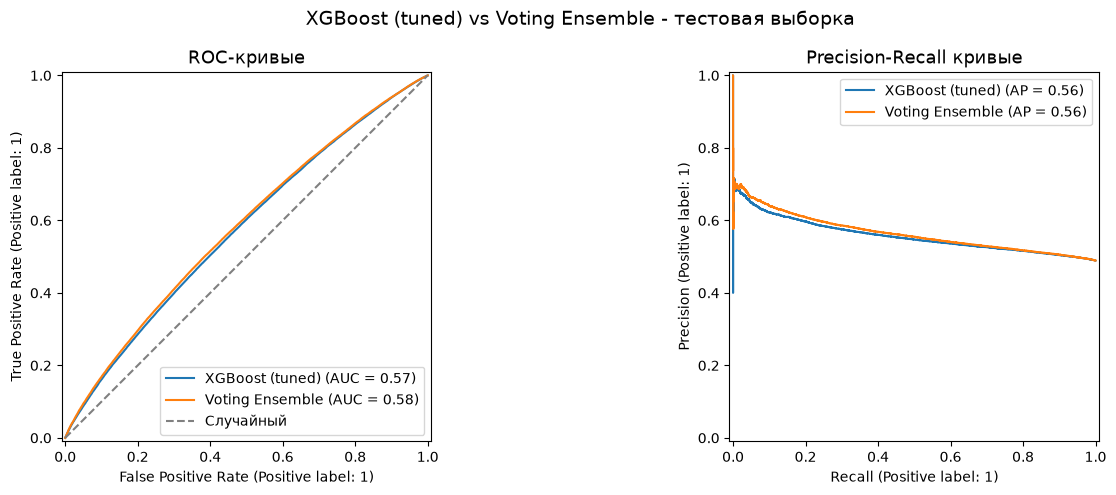

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Вероятности XGBoost tuned - уже посчитаны при финальной оценке
y_prob_xgb = final_results['XGBoost (tuned)']['y_prob']

# ROC-кривые
RocCurveDisplay.from_predictions(y_test, y_prob_xgb,   name='XGBoost (tuned)', ax=axes[0])
RocCurveDisplay.from_predictions(y_test, y_prob_ens,   name='Voting Ensemble', ax=axes[0])
axes[0].plot([0,1],[0,1], linestyle='--', color='grey', label='Случайный')
axes[0].set_title('ROC-кривые', fontsize=13)
axes[0].legend(fontsize=10)

# PR-кривые
PrecisionRecallDisplay.from_predictions(y_test, y_prob_xgb, name='XGBoost (tuned)', ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, y_prob_ens, name='Voting Ensemble', ax=axes[1])
axes[1].set_title('Precision-Recall кривые', fontsize=13)
axes[1].legend(fontsize=10)

plt.suptitle('XGBoost (tuned) vs Voting Ensemble - тестовая выборка', fontsize=14)
plt.tight_layout()
plt.show()

## 3.5 Скользящее окно (Sliding Window)

Train: последние 253 торговые даты. Purge: 10 дней. Test/step: 21 день.
Все OOS-прогнозы начинаются 2022-06-02; последний фолд может быть короче
21 дня, чтобы в точности завершиться 2024-11-22. Нет разных «общих» окон.


In [56]:
df_sorted_sw = df_prediction.copy()
models_sw = dict(make_models())
sw_preds,sw_fold_df = rr.walk_predict(df_sorted_sw,ALL_FEAT_COLS,models_sw,
    OOS_START,OOS_END,window=TRAIN_DAYS,gap=GAP_DAYS,step=STEP_DAYS,
    cache_dir=PRED_DIR/'sliding_models')
sw_fold_scores = {n:sw_fold_df.loc[sw_fold_df['Модель']==n,'ROC-AUC'].tolist() for n in models_sw}
SW_N_TRAIN,SW_N_TEST = int(sw_fold_df.n_train.mean()),int(sw_fold_df.n_test.mean())
sw_results_df = pd.DataFrame([{'Модель':n,'ROC-AUC (mean)':np.nanmean(sw_fold_scores[n]),
    'ROC-AUC (std)':np.nanstd(sw_fold_scores[n]),'ROC-AUC (пул)':roc_auc_score(sw_preds.loc[sw_preds.y_true.notna(),'y_true'],sw_preds.loc[sw_preds.y_true.notna(),n])}
    for n in models_sw]).sort_values('ROC-AUC (mean)',ascending=False)
sw_preds.to_parquet(PRED_DIR/'sliding_preds.parquet',index=False)
sw_fold_df.to_csv(PRED_DIR/'sliding_fold_scores.csv',index=False)
display(sw_results_df)


fold 1/30 train=120,229 test=10,017
fold 2/30 train=120,292 test=10,017
fold 3/30 train=120,355 test=10,017
fold 4/30 train=120,418 test=10,017
fold 5/30 train=120,481 test=10,017
fold 6/30 train=120,542 test=10,017
fold 7/30 train=120,584 test=10,017
fold 8/30 train=120,626 test=10,017
fold 9/30 train=120,653 test=10,038
fold 10/30 train=120,685 test=10,038
fold 11/30 train=120,713 test=10,038
fold 12/30 train=120,734 test=10,038
fold 13/30 train=120,755 test=10,038
fold 14/30 train=120,776 test=10,038
fold 15/30 train=120,797 test=10,038
fold 16/30 train=120,818 test=10,038
fold 17/30 train=120,839 test=10,038
fold 18/30 train=120,860 test=10,038
fold 19/30 train=120,881 test=10,040
fold 20/30 train=120,902 test=10,059
fold 21/30 train=120,936 test=10,059
fold 22/30 train=120,968 test=10,059
fold 23/30 train=120,989 test=10,059
fold 24/30 train=121,010 test=10,071
fold 25/30 train=121,033 test=10,080
fold 26/30 train=121,075 test=10,080
fold 27/30 train=121,117 test=10,080
fold 28/30

,Модель,ROC-AUC (mean),ROC-AUC (std),ROC-AUC (пул)
1,Random Forest,0.560581,0.045421,0.559941
3,Gradient Boosting,0.552471,0.044836,0.554823
2,XGBoost,0.549175,0.042067,0.551563
0,Logistic Regression,0.542809,0.045114,0.546862
4,KNN,0.520744,0.019460,0.523205


In [ ]:
# Оценочные прогнозы и календарь сохранены выше.
# Последняя модель фолда не выдаётся за модель на всей истории.
print(PRED_DIR/'sliding_fold_scores.csv')


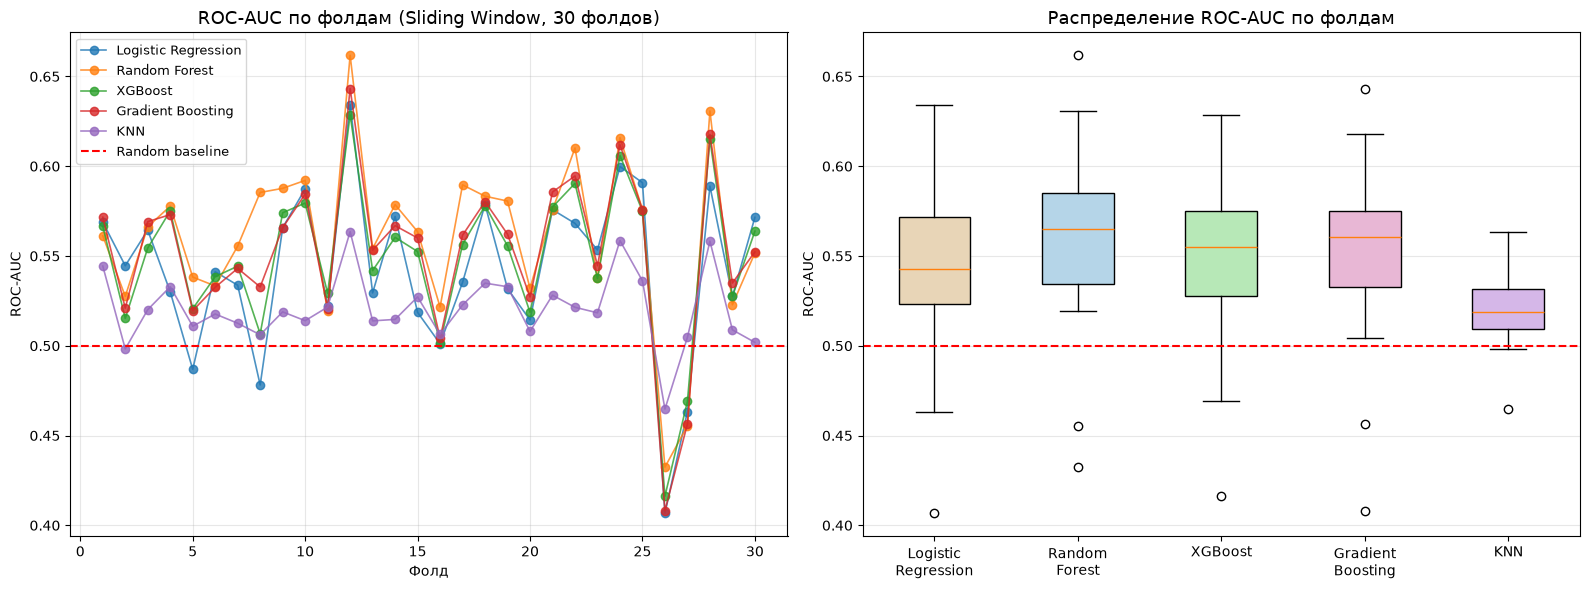

In [57]:
# ── Динамика ROC-AUC по фолдам ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

n_folds_plot = len(sw_fold_scores[next(iter(models_sw))])
marker = 'o' if n_folds_plot <= 30 else None   # при 94 фолдах маркеры сливаются

for name in models_sw:
    axes[0].plot(range(1, len(sw_fold_scores[name]) + 1),
                 sw_fold_scores[name],
                 marker=marker, label=name, alpha=0.8, linewidth=1.2)

axes[0].axhline(0.5, color='red', linestyle='--',
                linewidth=1.5, label='Random baseline')
axes[0].set_title(f'ROC-AUC по фолдам (Sliding Window, {n_folds_plot} фолдов)',
                  fontsize=13)
axes[0].set_xlabel('Фолд')
axes[0].set_ylabel('ROC-AUC')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

# Boxplot
data_box   = [sw_fold_scores[n] for n in models_sw]
labels_box = [n.replace(' ', '\n') for n in models_sw]
bp = axes[1].boxplot(data_box, tick_labels=labels_box, patch_artist=True)
colors_bp  = ['#e8d5b7', '#b5d5e8', '#b7e8b7', '#e8b7d5', '#d5b7e8']
for patch, c in zip(bp['boxes'], colors_bp):
    patch.set_facecolor(c)
axes[1].axhline(0.5, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title('Распределение ROC-AUC по фолдам', fontsize=13)
axes[1].set_ylabel('ROC-AUC')
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(FIG_DIR / 'sliding_window_folds.png', dpi=120, bbox_inches='tight')
plt.show()

Пофолдовые графики описывают текущий прогон. Соседние фолды зависимы;
выбор победителя по визуальному расстоянию кривых не обоснован.
Формальная проверка приведена ниже.


In [58]:
# ══════════════════════════════════════════════════════════════════════════════
# Precision@K для скользящего окна
#
# Метрика считается ТОЛЬКО подневно. Прежний вариант брал топ-50 строк по
# всему пулу предсказаний сразу; такие 50 наблюдений приходят с двух-трёх
# дат, и торгового смысла у полученного числа нет.
# ══════════════════════════════════════════════════════════════════════════════

sector_map = dict(zip(companies['Symbol'], companies['Sector']))

sw_view = sw_preds[['Date', 'Symbol', 'y_true', 'fold']].copy()
sw_view['y_prob'] = sw_preds[BASE_MODEL]
sw_view['Sector'] = sw_view['Symbol'].map(sector_map)
sw_view = sw_view.merge(df_sorted_sw[['Date', 'Symbol', 'X_10']],
                        on=['Date', 'Symbol'], how='left')

baseline_sw = sw_view['y_true'].mean()
print(f'Уникальных тикеров: {sw_view["Symbol"].nunique()} | '
      f'наблюдений: {len(sw_view):,}')
print(f'Базовая доля класса 1: {baseline_sw:.3f}')

# ── Precision@K по дням ──────────────────────────────────────────────────────
print(f'\n{"K":>5}  {"Precision@K":>12}  {"Lift":>7}  {"Дней":>6}')
print('-' * 36)
prec_rows = []
for k in [1, 3, 5, 10, 20, 50]:
    per_day = (sw_view.groupby('Date', group_keys=False)
               .apply(lambda x: x.nlargest(min(k, len(x)), 'y_prob')['y_true'].mean()))
    prec_rows.append({'K': k, 'Precision@K': per_day.mean(),
                      'Lift': per_day.mean() / baseline_sw,
                      'Дней': len(per_day)})
    print(f'{k:>5}  {per_day.mean():>12.3f}  '
          f'{per_day.mean() / baseline_sw:>6.2f}x  {len(per_day):>6}')

precision_sw_df = pd.DataFrame(prec_rows)

# ── Распределение по секторам ────────────────────────────────────────────────
top10_daily = (sw_view.groupby('Date', group_keys=False)
               .apply(lambda x: x.nlargest(min(10, len(x)), 'y_prob')))

sector_stats = (top10_daily.groupby('Sector')
                .agg(Сигналов=('y_true', 'size'),
                     Точность=('y_true', 'mean'))
                .sort_values('Сигналов', ascending=False))
sector_stats['Lift'] = sector_stats['Точность'] / baseline_sw

print(f'\nСектора в дневных топ-10 (всего {len(top10_daily):,} сигналов):')
print(sector_stats.round(3).to_string())
print('\nСектора с малым числом сигналов интерпретировать нельзя - '
      'точность там\nсчитается по единицам наблюдений.')

# ── Сигналы за последнюю дату ────────────────────────────────────────────────
last_date = sw_view['Date'].max()
day = sw_view[sw_view['Date'] == last_date].nlargest(10, 'y_prob')

print(f'\n--- Сигналы за {last_date.date()} ---')
print(day[['Symbol', 'Sector', 'y_prob', 'y_true', 'X_10']]
      .to_string(index=False))
print(f'Precision@10 за этот день: {day["y_true"].mean():.3f} '
      f'(одна дата, не оценка стратегии)')

Уникальных тикеров: 481 | наблюдений: 298,490
Базовая доля класса 1: 0.489

    K   Precision@K     Lift    Дней
------------------------------------
    1         0.623    1.27x     624
    3         0.652    1.33x     624
    5         0.658    1.35x     624
   10         0.651    1.33x     624
   20         0.633    1.29x     624
   50         0.602    1.23x     624

Сектора в дневных топ-10 (всего 6,240 сигналов):
                        Сигналов  Точность   Lift
Sector                                           
Technology                  1904     0.679  1.387
Healthcare                   668     0.623  1.273
Energy                       640     0.641  1.310
Consumer Cyclical            627     0.722  1.477
Basic Materials              520     0.617  1.262
Financial Services           456     0.702  1.435
Communication Services       409     0.560  1.145
Consumer Defensive           406     0.564  1.153
Utilities                    297     0.690  1.411
Industrials                 

## 3.6 Статистическая значимость различий между алгоритмами

Основной интервал: circular moving-block bootstrap **смежных блоков по 21
торговому дню**, 2 000 повторов. День переносится вместе со всеми акциями;
смежные дни сохраняют зависимость перекрывающихся меток. Отдельные дни iid
этого не обеспечивали. Длина блока — заранее заданный параметр.

DeLong — диагностический iid-тест; его интервал не является гарантированной
нижней границей ширины. Nadeau–Bengio по фолдам — приближённая проверка
чувствительности к зависимости, а не точный тест walk-forward.
Попарные p-values корректируются Holm. Bootstrap p вычисляется с центрированием
при нулевой гипотезе и plus-one, поэтому нулевые p не печатаются.


In [59]:
# ══════════════════════════════════════════════════════════════════════════════
# ПРОВЕРКА СТАТИСТИЧЕСКОЙ ЗНАЧИМОСТИ РАЗЛИЧИЙ МЕЖДУ АЛГОРИТМАМИ
#
# Разброс ROC-AUC между моделями - доли процента при std по фолдам ~0.03.
# Без формальной проверки утверждение «модель A лучше модели B» не имеет
# основания. Используются три независимых инструмента:
#
#   1. DeLong - точный тест на разность двух коррелированных ROC-AUC,
#      посчитанных на одной и той же выборке. Предполагает независимость
#      наблюдений, которой у панельных данных нет, поэтому служит нижней
#      границей ширины интервала.
#   2. Блочный bootstrap по датам - ресэмплирует торговые дни целиком,
#      сохраняя кросс-секционную корреляцию внутри дня и перекрытие
#      10-дневных таргетов. Независимости наблюдений не требует, поэтому
#      служит основным интервалом; насколько он окажется шире DeLong,
#      зависит от того, как сильно разрыв между моделями меняется день ото дня.
#   3. Парные тесты по фолдам - критерий Уилкоксона и скорректированный
#      парный t-тест Nadeau-Bengio (поправка на пересечение обучающих
#      выборок соседних фолдов). Поправка Холма на множественные сравнения.
# ══════════════════════════════════════════════════════════════════════════════


def _midrank(x):
    """Ранги с усреднением связок (midranks)."""
    order = np.argsort(x)
    sorted_x = x[order]
    n = len(x)
    ranks_sorted = np.empty(n, dtype=float)

    i = 0
    while i < n:
        j = i
        while j < n and sorted_x[j] == sorted_x[i]:
            j += 1
        ranks_sorted[i:j] = 0.5 * (i + j - 1) + 1
        i = j

    ranks = np.empty(n, dtype=float)
    ranks[order] = ranks_sorted
    return ranks


def _fast_delong(scores_by_model, n_pos):
    """Быстрый алгоритм DeLong (Sun & Xu, 2014).

    Args:
        scores_by_model: массив (k, n), столбцы отсортированы так, что первые
            `n_pos` наблюдений - класс 1.
        n_pos: число положительных наблюдений.

    Returns:
        (aucs, cov) - оценки AUC для k моделей и их ковариационная матрица.
    """
    m = n_pos
    n = scores_by_model.shape[1] - m
    k = scores_by_model.shape[0]

    positive = scores_by_model[:, :m]
    negative = scores_by_model[:, m:]

    tx = np.empty((k, m))
    ty = np.empty((k, n))
    tz = np.empty((k, m + n))
    for r in range(k):
        tx[r] = _midrank(positive[r])
        ty[r] = _midrank(negative[r])
        tz[r] = _midrank(scores_by_model[r])

    aucs = tz[:, :m].sum(axis=1) / m / n - (m + 1) / (2 * n)
    v01 = (tz[:, :m] - tx) / n
    v10 = 1 - (tz[:, m:] - ty) / m

    sx = np.cov(v01)
    sy = np.cov(v10)
    if k == 1:                       # np.cov схлопывает размерность
        sx = np.array([[float(sx)]])
        sy = np.array([[float(sy)]])

    return aucs, sx / m + sy / n


def delong_test(y_true, prob_a, prob_b, alpha=0.05):
    """Тест DeLong на равенство двух коррелированных ROC-AUC.

    Returns:
        Словарь с AUC обеих моделей, разностью, доверительным интервалом
        разности, z-статистикой и двусторонним p-value.
    """
    y_true = np.asarray(y_true)
    n_pos = int((y_true == 1).sum())
    if n_pos == 0 or n_pos == len(y_true):
        raise ValueError('DeLong: в выборке присутствует только один класс')

    order = np.argsort(-y_true, kind='mergesort')   # сначала класс 1

    scores = np.vstack([np.asarray(prob_a)[order], np.asarray(prob_b)[order]])
    aucs, cov = _fast_delong(scores, n_pos)

    diff = aucs[0] - aucs[1]
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    se = np.sqrt(max(var, 0.0))

    z = diff / se if se > 0 else 0.0
    p = 2 * (1 - norm.cdf(abs(z)))
    half = norm.ppf(1 - alpha / 2) * se

    return {'auc_a': aucs[0], 'auc_b': aucs[1], 'diff': diff, 'se': se,
            'ci_low': diff - half, 'ci_high': diff + half, 'z': z, 'p': p}


def block_bootstrap_aucs(df, model_names, n_boot=1000, alpha=0.05, seed=SEED):
    """Блочный bootstrap ROC-AUC сразу для всех моделей на общих выборках.

    Ключевой момент - общие драйвы. Раньше каждая из 10 пар строила свои
    бутстреп-выборки: 4000 ресэмплирований и 8000 вычислений AUC вместо 400
    и 2000. Помимо скорости это даёт и более корректную картину: все попарные
    разности считаются на одних и тех же выборках дат, поэтому интервалы
    разных пар сопоставимы между собой.

    Args:
        df: датафрейм со столбцами Date, y_true и по столбцу на модель.
        model_names: имена столбцов с вероятностями.
        n_boot: число бутстреп-повторений.
        alpha: уровень значимости для интервалов.

    Returns:
        Словарь с наблюдёнными AUC, матрицей драйвов (n_boot x n_models),
        интервалами и p-value против AUC = 0.5.
    """
    rng = np.random.default_rng(seed)

    # Ресэмплируются позиции строк, а не сами строки: копировать панель на
    # каждой итерации слишком дорого и по времени, и по памяти.
    date_positions = list(df.groupby('Date').indices.values())
    n_days = len(date_positions)

    y = df['y_true'].to_numpy()
    probs = np.column_stack([df[name].to_numpy() for name in model_names])

    observed = {name: roc_auc_score(y, probs[:, k])
                for k, name in enumerate(model_names)}

    draws = np.full((n_boot, len(model_names)), np.nan)
    for b in range(n_boot):
        picked = rr.circular_blocks(n_days, BOOT_BLOCK_DAYS, rng)
        rows = np.concatenate([date_positions[i] for i in picked])
        y_b = y[rows]
        if y_b.min() == y_b.max():
            continue
        p_b = probs[rows]
        for k in range(len(model_names)):
            draws[b, k] = roc_auc_score(y_b, p_b[:, k])

    draws = draws[~np.isnan(draws).any(axis=1)]

    ci, p_vs_half = {}, {}
    for k, name in enumerate(model_names):
        lo, hi = np.quantile(draws[:, k], [alpha / 2, 1 - alpha / 2])
        ci[name] = (lo, hi)
        p_vs_half[name] = (1 + np.sum(np.abs(draws[:, k]-observed[name]) >= abs(observed[name]-.5))) / (len(draws)+1)

    return {'names': list(model_names), 'observed': observed, 'draws': draws,
            'ci': ci, 'p_vs_half': p_vs_half, 'n_boot': len(draws),
            'alpha': alpha}


def bootstrap_diff(boot, name_a, name_b):
    """Интервал и p-value для разности AUC двух моделей из общих драйвов."""
    ia = boot['names'].index(name_a)
    ib = boot['names'].index(name_b)
    d = boot['draws'][:, ia] - boot['draws'][:, ib]
    a = boot['alpha']
    lo, hi = np.quantile(d, [a / 2, 1 - a / 2])
    observed_diff = boot['observed'][name_a]-boot['observed'][name_b]
    p = (1+np.sum(np.abs(d-observed_diff) >= abs(observed_diff)))/(len(d)+1)
    return {'diff': boot['observed'][name_a] - boot['observed'][name_b],
            'ci_low': lo, 'ci_high': hi, 'p': min(p, 1.0),
            'n_boot': len(d)}


def block_bootstrap_auc_diff(df, col_a, col_b, n_boot=1000, alpha=0.05,
                             seed=SEED):
    """Разность AUC двух моделей. Обёртка над block_bootstrap_aucs."""
    boot = block_bootstrap_aucs(df, [col_a, col_b], n_boot=n_boot,
                                alpha=alpha, seed=seed)
    return bootstrap_diff(boot, col_a, col_b)


def corrected_paired_ttest(scores_a, scores_b, n_train, n_test):
    """Парный t-тест с поправкой Nadeau-Bengio на перекрытие обучающих выборок.

    Обычный парный t-тест по фолдам считает их независимыми. У скользящего
    окна соседние обучающие выборки пересекаются на 253-21 = 232 дня, из-за
    чего дисперсия разностей занижена, а p-value - оптимистично. Поправка
    домножает дисперсию на (1/k + n_test / n_train).

    Args:
        scores_a, scores_b: метрики по фолдам для двух моделей.
        n_train, n_test: типичные размеры обучающей и тестовой частей фолда.

    Returns:
        Словарь со средней разностью, t-статистикой, числом степеней
        свободы и двусторонним p-value.
    """
    d = np.asarray(scores_a) - np.asarray(scores_b)
    k = len(d)
    mean_d = d.mean()
    var_d = d.var(ddof=1)

    factor = 1 / k + n_test / n_train
    se = np.sqrt(factor * var_d)

    t_stat = mean_d / se if se > 0 else 0.0
    p = 2 * (1 - student_t.cdf(abs(t_stat), df=k - 1))

    return {'mean_diff': mean_d, 't': t_stat, 'df': k - 1, 'p': p,
            'se': se, 'n_folds': k}


def holm_correction(pvalues):
    """Нисходящая поправка Холма на множественные сравнения.

    Контролирует FWER без предположения о независимости тестов, в отличие
    от Бонферрони менее консервативна.
    """
    p = np.asarray(pvalues, dtype=float)
    m = len(p)
    order = np.argsort(p)
    adjusted = np.empty(m)

    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p[idx])
        adjusted[idx] = min(running, 1.0)

    return adjusted


def significance_report(fold_scores, pooled_preds=None, n_train=None,
                        n_test=None, n_boot=1000, alpha=0.05, boot=None):
    """Полная таблица попарных сравнений моделей.

    Args:
        fold_scores: {имя модели: список ROC-AUC по фолдам}.
        pooled_preds: датафрейм [Date, y_true, <имя модели>...] с вероятностями
            на объединённой OOS-выборке. Если None, DeLong и bootstrap
            пропускаются.
        n_train, n_test: размеры фолда для поправки Nadeau-Bengio.
        boot: готовый результат block_bootstrap_aucs на тех же моделях.
            Если передан, bootstrap не пересчитывается - это основной способ
            не платить за одни и те же выборки дважды.

    Returns:
        Датафрейм с результатами всех попарных тестов.
    """
    names = list(fold_scores)
    rows = []

    if pooled_preds is not None and boot is None:
        boot = block_bootstrap_aucs(pooled_preds, names, n_boot=n_boot,
                                    alpha=alpha)

    for i, a in enumerate(names):
        for b in names[i + 1:]:
            sa = np.asarray(fold_scores[a])
            sb = np.asarray(fold_scores[b])

            w_stat, w_p = wilcoxon(sa, sb, zero_method='wilcox',
                                   alternative='two-sided')
            nb = corrected_paired_ttest(sa, sb, n_train, n_test)

            row = {
                'Модель A': a, 'Модель B': b,
                'AUC A (фолды)': sa.mean(), 'AUC B (фолды)': sb.mean(),
                'Δ по фолдам': sa.mean() - sb.mean(),
                'Побед A': int((sa > sb).sum()), 'Фолдов': len(sa),
                'Wilcoxon p': w_p,
                'NB t': nb['t'], 'NB p': nb['p'],
            }

            if pooled_preds is not None:
                dl = delong_test(pooled_preds['y_true'],
                                 pooled_preds[a], pooled_preds[b], alpha)
                bs = bootstrap_diff(boot, a, b)
                row.update({
                    'Δ пул': dl['diff'],
                    'DeLong p': dl['p'],
                    'Bootstrap ДИ': f"[{bs['ci_low']:+.4f}, {bs['ci_high']:+.4f}]",
                    'Bootstrap p': bs['p'],
                })

            rows.append(row)

    out = pd.DataFrame(rows)
    for col, adj in [('Wilcoxon p', 'Wilcoxon p (Holm)'),
                     ('NB p', 'NB p (Holm)'),
                     ('DeLong p', 'DeLong p (Holm)'),
                     ('Bootstrap p', 'Bootstrap p (Holm)')]:
        if col in out:
            out[adj] = holm_correction(out[col])

    return out

Блочный bootstrap: 2000 выборок по 624 торговым дням, 298,490 строк...
Готово: 2000 валидных выборок

ТЕСТ 1. Отличие ROC-AUC от 0.5 (есть ли сигнал вообще)
Модель                  AUC (пул)         95% ДИ (bootstrap)          p
------------------------------------------------------------------------------
Logistic Regression        0.5469           [0.5297, 0.5623]     0.0005
Random Forest              0.5599           [0.5403, 0.5774]     0.0005
XGBoost                    0.5516           [0.5360, 0.5652]     0.0005
Gradient Boosting          0.5548           [0.5375, 0.5697]     0.0005
KNN                        0.5232           [0.5136, 0.5321]     0.0005
------------------------------------------------------------------------------
Доверительные интервалы построены блочным bootstrap по торговым дням:
день ресэмплируется целиком, поэтому кросс-секционная корреляция
внутри дня сохраняется; временная зависимость учитывается смежными блоками.

ТЕСТ 2. Попарные сравнения моделей
Фолдов

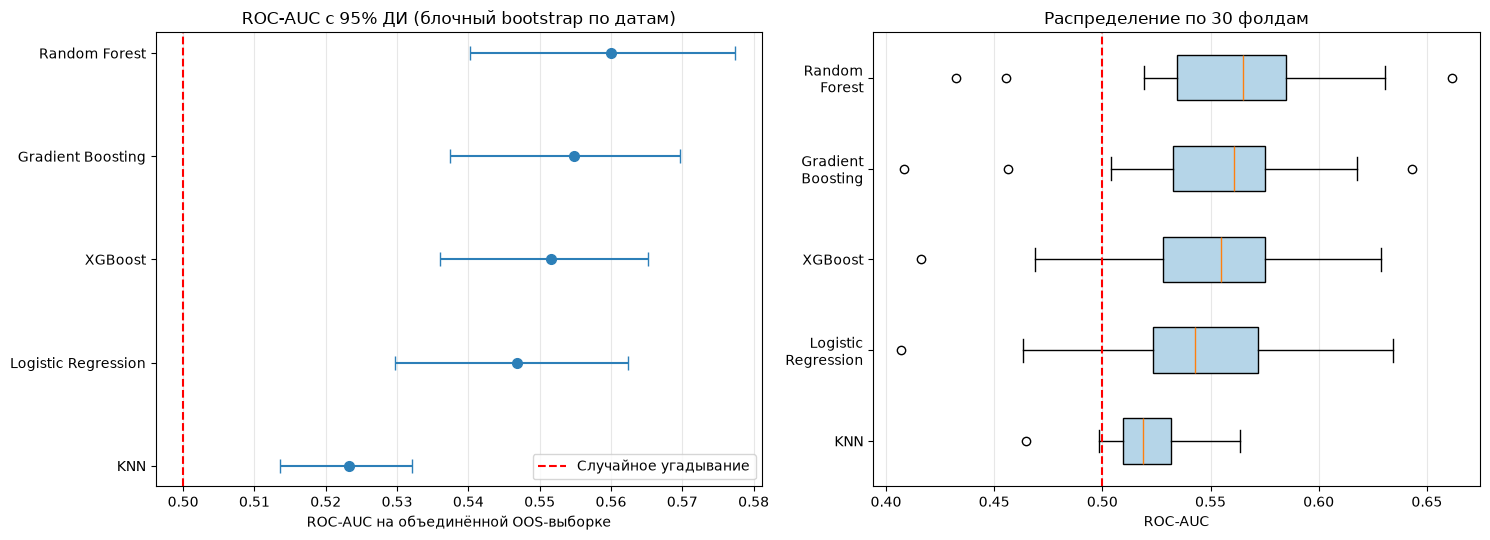

In [60]:
# ══════════════════════════════════════════════════════════════════════════════
# Значимость различий между алгоритмами
#
# Бутстреп-выборки строятся ОДИН раз и переиспользуются обоими тестами:
# 400 ресэмплирований вместо 4400, ~5 минут вместо ~30.
# ══════════════════════════════════════════════════════════════════════════════

model_names = list(models_sw)
scored_sw_preds = sw_preds.dropna(subset=['y_true']).copy()
N_BOOT = max(2000, N_BOOT)

print(f'Блочный bootstrap: {N_BOOT} выборок по '
      f'{sw_preds["Date"].nunique():,} торговым дням, {len(sw_preds):,} строк...')

boot = block_bootstrap_aucs(scored_sw_preds, model_names, n_boot=N_BOOT, alpha=0.05)
print(f'Готово: {boot["n_boot"]} валидных выборок\n')

# ── 1. Значимо ли отличие от случайного угадывания (AUC = 0.5) ──────────────
print('=' * 78)
print('ТЕСТ 1. Отличие ROC-AUC от 0.5 (есть ли сигнал вообще)')
print('=' * 78)
print(f'{"Модель":<22} {"AUC (пул)":>10} {"95% ДИ (bootstrap)":>26} {"p":>10}')
print('-' * 78)

for name in model_names:
    lo, hi = boot['ci'][name]
    print(f'{name:<22} {boot["observed"][name]:>10.4f} '
          f'{f"[{lo:.4f}, {hi:.4f}]":>26} {boot["p_vs_half"][name]:>10.4f}')

print('-' * 78)
print('Доверительные интервалы построены блочным bootstrap по торговым дням:\n'
      'день ресэмплируется целиком, поэтому кросс-секционная корреляция\n'
      'внутри дня сохраняется; временная зависимость учитывается смежными блоками.')

# ── 2. Попарные сравнения моделей ────────────────────────────────────────────
print('\n' + '=' * 78)
print('ТЕСТ 2. Попарные сравнения моделей')
print('=' * 78)
print(f'Фолдов: {len(sw_fold_scores[model_names[0]])} | '
      f'n_train ≈ {SW_N_TRAIN:,} | n_test ≈ {SW_N_TEST:,}')

sig_df = significance_report(
    {n: sw_fold_scores[n] for n in model_names},
    pooled_preds=scored_sw_preds[['Date', 'y_true'] + model_names],
    n_train=SW_N_TRAIN, n_test=SW_N_TEST,
    boot=boot,                      # те же выборки, что и в тесте 1
)

cols = ['Модель A', 'Модель B', 'Δ по фолдам', 'Побед A', 'Фолдов',
        'Δ пул', 'Bootstrap ДИ', 'Bootstrap p (Holm)',
        'DeLong p (Holm)', 'Wilcoxon p (Holm)', 'NB p (Holm)']
view = sig_df[cols].copy()
for col in ['Δ по фолдам', 'Δ пул']:
    view[col] = view[col].map('{:+.4f}'.format)
for col in ['Bootstrap p (Holm)', 'DeLong p (Holm)', 'Wilcoxon p (Holm)',
            'NB p (Holm)']:
    view[col] = view[col].map('{:.4f}'.format)
print('\n' + view.to_string(index=False))

# ── 3. Вердикт ───────────────────────────────────────────────────────────────
ALPHA = 0.05
sig_df['Значимо'] = ((sig_df['Bootstrap p (Holm)'] < ALPHA) &
                     (sig_df['NB p (Holm)'] < ALPHA))

n_sig = int(sig_df['Значимо'].sum())
print('\n' + '=' * 78)
print(f'ВЫВОД: значимых различий при α={ALPHA} (Holm, оба критерия): '
      f'{n_sig} из {len(sig_df)} пар')
print('=' * 78)

# Рядом с bootstrap-интервалом печатается Δ ПУЛ, а не Δ по фолдам:
# интервал построен для пулированной разности, и подставлять к нему другую
# оценку нельзя - она может лежать вне собственного интервала.
def _line(r):
    return (f'  {r["Модель A"]:<20} vs {r["Модель B"]:<20} '
            f'Δ пул = {r["Δ пул"]:+.4f}  ДИ {r["Bootstrap ДИ"]}  |  '
            f'Δ фолды = {r["Δ по фолдам"]:+.4f}  '
            f'(boot p={r["Bootstrap p (Holm)"]:.3f}, '
            f'NB p={r["NB p (Holm)"]:.3f})')

if n_sig:
    print('\nЗначимо по ОБОИМ критериям:')
    for _, r in sig_df[sig_df['Значимо']].iterrows():
        print(_line(r))

# Ключевое наблюдение: два критерия отвечают на разные вопросы и здесь
# систематически расходятся. Bootstrap оценивает точность ПУЛИРОВАННОГО
# AUC - при 332 тыс. наблюдений она высока, и почти всё выходит значимым.
# Nadeau-Bengio работает с 94 пофолдовыми AUC и учитывает, что фолды
# зависимы; там дисперсия определяется разбросом между рыночными режимами
# (std по фолдам 0.036-0.044 при разнице между моделями 0.004-0.020).
split = sig_df[(sig_df['Bootstrap p (Holm)'] < ALPHA) &
               (sig_df['NB p (Holm)'] >= ALPHA)]
if len(split):
    print(f'\nЗначимо в пуле, но НЕ устойчиво по фолдам ({len(split)} пар) - '
          'разрыв меньше,\nчем колебания качества от режима к режиму, '
          'поэтому порядок моделей не воспроизводится:')
    for _, r in split.iterrows():
        print(_line(r))

neither = sig_df[(sig_df['Bootstrap p (Holm)'] >= ALPHA) &
                 (sig_df['NB p (Holm)'] >= ALPHA)]
if len(neither):
    print(f'\nНе значимо ни по одному критерию ({len(neither)} пар):')
    for _, r in neither.iterrows():
        print(_line(r))

sig_df.to_csv(CACHE_DIR / 'significance_tests.csv', index=False,
              encoding='utf-8-sig')

# ── 4. Визуализация ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

order = sorted(model_names, key=lambda n: boot['observed'][n])
centres = [boot['observed'][n] for n in order]
lows = [max(0,boot['observed'][n] - boot['ci'][n][0]) for n in order]
highs = [max(0,boot['ci'][n][1] - boot['observed'][n]) for n in order]

axes[0].errorbar(centres, range(len(order)), xerr=[lows, highs], fmt='o',
                 capsize=5, color='#2c7fb8', markersize=7)
axes[0].axvline(0.5, color='red', linestyle='--', linewidth=1.5,
                label='Случайное угадывание')
axes[0].set_yticks(range(len(order)))
axes[0].set_yticklabels(order)
axes[0].set_xlabel('ROC-AUC на объединённой OOS-выборке')
axes[0].set_title('ROC-AUC с 95% ДИ (блочный bootstrap по датам)', fontsize=12)
axes[0].legend()
axes[0].grid(alpha=0.3, axis='x')

box_data = [sw_fold_scores[n] for n in order]
bp = axes[1].boxplot(box_data, orientation='horizontal', patch_artist=True,
                     tick_labels=[n.replace(' ', '\n') for n in order])
for patch in bp['boxes']:
    patch.set_facecolor('#b5d5e8')
axes[1].axvline(0.5, color='red', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('ROC-AUC')
axes[1].set_title(f'Распределение по {len(box_data[0])} фолдам', fontsize=12)
axes[1].grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig(FIG_DIR / 'model_significance.png', dpi=120, bbox_inches='tight')
plt.show()

## 3.7 Выровненное сравнение формы окна и обновления модели

Новый эксперимент добавляет expanding с тем же 21-дневным расписанием и
purge=10, что и sliding. Static используется как отдельный контроль.
Основные таблицы содержат Jensen alpha (годовой intercept CAPM, rf=0,
Newey–West HAC), beta и information ratio; простое превышение накопленной
доходности над индексом подписано отдельно и не называется Jensen alpha.

Бэктест: k=10; равные доли; сигнал после закрытия t, покупка на закрытии t+1;
выход через h сессий после покупки. Ежедневная переоценка. Комиссия за
фактический входной и выходной номинал; полная ликвидация и новая покупка,
включая повторно выбранные бумаги. Это консервативная модель исполнения,
а не минимальный net-turnover. Средний двухсторонний оборот =
(покупки+продажи)/капитал перед периодом; one-way = половина.
Без проскальзывания, дивидендов и стоимости шорта.

**21 день:** те же 10-дневные прогнозы, без переопределения Target и нового обучения.
Проверяется исполнение существующего сигнала; это не опыт с 21-дневной меткой.
Дополнительно h перекрывающихся портфелей с весом 1/h дают общую дневную сетку
для парного сравнения h=10/21. Неиспользованные деньги на краях остаются cash.


fold 1/30 train=745,341 test=10,017
fold 2/30 train=755,358 test=10,017
fold 3/30 train=765,375 test=10,017
fold 4/30 train=775,392 test=10,017
fold 5/30 train=785,409 test=10,017
fold 6/30 train=795,426 test=10,017
fold 7/30 train=805,443 test=10,017
fold 8/30 train=815,460 test=10,017
fold 9/30 train=825,477 test=10,038
fold 10/30 train=835,505 test=10,038
fold 11/30 train=845,543 test=10,038
fold 12/30 train=855,581 test=10,038
fold 13/30 train=865,619 test=10,038
fold 14/30 train=875,657 test=10,038
fold 15/30 train=885,695 test=10,038
fold 16/30 train=895,733 test=10,038
fold 17/30 train=905,771 test=10,038
fold 18/30 train=915,809 test=10,038
fold 19/30 train=925,847 test=10,040
fold 20/30 train=935,885 test=10,059
fold 21/30 train=945,936 test=10,059
fold 22/30 train=955,995 test=10,059
fold 23/30 train=966,054 test=10,059
fold 24/30 train=976,113 test=10,071
fold 25/30 train=986,174 test=10,080
fold 26/30 train=996,254 test=10,080
fold 27/30 train=1,006,334 test=10,080
fold 28/

,jensen_alpha,jensen_p,beta,information_ratio,total_return,alpha_vs_index,alpha_vs_equal_weight,sharpe,max_drawdown,profit_factor,avg_turnover,one_way_turnover,n_rebalances
static,-0.084216,0.556016,1.428503,-0.064347,0.22892,-0.200239,-0.167467,0.413834,-0.299748,1.069418,2.005162,1.002581,62
expanding,-0.017628,0.901876,1.431275,0.192647,0.447775,0.018616,0.051388,0.606878,-0.236769,1.135374,2.00777,1.003885,62
sliding,-0.062499,0.631755,1.371746,-0.015812,0.282873,-0.146286,-0.113515,0.470811,-0.237222,1.09639,2.005774,1.002887,62


,scheme,holding,cost_multiplier,total_return,jensen_alpha,alpha_vs_index,avg_turnover
0,static,10,1,0.228920,-0.084216,-0.200239,2.005162
1,static,10,3,-0.041001,-0.183651,-0.470160,2.001163
2,static,10,5,-0.251639,-0.282693,-0.680798,1.997181
3,static,21,1,0.067162,-0.151718,-0.361997,2.005826
4,static,21,3,-0.049719,-0.198814,-0.478878,2.001826
5,static,21,5,-0.153800,-0.245726,-0.582959,1.997842
6,expanding,10,1,0.447775,-0.017628,0.018616,2.007770
7,expanding,10,3,0.129785,-0.117078,-0.299374,2.003767
8,expanding,10,5,-0.118365,-0.216135,-0.547524,1.999779
9,expanding,21,1,0.229052,-0.094382,-0.200107,2.010616



БЭКТЕСТ: static  [Long-Only]
Период:               2022-06-02 - 2024-11-22 (2.48 г.)
Горизонт удержания:   10 торговых дней (62 ребалансировок)
Стартовый капитал:    $   100,000
Финальный капитал:    $   122,892
--------------------------------------------------------------
Суммарная доходность:    +22.89%
Годовая доходность:       +8.69%
Sharpe Ratio:               0.41
Макс. просадка:          -29.97%
--------------------------------------------------------------
Всего сделок:                620
Win rate:                  50.5%
Средняя прибыль:      $    1,127
Средний убыток:       $   -1,074
Profit Factor:              1.07
--------------------------------------------------------------
S&P 500 (индекс):        +42.92%   альфа: -20.02%
Равновзвеш. портфель:    +39.64%   альфа: -16.75%

БЭКТЕСТ: expanding  [Long-Only]
Период:               2022-06-02 - 2024-11-22 (2.48 г.)
Горизонт удержания:   10 торговых дней (62 ребалансировок)
Стартовый капитал:    $   100,000
Финальный капитал: 

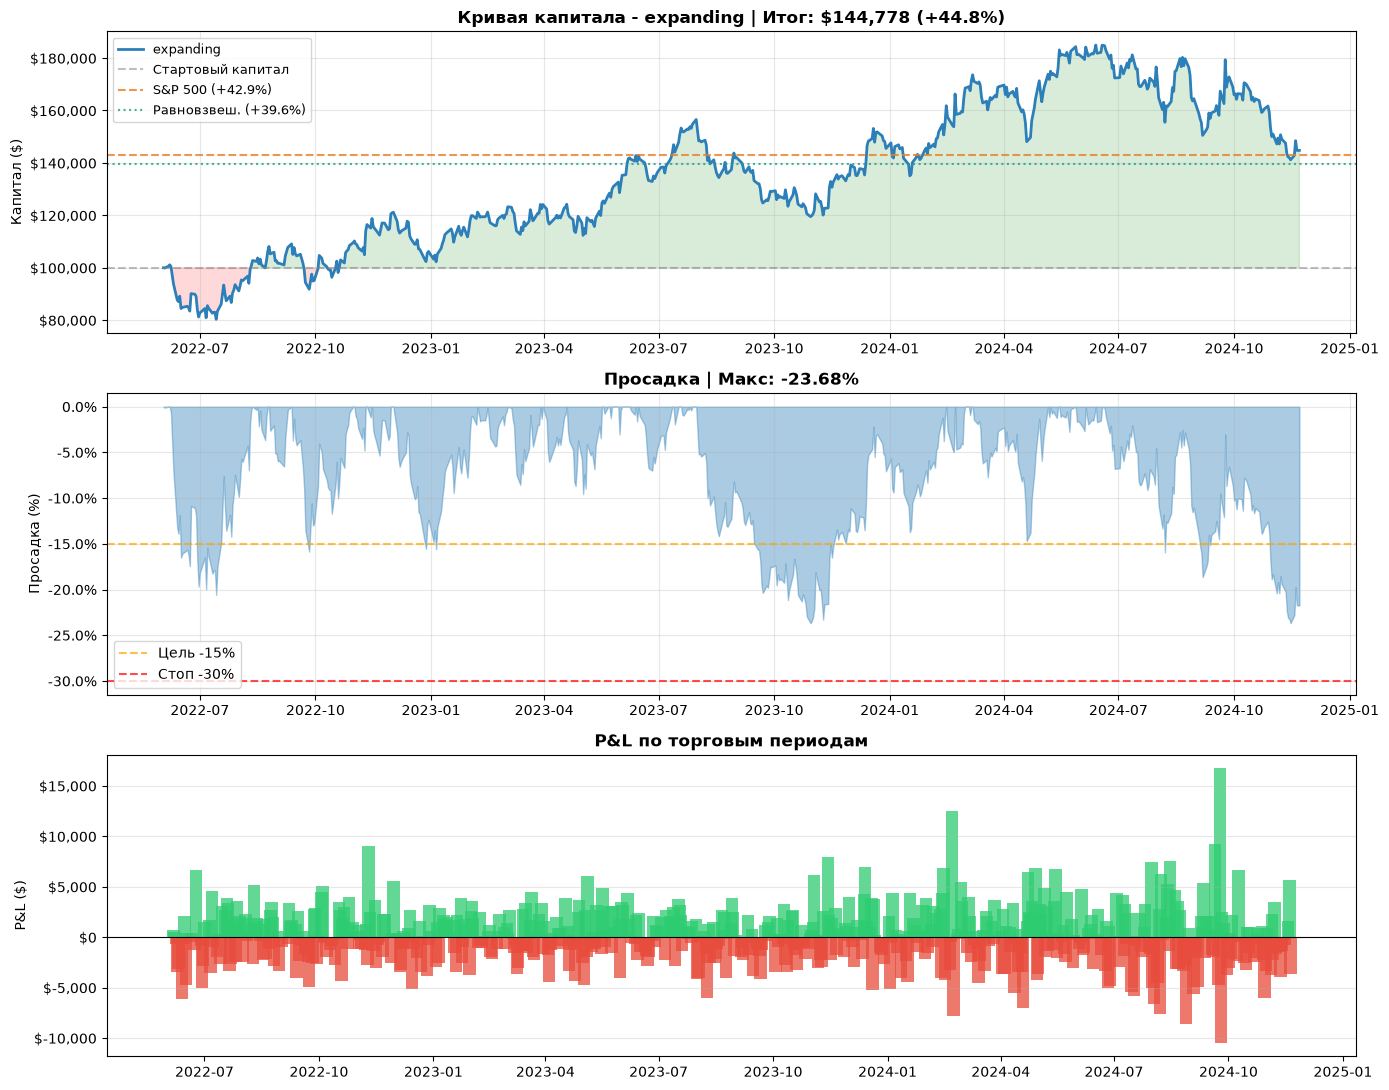

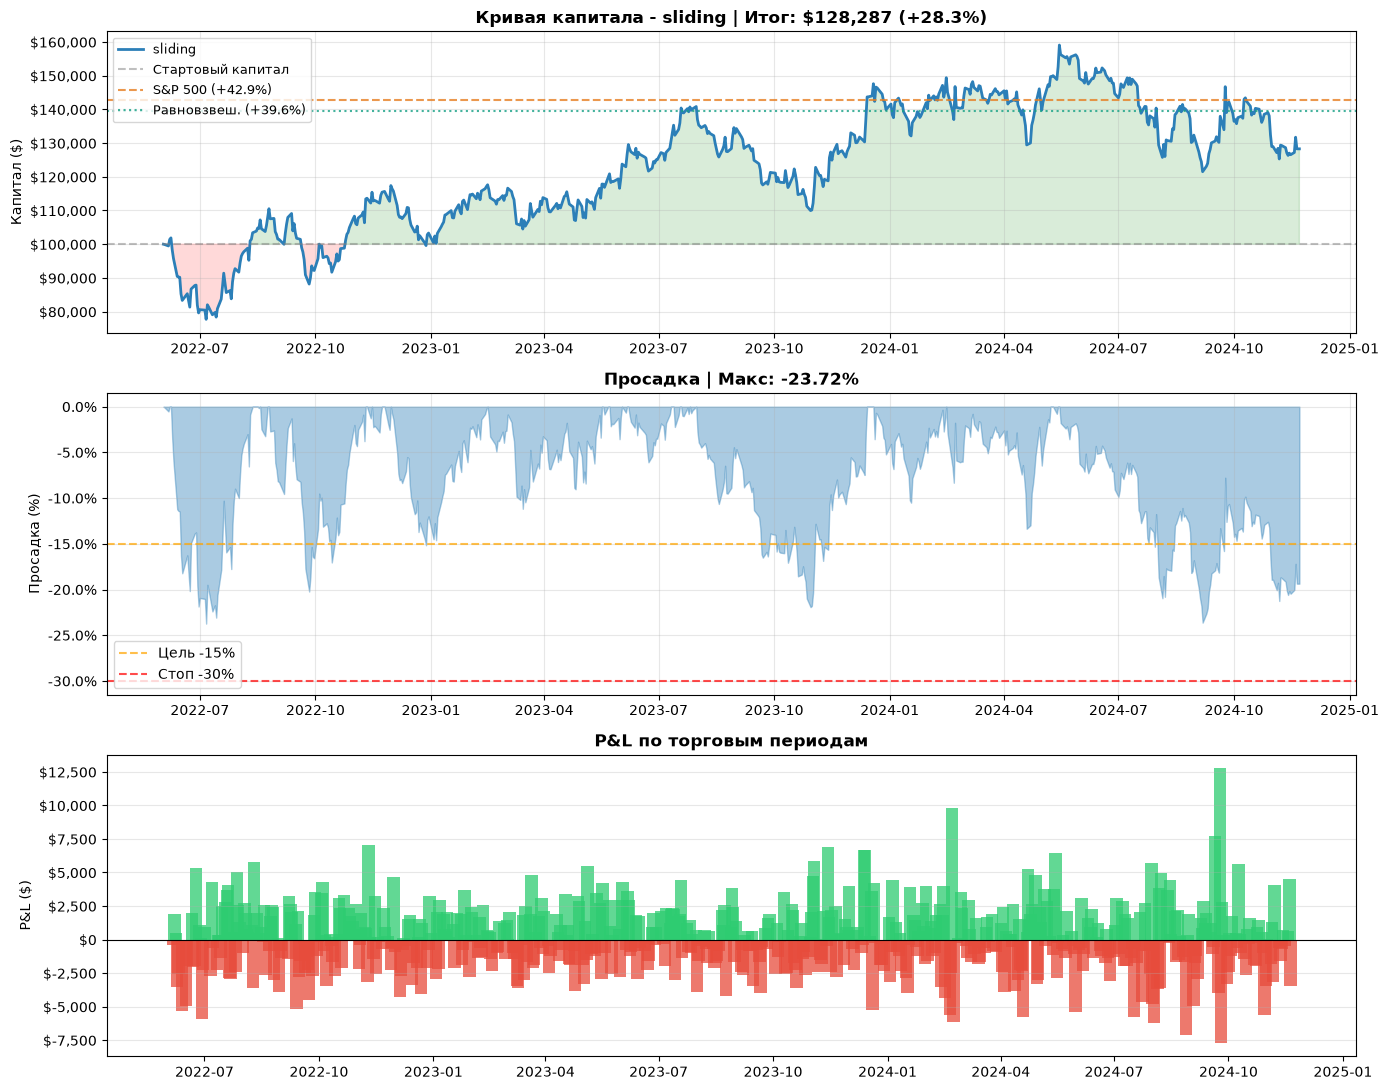

In [61]:
panel = full_price_panel.copy()
index_prices = index_df[['Date','SP500']].copy()
primary_models = {BASE_MODEL:dict(make_models())[BASE_MODEL]}
exp_monthly,exp_fold_df = rr.walk_predict(df_prediction,ALL_FEAT_COLS,primary_models,
    OOS_START,OOS_END,gap=GAP_DAYS,step=STEP_DAYS,cache_dir=PRED_DIR/'expanding_rf')
static_preds,static_fold_df = rr.walk_predict(df_prediction,ALL_FEAT_COLS,primary_models,
    OOS_START,OOS_END,gap=GAP_DAYS,step=STEP_DAYS,static=True,cache_dir=PRED_DIR/'static_rf')
common_start,common_end = OOS_START,OOS_END
def prep(preds,model_col=BASE_MODEL):
    return preds[['Date','Symbol','y_true',model_col]].rename(columns={model_col:'y_prob'}).copy()
pred_sources = {'static':static_preds,'expanding':exp_monthly,'sliding':sw_preds}
keys = exp_monthly[['Date','Symbol']].reset_index(drop=True)
for scheme,p in pred_sources.items():
    assert p[['Date','Symbol']].reset_index(drop=True).equals(keys),scheme
runs,robust_runs,cost_rows = {},{},[]
for scheme,p in pred_sources.items():
    runs[scheme] = run_backtest(prep(p),panel,index_prices,horizon=HOLD_DAYS,
        start=common_start,end=common_end,label=scheme)
    robust_runs[scheme] = run_backtest(prep(p),panel,index_prices,horizon=HOLD_DAYS_ROBUST,
        start=common_start,end=common_end,label=scheme+' h21')
    for h in [10,21]:
        for multiplier in [1,3,5]:
            result = run_backtest(prep(p),panel,index_prices,horizon=h,start=common_start,
                                 end=common_end,commission=COMMISSION*multiplier,label=scheme)
            cost_rows.append({'scheme':scheme,'holding':h,'cost_multiplier':multiplier,**result['metrics']})
comparison_df = pd.DataFrame({n:r['metrics'] for n,r in runs.items()}).T
main_cols = ['jensen_alpha','jensen_p','beta','information_ratio','total_return',
             'alpha_vs_index','alpha_vs_equal_weight','sharpe','max_drawdown',
             'profit_factor','avg_turnover','one_way_turnover','n_rebalances']
display(comparison_df[main_cols])
comparison_df.to_csv(CACHE_DIR/'primary_economic_comparison.csv')
cost_df = pd.DataFrame(cost_rows)
cost_df.to_csv(CACHE_DIR/'commission_stress.csv',index=False)
display(cost_df[['scheme','holding','cost_multiplier','total_return','jensen_alpha','alpha_vs_index','avg_turnover']])
for name,r in runs.items():
    r['equity'].to_csv(CACHE_DIR/f'equity_{name}.csv')
    r['trades'].to_csv(CACHE_DIR/f'trades_{name}.csv',index=False)
    print_backtest(r)
exp_fold_df.to_csv(CACHE_DIR/'expanding_fold_scores.csv',index=False)
static_fold_df.to_csv(CACHE_DIR/'static_fold_scores.csv',index=False)
plot_backtest(runs['expanding']); plt.show()
plot_backtest(runs['sliding']); plt.show()


In [62]:
# Парные дневные circular blocks: одна календарная сетка, без iid ресэмплинга дней
from itertools import combinations
test_rows = []
for block in [10,21,42]:
    for h,group in [(10,runs),(21,robust_runs)]:
        for a,b in [('expanding','sliding'),('expanding','static')]:
            bs = rr.paired_daily_bootstrap(group[a],group[b],n_boot=N_BOOT,block=block)
            test_rows.append({'comparison':a+' - '+b,'holding':h,'block':block,**bs})
alpha_tests = pd.DataFrame(test_rows)
alpha_tests['p_Holm'] = holm_correction(alpha_tests.p)
display(alpha_tests)
alpha_tests.to_csv(CACHE_DIR/'scheme_diff_significance.csv',index=False)

# Дополнительный опыт по замечанию 6: перекрывающиеся портфели, общая дневная сетка.
overlap_rows = []
overlap_results = {}
for scheme,p in pred_sources.items():
    pair = {h:rr.overlapping_backtest(prep(p),panel,index_prices,horizon=h,
                 start=common_start,end=common_end,top_k=TOP_K,commission=COMMISSION,
                 label=scheme+' overlapping') for h in [10,21]}
    overlap_results[scheme] = pair
    for block in [10,21,42]:
        bs = rr.paired_daily_bootstrap(pair[21],pair[10],n_boot=N_BOOT,block=block)
        overlap_rows.append({'scheme':scheme,'comparison':'hold21 - hold10','block':block,**bs})
overlap_tests = pd.DataFrame(overlap_rows)
overlap_tests['p_Holm'] = holm_correction(overlap_tests.p)
display(overlap_tests)
overlap_tests.to_csv(CACHE_DIR/'overlapping_horizon_tests.csv',index=False)
print('Незначимое различие не доказывает эквивалентности. '
      'Старые p-values статьи здесь не используются.')


,comparison,holding,block,diff,ci_low,ci_high,p,n_periods,n_boot,p_Holm
0,expanding - sliding,10,10,0.164903,-0.422418,0.961865,0.529235,623,2000,1.0
1,expanding - static,10,10,0.218855,-0.101330,0.757464,0.227386,623,2000,1.0
2,expanding - sliding,21,10,0.104328,-0.561520,1.062415,0.724638,623,2000,1.0
3,expanding - static,21,10,0.161890,-0.224416,0.750672,0.386307,623,2000,1.0
4,expanding - sliding,10,21,0.164903,-0.412271,0.933347,0.521239,623,2000,1.0
5,expanding - static,10,21,0.218855,-0.094166,0.708806,0.216392,623,2000,1.0
6,expanding - sliding,21,21,0.104328,-0.608834,1.052310,0.754123,623,2000,1.0
7,expanding - static,21,21,0.161890,-0.209890,0.822002,0.412294,623,2000,1.0
8,expanding - sliding,10,42,0.164903,-0.314614,0.915384,0.501749,623,2000,1.0
9,expanding - static,10,42,0.218855,-0.091459,0.778948,0.216392,623,2000,1.0


,scheme,comparison,block,diff,ci_low,ci_high,p,n_periods,n_boot,p_Holm
0,static,hold21 - hold10,10,0.090262,-0.153870,0.397116,0.436282,623,2000,1.000000
1,static,hold21 - hold10,21,0.090262,-0.172824,0.379522,0.426287,623,2000,1.000000
2,static,hold21 - hold10,42,0.090262,-0.180969,0.369799,0.450275,623,2000,1.000000
3,expanding,hold21 - hold10,10,0.174502,-0.092979,0.611431,0.247876,623,2000,1.000000
4,expanding,hold21 - hold10,21,0.174502,-0.120556,0.562644,0.239380,623,2000,1.000000
5,expanding,hold21 - hold10,42,0.174502,-0.120879,0.561249,0.242379,623,2000,1.000000
6,sliding,hold21 - hold10,10,0.249566,-0.015585,0.699464,0.122939,623,2000,0.908546
7,sliding,hold21 - hold10,21,0.249566,0.009516,0.651510,0.100950,623,2000,0.908546
8,sliding,hold21 - hold10,42,0.249566,0.024743,0.640136,0.101949,623,2000,0.908546


Незначимое различие не доказывает эквивалентности. Старые p-values статьи здесь не используются.


---
# 4. Интерпретация модели (SHAP)

SHAP (SHapley Additive exPlanations) - метод интерпретации, основанный на теории кооперативных игр.
Он отвечает на вопрос: **насколько каждый признак повлиял на конкретный прогноз?**


Модель для SHAP: RandomForestClassifier | признаков: 273
Подвыборка: 2,000 из 298,490 строк (доля класса 1: 0.489 против 0.489 на полной)
SHAP посчитан за 8.5 с


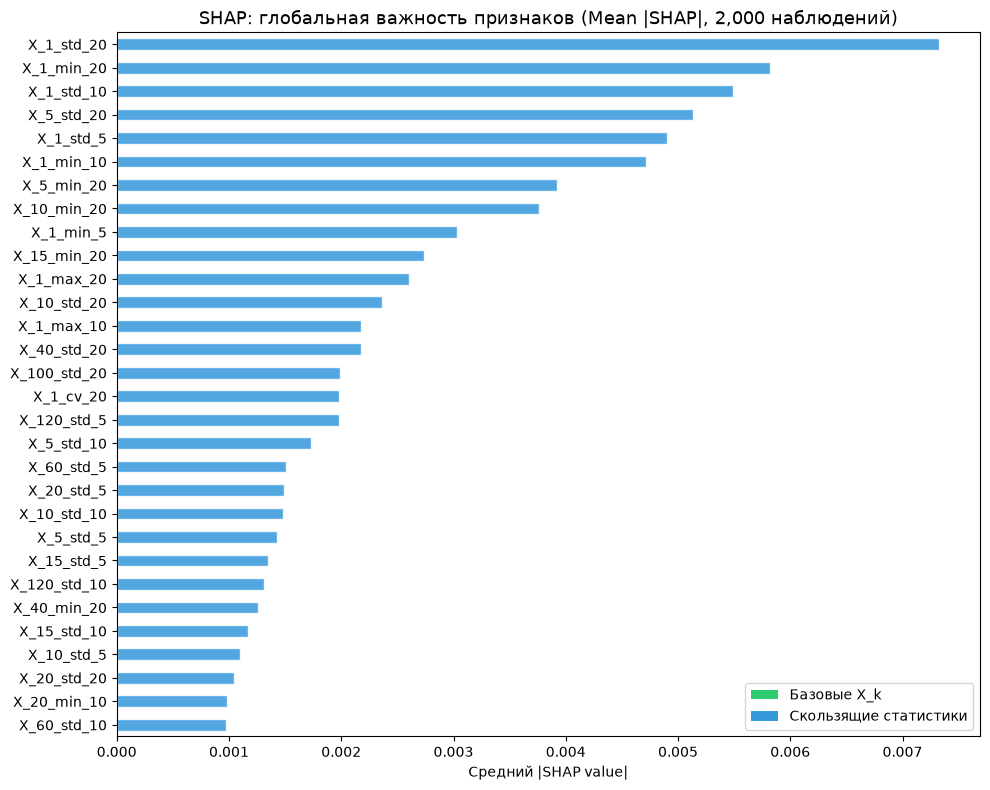


SHAP Summary Plot (распределение влияния каждого признака):


C:\Users\dima\AppData\Local\Temp\ipykernel_25680\128722403.py:108: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, X_shap, feature_names=FEATURE_COLS, show=False,


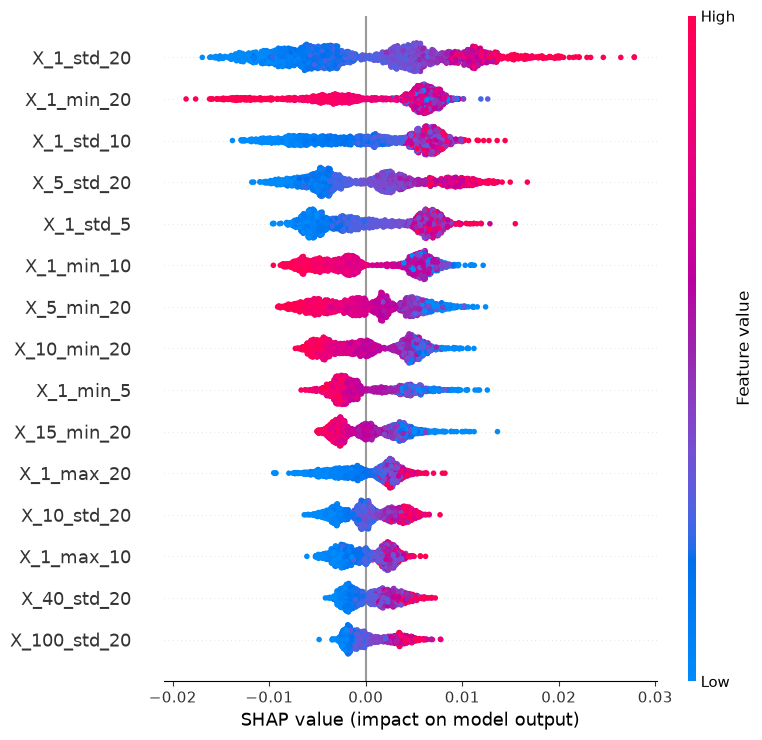


Топ-5 признаков по среднему |SHAP|:
  X_1_std_20           0.00732  (статистика)
  X_1_min_20           0.00582  (статистика)
  X_1_std_10           0.00549  (статистика)
  X_5_std_20           0.00514  (статистика)
  X_1_std_5            0.00490  (статистика)

Красные точки на beeswarm - высокое значение признака; сдвиг вправо повышает P(рост > 2%).
Mean |SHAP| показывает силу влияния, но не его направление и не причинность.


In [63]:
# ══════════════════════════════════════════════════════════════════════════════
# SHAP-интерпретация лучшей модели
#
# TreeSHAP стоит O(деревья x листья x глубина^2) на наблюдение. Для леса из
# 413 деревьев глубины 8 это ~19 мс на строку, то есть ~35 минут на все
# 109 тыс. строк теста. Для графика важности и beeswarm столько наблюдений не
# нужно: оценка среднего |SHAP| по 2000 стратифицированным строкам отличается
# от полной в третьем знаке. Считаем на подвыборке - секунды вместо получаса.
# ══════════════════════════════════════════════════════════════════════════════
from matplotlib.patches import Patch

SHAP_SAMPLE = 2000

best_model_obj = best['model']  # primary RF base, как в экономическом сравнении

# Pipeline - берём сам классификатор и подаём ему масштабированные признаки
if isinstance(best_model_obj, Pipeline):
    clf_for_shap = best_model_obj[-1]
    steps = best_model_obj.named_steps
    X_shap_full = (pd.DataFrame(steps['scaler'].transform(X_test),
                                columns=FEATURE_COLS, index=X_test.index)
                   if 'scaler' in steps else X_test.copy())
else:
    clf_for_shap = best_model_obj
    X_shap_full = X_test.copy()

model_type = type(clf_for_shap).__name__
print(f'Модель для SHAP: {model_type} | признаков: {len(FEATURE_COLS)}')

# ── Стратифицированная подвыборка теста ──────────────────────────────────────
y_test_arr = y_test.to_numpy()
rng_shap = np.random.default_rng(SEED)

if len(y_test_arr) > SHAP_SAMPLE:
    shap_idx = np.sort(np.concatenate([
        rng_shap.choice(np.flatnonzero(y_test_arr == c),
                        size=round(SHAP_SAMPLE * (y_test_arr == c).mean()),
                        replace=False)
        for c in np.unique(y_test_arr)
    ]))
else:
    shap_idx = np.arange(len(y_test_arr))

X_shap = X_shap_full.iloc[shap_idx]
print(f'Подвыборка: {len(shap_idx):,} из {len(y_test_arr):,} строк '
      f'(доля класса 1: {y_test_arr[shap_idx].mean():.3f} против '
      f'{y_test_arr.mean():.3f} на полной)')

# ── Расчёт SHAP ──────────────────────────────────────────────────────────────
TREE_MODELS = ('RandomForestClassifier', 'GradientBoostingClassifier',
               'HistGradientBoostingClassifier', 'XGBClassifier',
               'LGBMClassifier', 'DecisionTreeClassifier')

t_shap = time.time()
if model_type in TREE_MODELS:
    explainer = shap.TreeExplainer(clf_for_shap)
    raw = explainer.shap_values(X_shap, check_additivity=False)
elif model_type == 'LogisticRegression':
    # Для линейной модели SHAP считается аналитически - доли секунды
    explainer = shap.LinearExplainer(clf_for_shap, X_shap_full.iloc[shap_idx])
    raw = explainer.shap_values(X_shap)
else:
    # KernelExplainer - последнее средство, поэтому выборка ещё меньше
    background = shap.kmeans(X_shap_full, 50)
    explainer = shap.KernelExplainer(clf_for_shap.predict_proba, background)
    raw = explainer.shap_values(X_shap.iloc[:200], nsamples=100)
    X_shap = X_shap.iloc[:200]

# Приведение к 2D (n_samples, n_features) для класса 1
if isinstance(raw, list):
    sv = raw[1] if len(raw) == 2 else raw[0]
elif raw.ndim == 3:
    sv = raw[:, :, 1] if raw.shape[2] == 2 else raw[:, :, 0]
else:
    sv = raw

assert sv.shape == (len(X_shap), len(FEATURE_COLS)), (
    f'Неожиданная форма SHAP: {sv.shape}, ожидалось '
    f'{(len(X_shap), len(FEATURE_COLS))}')
print(f'SHAP посчитан за {time.time() - t_shap:.1f} с')

# ── График 1: глобальная важность ────────────────────────────────────────────
feat_importance = (pd.Series(np.abs(sv).mean(axis=0), index=FEATURE_COLS)
                   .sort_values(ascending=True).tail(30))

# Раньше цвет задавался по подстрокам 'Momentum'/'Return', которых в именах
# признаков нет - все столбцы выходили одного цвета, а легенда вводила в
# заблуждение. Разделяем базовые относительные доходности X_k и производные
# от них скользящие статистики.
is_base = [f in FEAT_COLS for f in feat_importance.index]
colors = ['#2ecc71' if b else '#3498db' for b in is_base]

fig, ax = plt.subplots(figsize=(10, 8))
feat_importance.plot(kind='barh', ax=ax, color=colors, edgecolor='white',
                     alpha=0.85)
ax.set_title(f'SHAP: глобальная важность признаков (Mean |SHAP|, '
             f'{len(X_shap):,} наблюдений)', fontsize=13)
ax.set_xlabel('Средний |SHAP value|')
ax.legend(handles=[Patch(facecolor='#2ecc71', label='Базовые X_k'),
                   Patch(facecolor='#3498db', label='Скользящие статистики')])
plt.tight_layout()
plt.savefig(FIG_DIR / 'shap_feature_importance.png', dpi=120,
            bbox_inches='tight')
plt.show()

# ── График 2: beeswarm ───────────────────────────────────────────────────────
print('\nSHAP Summary Plot (распределение влияния каждого признака):')
shap.summary_plot(sv, X_shap, feature_names=FEATURE_COLS, show=False,
                  plot_type='dot', max_display=15)
plt.tight_layout()
plt.savefig(FIG_DIR / 'shap_beeswarm.png', dpi=120, bbox_inches='tight')
plt.show()

# ── Интерпретация ────────────────────────────────────────────────────────────
top = feat_importance.tail(5).iloc[::-1]
print('\nТоп-5 признаков по среднему |SHAP|:')
for name, val in top.items():
    kind = 'базовый' if name in FEAT_COLS else 'статистика'
    print(f'  {name:<20} {val:.5f}  ({kind})')
print('\nКрасные точки на beeswarm - высокое значение признака; '
      'сдвиг вправо повышает P(рост > 2%).')
print('Mean |SHAP| показывает силу влияния, но не его направление и '
      'не причинность.')

SHAP объясняет **ту же базовую конфигурацию RF**, что используется в
экономическом опыте, на 2 000 тестовых наблюдений (после фиксации модели).
Средний |SHAP| показывает силу, не знак и не причинность.
Знак читается по текущему beeswarm. Нельзя заранее называть сигнал
реверсальным или делать вывод «покупать падение» из одного ранга важности.
SHAP помогает интерпретировать факторную экспозицию, но не доказывает
экономическое преимущество формы окна.


In [64]:
print('СВОДКА НОВОГО ПРОГОНА ДЛЯ СТАТЬИ')
print('Конфигурация:',config)
print('Запрошено:',n_symbols_file,'загружено:',price_raw.Symbol.nunique(),
      'пригодно для модели:',daily_df.Symbol.nunique(),'строк:',len(daily_df))
print('Класс 0:',1-daily_df.Target.mean(),'класс 1:',daily_df.Target.mean())
display(funnel_df)
display(cv_results_df.drop(columns='folds'))
display(sw_results_df)
display(comparison_df[main_cols])
display(alpha_tests)
display(overlap_tests)
print('ANOVA BH q<.05:',int((fisher_df.q_BH<.05).sum()))
print('Значимых пар алгоритмов по двум приближённым критериям:',int(sig_df['Значимо'].sum()))
print('Численные утверждения статьи обновлять только из ЭТОГО прогона.')
(CACHE_DIR/'run_completed.json').write_text(json.dumps({'status':'completed','config':config,
    'loaded':int(price_raw.Symbol.nunique()),'eligible':int(daily_df.Symbol.nunique()),
    'rows':len(daily_df)},indent=2),encoding='utf-8')


СВОДКА НОВОГО ПРОГОНА ДЛЯ СТАТЬИ
Конфигурация: {'oos_start': '2022-06-02', 'oos_end': '2024-11-22', 'label_days': 10, 'holding': [10, 21], 'top_k': 10, 'commission': 0.001, 'train_days': 253, 'gap_days': 10, 'step_days': 21, 'seed': 42, 'bootstrap': 2000, 'block_days': 21, 'model': 'Random Forest', 'price': 'Close', 'auto_adjust': False, 'execution_lag': 1, 'min_model_days': 0}
Запрошено: 502 загружено: 484 пригодно для модели: 481 строк: 1052930
Класс 0: 0.5167114623004379 класс 1: 0.48328853769956215


,Шаг,Тикеров,Причина отсева
0,Запрошено фиксированных тикеров,502,снимок состава 2024
1,Загружены непустые истории,484,см. manifest
2,Есть 273 признака и полный таргет,481,IPO/пропуски/прогрев


,Модель,CV ROC-AUC (mean),CV ROC-AUC (std)
0,Random Forest,0.585377,0.009782
1,Gradient Boosting,0.583806,0.010530
2,XGBoost,0.582444,0.009166
3,Logistic Regression,0.578623,0.012347
4,FLAML AutoML,0.577660,0.013915
5,KNN,0.533664,0.006003


,Модель,ROC-AUC (mean),ROC-AUC (std),ROC-AUC (пул)
1,Random Forest,0.560581,0.045421,0.559941
3,Gradient Boosting,0.552471,0.044836,0.554823
2,XGBoost,0.549175,0.042067,0.551563
0,Logistic Regression,0.542809,0.045114,0.546862
4,KNN,0.520744,0.019460,0.523205


,jensen_alpha,jensen_p,beta,information_ratio,total_return,alpha_vs_index,alpha_vs_equal_weight,sharpe,max_drawdown,profit_factor,avg_turnover,one_way_turnover,n_rebalances
static,-0.084216,0.556016,1.428503,-0.064347,0.22892,-0.200239,-0.167467,0.413834,-0.299748,1.069418,2.005162,1.002581,62
expanding,-0.017628,0.901876,1.431275,0.192647,0.447775,0.018616,0.051388,0.606878,-0.236769,1.135374,2.00777,1.003885,62
sliding,-0.062499,0.631755,1.371746,-0.015812,0.282873,-0.146286,-0.113515,0.470811,-0.237222,1.09639,2.005774,1.002887,62


,comparison,holding,block,diff,ci_low,ci_high,p,n_periods,n_boot,p_Holm
0,expanding - sliding,10,10,0.164903,-0.422418,0.961865,0.529235,623,2000,1.0
1,expanding - static,10,10,0.218855,-0.101330,0.757464,0.227386,623,2000,1.0
2,expanding - sliding,21,10,0.104328,-0.561520,1.062415,0.724638,623,2000,1.0
3,expanding - static,21,10,0.161890,-0.224416,0.750672,0.386307,623,2000,1.0
4,expanding - sliding,10,21,0.164903,-0.412271,0.933347,0.521239,623,2000,1.0
5,expanding - static,10,21,0.218855,-0.094166,0.708806,0.216392,623,2000,1.0
6,expanding - sliding,21,21,0.104328,-0.608834,1.052310,0.754123,623,2000,1.0
7,expanding - static,21,21,0.161890,-0.209890,0.822002,0.412294,623,2000,1.0
8,expanding - sliding,10,42,0.164903,-0.314614,0.915384,0.501749,623,2000,1.0
9,expanding - static,10,42,0.218855,-0.091459,0.778948,0.216392,623,2000,1.0


,scheme,comparison,block,diff,ci_low,ci_high,p,n_periods,n_boot,p_Holm
0,static,hold21 - hold10,10,0.090262,-0.153870,0.397116,0.436282,623,2000,1.000000
1,static,hold21 - hold10,21,0.090262,-0.172824,0.379522,0.426287,623,2000,1.000000
2,static,hold21 - hold10,42,0.090262,-0.180969,0.369799,0.450275,623,2000,1.000000
3,expanding,hold21 - hold10,10,0.174502,-0.092979,0.611431,0.247876,623,2000,1.000000
4,expanding,hold21 - hold10,21,0.174502,-0.120556,0.562644,0.239380,623,2000,1.000000
5,expanding,hold21 - hold10,42,0.174502,-0.120879,0.561249,0.242379,623,2000,1.000000
6,sliding,hold21 - hold10,10,0.249566,-0.015585,0.699464,0.122939,623,2000,0.908546
7,sliding,hold21 - hold10,21,0.249566,0.009516,0.651510,0.100950,623,2000,0.908546
8,sliding,hold21 - hold10,42,0.249566,0.024743,0.640136,0.101949,623,2000,0.908546


ANOVA BH q<.05: 259
Значимых пар алгоритмов по двум приближённым критериям: 3
Численные утверждения статьи обновлять только из ЭТОГО прогона.


519

# 5. Выводы

## 5.1 Что проверяет новый эксперимент

Сохранены исходные 13 доходностей относительно индекса и 260 rolling-статистик,
порог 2 п.п., 10-дневное событие достижения и pooled-модели.
В таблицах раздела 3.7 форма окна сравнивается при одинаковом расписании
переобучения, purge, модели, OOS-строках и правилах исполнения.
Удержание 21 день относится к исполнению **10-дневного** сигнала.

## 5.2 Интерпретация результатов

Числа выводятся в предыдущей ячейке. До успешного полного запуска нельзя
утверждать, что новая вселенная повторяет значения ROC-AUC/альфы/p статьи.
Отсутствие значимости не доказывает равенства стратегий. Больше бумаг
не означает больше независимых рыночных периодов.
Jensen alpha (rf=0, HAC) и information ratio приводятся вместе с beta;
разность накопленных доходностей — отдельная, не скорректированная на риск метрика.

## 5.3 Явно обозначенные изменения методики

1. yfinance вместо дефектной выгрузки; фиксированный снимок 502, явный audit.
2. Удалён дополнительный фильтр ещё 270 готовых дней; нужны 273 признака и
   полностью известная 10-дневная метка. Хвост с неполным будущим исключён.
3. Календарь индекса и purge по датам вместо разбиения строк панели и gap=260.
4. Новый expanding walk-forward с обновлением каждые 21 день.
5. Сигнал t → исполнение t+1; ежедневные equity/просадка; одинаковый конец окна;
   нет сделок с выходом за OOS, нет отбора по известной будущей доходности.
6. ANOVA+BH, >=2000 bootstrap смежных блоков; общий дневной paired design.
7. Primary RF и SHAP одной конфигурации, выбор порога только на train.

## 5.4 Ограничения и публикация

- Исторический состав индекса не восстановлен: survivorship bias остаётся.
- IPO/делистинг/переименования: наличие 502 имён не гарантирует 502 пригодные
  истории; считать по `download_manifest.csv` и `model_eligibility.csv`.
- CAPM использует rf=0 и ценовой индекс без дивидендов. Это приближение,
  не Fama–French+momentum. Для такого теста нужен отдельный набор факторов.
- Текущая Yahoo-история может пересматриваться; кэш, даты, SHA256 и версии
  библиотек необходимы для воспроизводимости.
- Издержки: комиссия 0.1% на каждую сторону; стресс 3x/5x; нет проскальзывания,
  влияния на рынок и стоимости шорта. Повторная покупка платит полный оборот.
- Перекрывающиеся портфели имеют cash на начальной/конечной границе;
  они проверяют исполнение, а не чистое влияние горизонта метки.
- Настройки LR/RF/XGB из final — legacy-конфигурации, если поиск не запущен;
  они не выдаются за оптимальные на новой вселенной. HistGB/KNN — baseline,
  вычислительный бюджет и отсутствие поиска не доказывают их неполноценность.
- Bootstrap и Nadeau–Bengio не гарантируют корректность при произвольной
  нестационарности; показана чувствительность к длине блока 10/21/42.

Код можно подготовить для GitHub вместе с новым модулем `src/review_revision.py`,
описанием окружения и конфигурацией. Решение о публикации остаётся у автора;
push в рамках этой работы запрещён и не выполняется. PDF и рыночные выгрузки
не следует включать без проверки права на распространение.
